# Mini-projet Séries Temporelles — TEK-UP 2026

**Modélisation, prévision et diagnostic de la série multidimensionnelle XOM / XLE**

Notebook principal en Python : il reproduit l'étude de bout en bout, sans intervention manuelle autre que l'exécution des cellules.
La logique est dans `src/` ; ce notebook appelle les fonctions et interprète les résultats.

| Partie | Langage |
| --- | --- |
| Sections 1–3 (données, EDA, ARIMA, VAR/VECM, GARCH) | Python **et** R (`notebooks/classical_R.Rmd`) |
| Section 4 (LSTM/GRU, hybride) et extensions | **Python uniquement** |

In [1]:
# Racine du projet retrouvée depuis le dossier courant : le notebook marche lancé
# depuis notebooks/ (Jupyter, nbconvert) comme depuis la racine (VS Code).
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.yaml").exists())
sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from src.utils import load_config, set_seed, print_versions, save_fig, save_table
from src import data

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", "{:.4f}".format)

# Seed fixée dès le début : toute la suite (bootstrap, réseaux) devient reproductible.
set_seed()
# Versions affichées en tête : exigence de reproductibilité (cahier §9.1).
print_versions()

python         3.11.9
numpy          1.26.4
pandas         2.2.3
scipy          1.13.1
statsmodels    0.14.4
pmdarima       2.0.4
arch           7.0.0
scikit-learn   1.5.2
tensorflow     2.16.2
prophet        1.1.6
yfinance       0.2.66
matplotlib     3.9.2
seaborn        0.13.2
pyyaml         6.0.2


## 1. Données

### 1.1 Choix de la thématique

Nous retenons l'**option A — Finance** avec le couple **XOM (ExxonMobil) / XLE (Energy Select Sector SPDR ETF)** : une action et son indice sectoriel partagent un facteur commun, ce qui permet d'étudier cointégration et volatilité conditionnelle sur des épisodes de crise identifiables (krach pétrolier 2016, COVID 2020, guerre en Ukraine 2022).
Le **Brent** (`BZ=F`, contrat à terme ICE) est récupéré comme variable exogène pour les extensions (section 7).

Tous les paramètres sont lus dans `config.yaml` :

In [2]:
cfg = load_config()
pd.Series({
    "Source": cfg["data"]["source"],
    "Tickers": ", ".join(cfg["data"]["tickers"].values()),
    "Variable de prix": cfg["data"]["price_column"],
    "Période": f'{cfg["data"]["start"]} → {cfg["data"]["end"]} (incluse)',
    "Fréquence": "journalière, jours de bourse",
    "Split train": cfg["split"]["train_ratio"],
    "Seed": cfg["seed"],
}, name="paramètre").to_frame()

,paramètre
Source,Yahoo Finance
Tickers,"XOM, XLE, BZ=F"
Variable de prix,Adj Close
Période,2016-01-01 → 2025-12-31 (incluse)
Fréquence,"journalière, jours de bourse"
Split train,0.9000
Seed,42


### 1.2 Import des données

`data.load_raw()` lit d'abord le cache `data/raw/*.csv` et ne télécharge depuis Yahoo Finance (`yfinance`, `auto_adjust=False`) que si le fichier est absent.
Ce choix est essentiel pour la reproductibilité : Yahoo **recalcule l'`Adj Close` rétroactivement** à chaque nouveau dividende, si bien qu'un téléchargement fait un autre jour donnerait des prix ajustés légèrement différents. Le cache versionné fige l'échantillon étudié.
Pour forcer un nouveau téléchargement : `data.load_raw(refresh=True)`.

In [3]:
raw = data.load_raw()
for role, df in raw.items():
    print(f"{role:<10} {cfg['data']['tickers'][role]:<5} {df.shape[0]} lignes × {df.shape[1]} colonnes")

target     XOM   2514 lignes × 6 colonnes
sector     XLE   2514 lignes × 6 colonnes
exogenous  BZ=F  2515 lignes × 6 colonnes


### 1.3 Aperçu des données brutes

In [4]:
# Premières et dernières lignes de XOM : vérifie les bornes de la période et la cohérence des colonnes.
pd.concat([raw["target"].head(), raw["target"].tail()])

,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
2016-01-04,77.5000,77.9400,76.4600,77.4600,49.0023,20400100
2016-01-05,77.1900,78.1400,76.9200,78.1200,49.4198,11993500
2016-01-06,76.6400,77.6400,76.5900,77.4700,49.0086,18826900
2016-01-07,76.0600,77.9900,75.9000,76.2300,48.2242,21263800
2016-01-08,76.3500,76.6500,74.5000,74.6900,47.2500,19033600
2025-12-24,119.3300,120.0500,119.1200,119.2200,116.8754,6137400
2025-12-26,118.8900,119.5500,118.5300,119.1100,116.7676,8066100
2025-12-29,120.1500,121.3000,119.4000,120.5300,118.1596,14782500
2025-12-30,121.1000,121.8000,120.6300,120.9900,118.6106,11150500


In [5]:
pd.concat([raw["sector"].head(), raw["sector"].tail()])

,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
2016-01-04,30.0800,30.3900,29.6500,30.1500,19.6958,43617400
2016-01-05,30.1300,30.3000,29.7950,30.2650,19.7709,31058400
2016-01-06,29.5500,29.6100,28.8550,29.1000,19.0099,53924200
2016-01-07,28.5350,29.1900,28.2700,28.3900,18.5461,56163800
2016-01-08,28.6300,28.6950,27.9200,28.0250,18.3076,38454200
2025-12-24,44.4200,44.5600,44.3100,44.3700,43.5077,11293900
2025-12-26,44.3200,44.4400,43.9900,44.2000,43.3410,17884500
2025-12-29,44.5100,44.7400,44.2900,44.6200,43.7529,31352100
2025-12-30,44.8000,45.0900,44.8000,44.9600,44.0863,18654700


In [6]:
pd.concat([raw["exogenous"].head(), raw["exogenous"].tail()])

,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
2016-01-04,37.4000,38.9900,36.7800,37.2200,37.2200,41288
2016-01-05,37.3200,37.5700,36.2500,36.4200,36.4200,29327
2016-01-06,36.7200,36.7200,34.1400,34.2300,34.2300,43019
2016-01-07,34.5200,34.7300,32.1800,33.7500,33.7500,44381
2016-01-08,33.8000,34.7300,32.7900,33.5500,33.5500,39985
2025-12-24,62.4300,62.7200,62.0200,62.2400,62.2400,14966
2025-12-26,62.3500,62.6900,60.5900,60.6400,60.6400,9687
2025-12-29,61.0400,62.1500,60.9500,61.9400,61.9400,9170
2025-12-30,61.7000,62.3300,61.5100,61.9200,61.9200,30567


**Ajustements appliqués par le fournisseur.** Sur Yahoo Finance, `Close` est déjà ajusté des **splits** ; `Adj Close` l'est en plus des **dividendes** (réinvestis). C'est donc `Adj Close` qui mesure le rendement total réellement obtenu par un investisseur, et c'est la variable retenue.
L'écart entre les deux colonnes se lit sur la première ligne de XOM : `Close` = 77,46 $ contre `Adj Close` = 49,00 $ le 2016-01-04, soit dix ans de dividendes cumulés réintégrés dans l'historique. Sur la dernière ligne (2025-12-31), l'écart n'est plus que de 120,34 $ contre 117,97 $ : l'ajustement diminue quand on se rapproche de la date de téléchargement.
Pour le Brent (contrat à terme), il n'y a pas de dividende : `Close` et `Adj Close` sont identiques. La série `BZ=F` raccorde des contrats successifs (échéance la plus proche) : un changement de contrat peut créer un petit saut de prix qui n'est pas un vrai rendement. C'est sans conséquence pour les sections 2 à 6, où le Brent n'intervient pas, et sera rappelé dans la section 7.

### 1.4 Valeurs manquantes et alignement des calendriers

In [7]:
miss = data.missing_report(raw)
save_table(miss, "tab01_manquants")
miss.T

rôle,target,sector,exogenous
ticker,XOM,XLE,BZ=F
début,2016-01-04,2016-01-04,2016-01-04
fin,2025-12-31,2025-12-31,2025-12-31
observations,2514,2514,2515
NaN Adj Close,0,0,0
NaN toutes colonnes,0,0,0
dates dupliquées,0,0,0
jours communs XOM/XLE absents,0,0,2
jours en plus du calendrier commun,0,0,3


In [8]:
# Jours précis où les calendriers diffèrent : on vérifie qu'il s'agit de jours fériés, pas d'erreurs.
common = raw["target"].index.intersection(raw["sector"].index)
brent = raw["exogenous"].index
print("Jours de bourse XOM/XLE sans cotation du Brent :", [d.date() for d in common.difference(brent)])
print("Cotations du Brent hors calendrier XOM/XLE     :", [d.date() for d in brent.difference(common)])

Jours de bourse XOM/XLE sans cotation du Brent : [datetime.date(2016, 10, 10), datetime.date(2016, 11, 11)]
Cotations du Brent hors calendrier XOM/XLE     : [datetime.date(2023, 11, 23), datetime.date(2025, 1, 9), datetime.date(2025, 7, 4)]


**Interprétation.**
- XOM et XLE ont exactement le même calendrier : **2 514 jours de bourse** du 2016-01-04 au 2025-12-31, sans aucune valeur manquante ni date dupliquée. La jointure interne ne supprime donc aucune observation.
- Le Brent cote sur ICE, avec un calendrier un peu différent :
  - il **manque 2 jours** de bourse américains (10 octobre et 11 novembre 2016) ;
  - il a **3 cotations en plus** les jours de fermeture de New York (Thanksgiving 2023, 9 janvier 2025 — journée de deuil national pour Jimmy Carter — et 4 juillet 2025).
- Le Brent est rattaché au calendrier XOM/XLE par jointure à gauche : les 3 jours en plus sont écartés, les 2 jours absents restent `NaN`.

**Pourquoi pas de remplissage (`ffill`) ?** Le calendrier boursier est irrégulier par nature (week-ends, jours fériés). Recopier le prix de la veille créerait des rendements **exactement nuls** qui n'ont jamais existé : ils réduiraient artificiellement la variance et biaiseraient l'estimation des modèles GARCH. Les modèles reçoivent donc la suite des jours de bourse comme un index positionnel ; les dates ne servent qu'aux graphiques et à l'interprétation.
Les 2 `NaN` du Brent ne concernent que la variable exogène, utilisée seulement en section 7 : ils seront traités à ce moment-là (suppression des 2 jours dans le modèle concerné).

### 1.5 Variables dérivées

`data.build_features()` construit, pour chaque actif, le log-prix, le log-rendement en %, la volatilité réalisée sur 21 jours annualisée et la moyenne mobile 50 jours (indicateurs techniques exigés par le cahier §1.1).
Toutes les fenêtres glissantes ne regardent que le passé : la valeur à la date *t* n'utilise que des données jusqu'à *t*, ce qui exclut toute fuite d'information du test vers le train.

In [9]:
var_table = data.variables_table()
save_table(var_table, "tab02_variables", index=False)
# Affichage sans troncature : les définitions sont reprises telles quelles dans le rapport.
var_table.style.hide(axis="index").set_properties(**{"text-align": "left"})

variable,rôle,définition,unité
XOM_price,target,"Prix de clôture ajusté (dividendes, splits) de XOM",USD
XOM_logp,target,Log-prix l_t = ln(P_t),log(USD)
XOM_ret,target,Log-rendement r_t = 100 × ln(P_t / P_{t-1}),%
XOM_vol21,target,Volatilité réalisée : √252 × écart-type glissant de r_t sur 21 jours,% annualisé
XOM_ma50,target,Moyenne mobile de P_t sur 50 jours,USD
XLE_price,sector,"Prix de clôture ajusté (dividendes, splits) de XLE",USD
XLE_logp,sector,Log-prix l_t = ln(P_t),log(USD)
XLE_ret,sector,Log-rendement r_t = 100 × ln(P_t / P_{t-1}),%
XLE_vol21,sector,Volatilité réalisée : √252 × écart-type glissant de r_t sur 21 jours,% annualisé
XLE_ma50,sector,Moyenne mobile de P_t sur 50 jours,USD


In [10]:
panel = data.build_features(data.align_prices(raw))
print(f"Panel : {panel.shape[0]} dates × {panel.shape[1]} variables, "
      f"du {panel.index.min().date()} au {panel.index.max().date()}")
print(f"Type d'index : {type(panel.index).__name__}")
# Fréquence : jours ouvrés théoriques vs jours de bourse réels (les fériés manquent).
bdays = pd.bdate_range(panel.index.min(), panel.index.max())
print(f"Fréquence déclarée : jours de bourse (config.yaml : '{cfg['data']['frequency']}')")
print(f"Jours ouvrés théoriques : {len(bdays)} ; jours de bourse réels : {len(panel)} ; "
      f"jours fériés de bourse : {len(bdays.difference(panel.index))}")
panel.head(3)

Panel : 2514 dates × 15 variables, du 2016-01-04 au 2025-12-31
Type d'index : DatetimeIndex
Fréquence déclarée : jours de bourse (config.yaml : 'B')
Jours ouvrés théoriques : 2608 ; jours de bourse réels : 2514 ; jours fériés de bourse : 94


,XOM_price,XOM_logp,XOM_ret,XOM_vol21,XOM_ma50,XLE_price,XLE_logp,XLE_ret,XLE_vol21,XLE_ma50,BZ=F_price,BZ=F_logp,BZ=F_ret,BZ=F_vol21,BZ=F_ma50
Date,,,,,,,,,,,,,,,
2016-01-04,49.0023,3.8919,NaN,NaN,NaN,19.6958,2.9804,NaN,NaN,NaN,37.2200,3.6168,NaN,NaN,NaN
2016-01-05,49.4198,3.9004,0.8484,NaN,NaN,19.7709,2.9842,0.3807,NaN,NaN,36.4200,3.5951,-2.1728,NaN,NaN
2016-01-06,49.0086,3.8920,-0.8355,NaN,NaN,19.0099,2.9450,-3.9254,NaN,NaN,34.2300,3.5331,-6.2016,NaN,NaN


**Fréquence de la série.** La série est journalière au rythme des **jours de bourse** du NYSE. On ne fixe pas `freq="B"` sur l'index pandas : cela réinsérerait les jours fériés de bourse (Thanksgiving, Noël, etc.) sous forme de lignes vides, qu'il faudrait ensuite remplir artificiellement — exactement ce qu'on a écarté plus haut.
L'index reste donc un `DatetimeIndex` des dates réellement cotées. La fréquence est déclarée dans `config.yaml` et rappelée aux modèles : par exemple la saisonnalité hebdomadaire testée en SARIMA aura s = 5 jours de bourse, et l'annualisation de la volatilité se fait avec 252 jours.

In [11]:
# NaN attendus en début de série (fenêtres glissantes) : à distinguer de vrais manquants.
na = panel.isna().sum().rename("NaN").to_frame()
na["origine"] = ["aucun" if n == 0 else "" for n in na["NaN"]]
w, m = cfg["features"]["realized_vol_window"], cfg["features"]["moving_average_window"]
for c in na.index:
    if c.startswith(("XOM", "XLE")):
        na.loc[c, "origine"] = {"_ret": "1er jour (pas de veille)", "_vol21": f"{w} premiers jours (fenêtre)",
                                "_ma50": f"{m - 1} premiers jours (fenêtre)"}.get(c[c.index("_"):], "aucun")
    elif c.endswith(("_price", "_logp")):
        na.loc[c, "origine"] = "2 jours sans cotation du Brent"
    else:
        na.loc[c, "origine"] = "début de série + 2 jours sans cotation du Brent, propagés par la fenêtre"
na

,NaN,origine
XOM_price,0,aucun
XOM_logp,0,aucun
XOM_ret,1,1er jour (pas de veille)
XOM_vol21,21,21 premiers jours (fenêtre)
XOM_ma50,49,49 premiers jours (fenêtre)
XLE_price,0,aucun
XLE_logp,0,aucun
XLE_ret,1,1er jour (pas de veille)
XLE_vol21,21,21 premiers jours (fenêtre)
XLE_ma50,49,49 premiers jours (fenêtre)


**Lecture.** Pour XOM et XLE, les `NaN` sont uniquement mécaniques : 1 pour le rendement (pas de veille le premier jour), 21 pour la volatilité réalisée (le premier écart-type sur 21 rendements n'est disponible qu'au 22ᵉ jour) et 49 pour la moyenne mobile 50 jours.
Pour le Brent, chacun des 2 jours absents se propage : il manque 2 prix, mais 5 rendements (le jour absent et le lendemain, plus le premier jour), et davantage pour les variables fenêtrées.

### 1.6 Découpage chronologique train / test (90 / 10)

La coupure se fait sur l'ordre des dates, jamais par tirage aléatoire : le test doit être strictement postérieur au train, comme dans une vraie situation de prévision. Toute normalisation (section 4) sera ajustée sur le train uniquement.

In [12]:
train, test = data.train_test_split_time(panel)
split = pd.DataFrame({
    "observations": [len(train), len(test)],
    "part": [len(train) / len(panel), len(test) / len(panel)],
    "début": [train.index.min().date(), test.index.min().date()],
    "fin": [train.index.max().date(), test.index.max().date()],
}, index=["train", "test"])
save_table(split, "tab03_split")

# Sauvegarde des séries préparées : les sections suivantes et le notebook R repartent de ces fichiers.
_ = data.prepare(save=True)
split

,observations,part,début,fin
train,2262,0.8998,2016-01-04,2024-12-27
test,252,0.1002,2024-12-30,2025-12-31


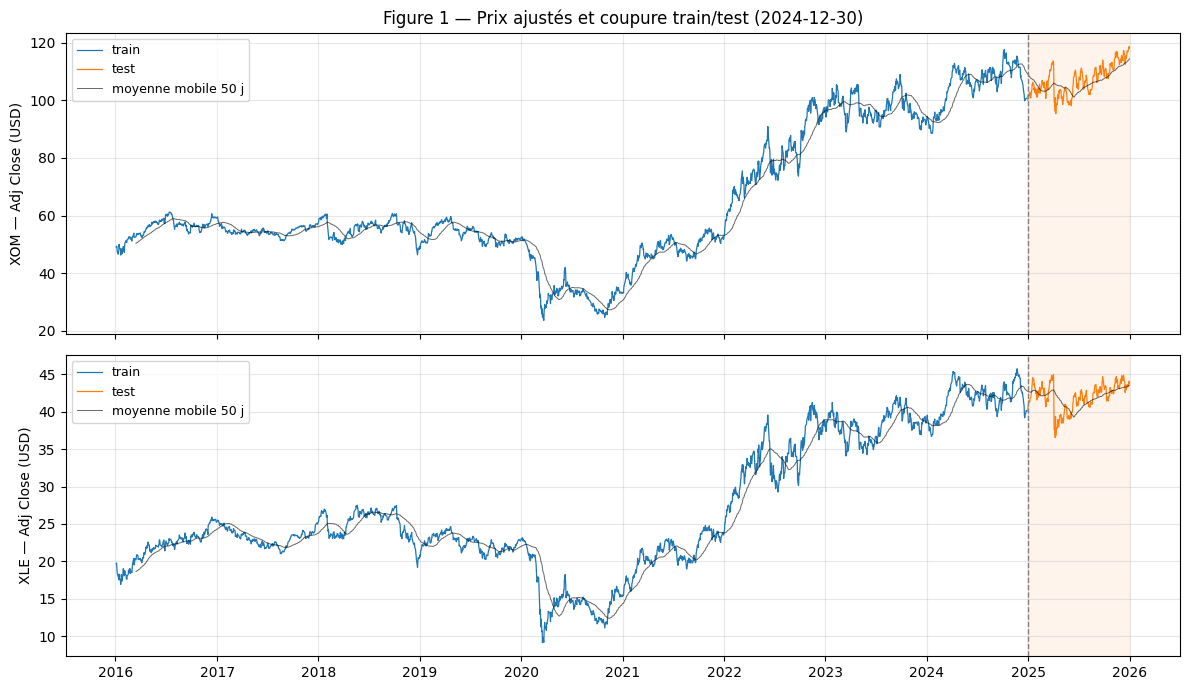

In [13]:
cut = test.index[0]
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for ax, tk in zip(axes, ["XOM", "XLE"]):
    ax.plot(train.index, train[f"{tk}_price"], color="tab:blue", lw=0.9, label="train")
    ax.plot(test.index, test[f"{tk}_price"], color="tab:orange", lw=0.9, label="test")
    ax.plot(panel.index, panel[f"{tk}_ma50"], color="black", lw=0.7, alpha=0.6, label="moyenne mobile 50 j")
    ax.axvspan(cut, panel.index[-1], color="tab:orange", alpha=0.08)
    ax.axvline(cut, color="grey", ls="--", lw=1)
    ax.set_ylabel(f"{tk} — Adj Close (USD)")
    ax.legend(loc="upper left", fontsize=9)
    ax.grid(alpha=0.3)
axes[0].set_title(f"Figure 1 — Prix ajustés et coupure train/test ({cut.date()})")
axes[1].xaxis.set_major_locator(mdates.YearLocator())
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.tight_layout()
save_fig(fig, 1, "prix_train_test")
plt.show()

**Interprétation de la figure 1.**
- **Découpage.** Le train couvre **2 262 jours** (2016-01-04 → 2024-12-27), le test les **252 jours suivants** (2024-12-30 → 2025-12-31), soit environ une année de bourse complète.
- **Évolution des prix.** Les deux séries suivent la même trajectoire générale, avec deux ruptures nettes :
  - l'effondrement de 2020 (COVID, chute de la demande de pétrole) ;
  - la forte hausse de 2021–2022 (reprise puis guerre en Ukraine).

  Le parallélisme visuel entre XOM et XLE (corrélation des rendements journaliers : 0,914 sur toute la période) motive le test de cointégration de la section 3.2.
- **Conséquence pour la modélisation.** Le niveau des prix n'est manifestement pas stationnaire (tendance et ruptures). Les tests ADF/KPSS de la section 2 vérifieront formellement l'ordre d'intégration.
- **Point de vigilance : le test est plus calme que le train.** Le test contient bien un choc (chute brutale début avril 2025, visible sur les deux actifs), mais il est d'une ampleur sans commune mesure avec 2020 :

  | | Train | Test |
  | --- | --- | --- |
  | Écart-type des rendements XOM | 1,78 % | 1,48 % |
  | Volatilité réalisée maximale XOM | 108,9 % | 47,4 % |
  | Volatilité réalisée maximale XLE | 149,9 % | 61,1 % |

  Les erreurs de prévision mesurées sur le test seront donc conditionnelles à ce régime et ne se généraliseront pas automatiquement à une période de crise. On en tiendra compte dans la discussion des limites.

## 2. Analyse exploratoire

**Échantillon utilisé.** Les graphiques descriptifs couvrent toute la période. En revanche, tous les tests et outils qui servent à **choisir un modèle** (statistiques descriptives, ACF/PACF, STL, ADF/KPSS) sont calculés sur le **train uniquement** : identifier un modèle avec des données du test serait une fuite d'information.

In [14]:
from src import eda
from IPython.display import display

TRAIN = train  # 2 262 jours, 2016-01-04 → 2024-12-27
# Épisodes de crise repérés sur la figure 1, réutilisés pour annoter les graphiques.
CRISES = {"COVID-19": ("2020-02-20", "2020-04-30"), "Guerre en Ukraine": ("2022-02-24", "2022-06-30")}

def shade(ax, legend=False):
    for (name, (a, b)), color in zip(CRISES.items(), ["tab:red", "tab:purple"]):
        ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color=color, alpha=0.12, label=name if legend else None)
    ax.axvspan(test.index[0], test.index[-1], color="tab:orange", alpha=0.08, label="test" if legend else None)

### 2.1 Visualisation des séries

Les deux prix n'ont pas la même échelle (XOM ≈ 49 $ et XLE ≈ 20 $ en 2016) : on les ramène en **base 100** au 2016-01-04 pour comparer leurs trajectoires. On trace ensuite les rendements et la volatilité réalisée.

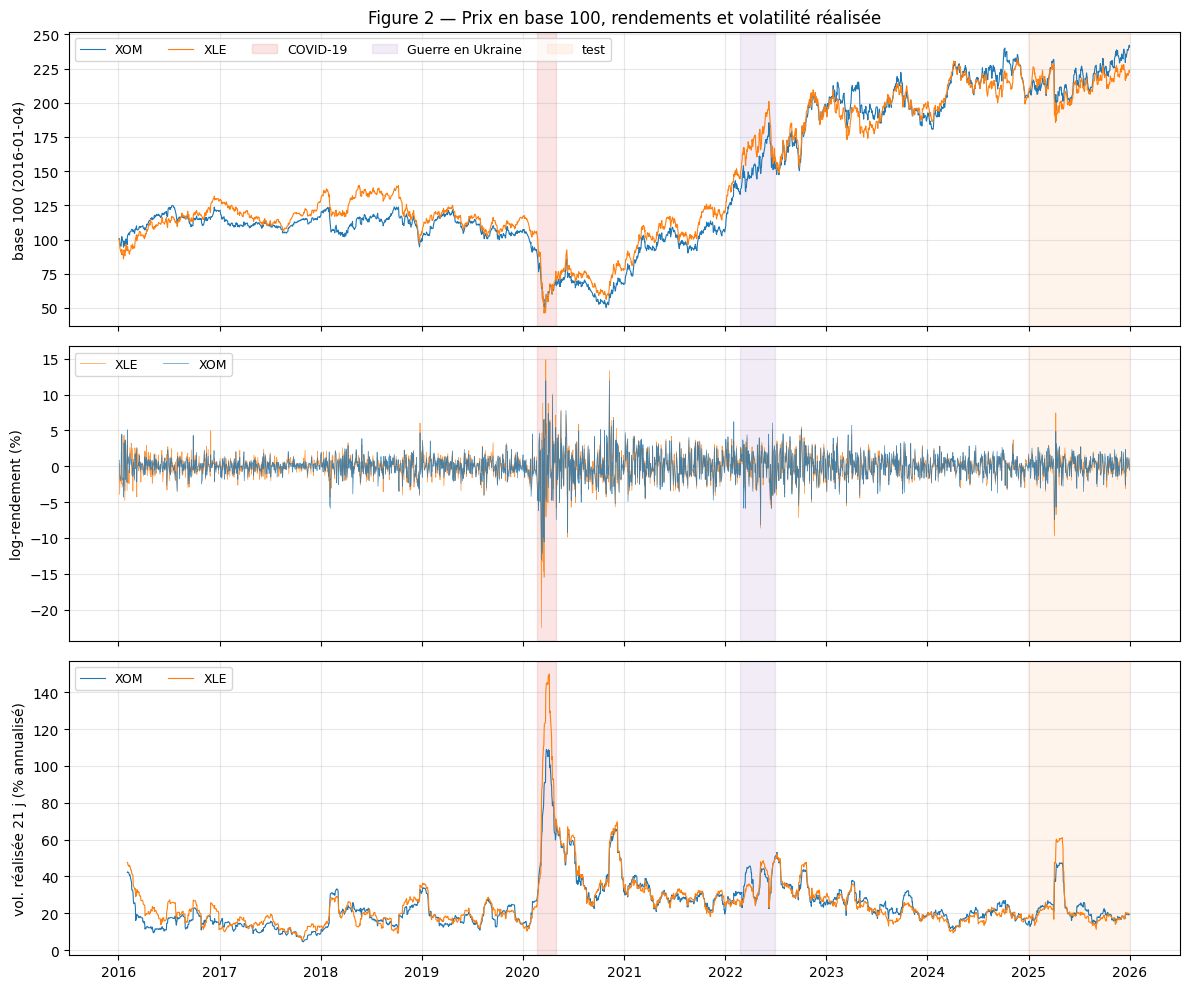

Performance totale 2016-2025 (dividendes réinvestis) : XOM 140.8 %, XLE 122.6 %
Creux et pics de volatilité réalisée :
  XOM : max 108.9 % le 2020-03-26 ; médiane 21.6 %
  XLE : max 149.9 % le 2020-04-06 ; médiane 21.2 %


In [15]:
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
base = panel[["XOM_price", "XLE_price"]] / panel[["XOM_price", "XLE_price"]].iloc[0] * 100
axes[0].plot(base.index, base["XOM_price"], lw=0.8, label="XOM")
axes[0].plot(base.index, base["XLE_price"], lw=0.8, label="XLE")
axes[0].set_ylabel("base 100 (2016-01-04)")
axes[1].plot(panel.index, panel["XLE_ret"], lw=0.5, color="tab:orange", alpha=0.8, label="XLE")
axes[1].plot(panel.index, panel["XOM_ret"], lw=0.5, color="tab:blue", alpha=0.8, label="XOM")
axes[1].set_ylabel("log-rendement (%)")
axes[2].plot(panel.index, panel["XOM_vol21"], lw=0.8, label="XOM")
axes[2].plot(panel.index, panel["XLE_vol21"], lw=0.8, label="XLE")
axes[2].set_ylabel("vol. réalisée 21 j (% annualisé)")
for i, ax in enumerate(axes):
    shade(ax, legend=(i == 0))
    ax.grid(alpha=0.3)
    ax.legend(loc="upper left", fontsize=9, ncol=5)
axes[0].set_title("Figure 2 — Prix en base 100, rendements et volatilité réalisée")
axes[2].xaxis.set_major_locator(mdates.YearLocator())
axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.tight_layout()
save_fig(fig, 2, "series_rendements_volatilite")
plt.show()

perf = (base.iloc[-1] - 100).round(1)
print(f"Performance totale 2016-2025 (dividendes réinvestis) : XOM {perf['XOM_price']} %, XLE {perf['XLE_price']} %")
print("Creux et pics de volatilité réalisée :")
for tk in ["XOM", "XLE"]:
    v = panel[f"{tk}_vol21"]
    print(f"  {tk} : max {v.max():.1f} % le {v.idxmax().date()} ; médiane {v.median():.1f} %")

**Interprétation de la figure 2.**
- **Prix (base 100).** Sur 2016–2025, XOM progresse de **+140,8 %** et XLE de **+122,6 %** (dividendes réinvestis). Les deux trajectoires restent très proches, ce qui est attendu puisque XOM est l'une des plus grosses positions de l'ETF XLE. Deux ruptures se détachent :
  - le **krach de 2020**, où les deux actifs perdent environ la moitié de leur valeur ;
  - la **hausse de 2021–2022**, qui porte les prix à environ 200, soit le double de 2016.

  Ni l'un ni l'autre ne revient vers un niveau moyen fixe : visuellement, les prix ne sont pas stationnaires.
- **Rendements.** Au contraire des prix, ils oscillent autour de zéro sans tendance : ils ont l'allure d'une série stationnaire **en moyenne**. En revanche, leur amplitude varie fortement dans le temps :
  - une phase très calme en 2017 ;
  - une explosion en mars 2020, avec des chutes de −13 % (XOM) et −22,5 % (XLE) en une journée ;
  - une agitation durable en 2020–2022.

  C'est le phénomène de **regroupement de volatilité** (*volatility clustering*) : les fortes variations se suivent, les faibles aussi.
- **Volatilité réalisée.**
  - **Valeurs habituelles.** La médiane est de 21,6 % (XOM) et 21,2 % (XLE).
  - **Pics de mars–avril 2020.** La volatilité monte à **108,9 %** pour XOM (2020-03-26) et **149,9 %** pour XLE (2020-04-06), soit environ cinq fois la normale.
  - **2022.** L'agitation commence avec l'invasion de l'Ukraine (zone violette). Le pic de l'année arrive un peu plus tard (≈ 53 % pour les deux actifs le 2022-07-07) et reste deux à trois fois plus faible qu'en 2020.
  - **Avril 2025, dans le test.** On observe aussi un pic, autour de 50 à 60 %.
- **Conséquences pour la suite.** La moyenne des rendements semble stable, mais leur variance ne l'est pas. Il faudra donc :
  - modéliser le niveau en différences (à confirmer par ADF/KPSS en 2.6) ;
  - modéliser la variance conditionnelle avec un GARCH (section 3.3).

### 2.2 Statistiques descriptives des rendements (train)

Ces statistiques servent aussi d'entrée au prompt LLM de la section 5.

In [16]:
desc = eda.descriptive_stats(TRAIN[["XOM_ret", "XLE_ret"]])
save_table(desc, "tab04_stats_descriptives")
desc

,XOM_ret,XLE_ret
n,2261.0000,2261.0000
moyenne,0.0319,0.0315
écart-type,1.7845,1.9216
variance,3.1846,3.6925
skewness,-0.1630,-0.8902
excès de kurtosis,6.6224,16.4357
min,-13.0391,-22.4910
max,11.9442,14.8741
Jarque-Bera,4141.6970,25747.3428
p-value JB,0.0000,0.0000


**Interprétation des statistiques descriptives (train, 2 261 rendements).**

**Moyenne.** Le rendement moyen est de 0,032 % par jour, soit environ **8 % par an** pour les deux actifs (0,0319 × 252 et 0,0315 × 252). Il est minuscule face à l'écart-type journalier de 1,78 % (XOM) et 1,92 % (XLE), soit une volatilité annualisée de 28,3 % et 30,5 %. La statistique t de la moyenne vaut 0,0319 / (1,7845 / √2 261) ≈ **0,85** pour XOM (0,78 pour XLE) : la moyenne **n'est pas significativement différente de zéro**. Ce calcul suppose des rendements i.i.d. ; il est refait ci-dessous avec un écart-type robuste. On s'attend donc à ce que la constante (dérive) soit non significative dans les modèles ARIMA.

**Asymétrie.**
- Elle est négative pour les deux actifs : les fortes baisses sont plus marquées que les fortes hausses.
- Elle est faible pour XOM (skewness de −0,16) mais nette pour XLE (−0,89).
- Le minimum de XLE (−22,5 %) est bien plus extrême que son maximum (+14,9 %).

**Queues épaisses.** L'excès de kurtosis vaut **6,6** pour XOM et **16,4** pour XLE, contre 0 pour une loi normale. Les rendements extrêmes sont donc beaucoup plus fréquents que ne le prévoit une loi gaussienne.

**Normalité.** Le test de Jarque-Bera rejette très largement la normalité (JB = 4 142 pour XOM, 25 747 pour XLE ; p < 0,0001).

**Conséquences pour la modélisation.**
1. Les intervalles de prévision gaussiens des modèles ARIMA/VAR **sous-estimeront le risque de mouvements extrêmes**.
2. Le GARCH sera estimé avec une **loi de Student**, dont les queues épaisses sont adaptées.
3. Les tests de normalité des résidus rejetteront très probablement aussi. C'est attendu, et ne suffira pas à disqualifier un modèle.

In [17]:
# Le t classique suppose une variance constante, contredite par la figure 2 :
# on le recalcule avec un écart-type HAC (Newey-West), robuste à l'hétéroscédasticité et à l'autocorrélation.
mean_tests = pd.concat({tk: eda.mean_test(TRAIN[f"{tk}_ret"]) for tk in ["XOM", "XLE"]})
save_table(mean_tests, "tab04b_test_moyenne_hac")
mean_tests

moyenne  écart-type  statistique t  p-value
XOM classique (i.i.d.)           0.0319      0.0375         0.8487   0.3961
    HAC Newey-West (7 retards)   0.0319      0.0372         0.8561   0.3919
XLE classique (i.i.d.)           0.0315      0.0404         0.7786   0.4363
    HAC Newey-West (7 retards)   0.0315      0.0412         0.7630   0.4455

**Interprétation du test de moyenne robuste.**

**Pourquoi un écart-type robuste.** La statistique t précédente suppose des rendements indépendants et de variance constante, ce que contredit la figure 2. On refait donc le test H₀ : « rendement moyen nul » avec un écart-type **HAC de Newey-West** (7 retards, selon la règle usuelle ⌊4 (n/100)^(2/9)⌋), robuste à l'hétéroscédasticité et à l'autocorrélation.

**Résultat.** La conclusion ne change pas :

| | t classique | t HAC | p-value HAC |
| --- | --- | --- | --- |
| XOM | 0,85 | 0,86 | 0,39 |
| XLE | 0,78 | 0,76 | 0,45 |

La moyenne n'est pas significativement différente de zéro.

**Pourquoi les deux versions diffèrent si peu.** Pour une moyenne simple, la correction d'hétéroscédasticité seule ne modifie presque pas l'écart-type : elle compte surtout quand la variance est corrélée à un régresseur, ce qui n'est pas le cas ici. Et l'autocorrélation des rendements est trop faible pour peser.

**Conséquence.** Une dérive (constante) non significative est attendue dans les modèles ARIMA de la section 3.

### 2.3 Autocorrélations (ACF / PACF)

On examine trois transformations, dans l'ordre du plan : le **log-prix** (série brute), le **rendement** (série différenciée, puisque r_t = 100 × Δ ln P_t) et le **rendement au carré** (proxy de la variance). La bande bleue est l'intervalle de confiance à 95 % sous l'hypothèse de bruit blanc (≈ ±1,96/√n = ±0,041) : sur 40 retards, environ 2 la dépassent par pur hasard.

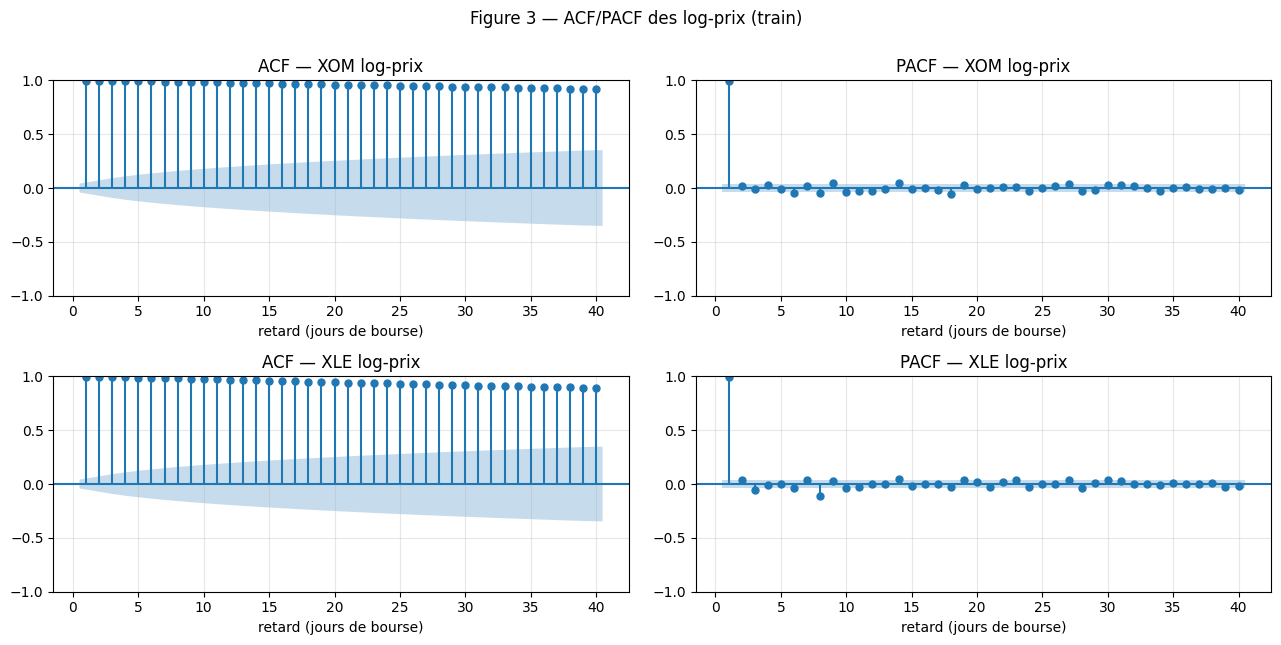

,XOM log-prix,XLE log-prix
n,2262,2262
bande 95 %,0.0412,0.0412
ACF(1),0.9982,0.9977
ACF(2),0.9965,0.9955
ACF(5),0.9913,0.9883
ACF(10),0.9820,0.9748
ACF(21),0.9589,0.9421
PACF(1),0.9982,0.9977
PACF(2),0.0176,0.0339
PACF(5),-0.0094,-0.0018


In [18]:
LAGS = 40
def acf_table(series):
    t = pd.DataFrame({name: eda.acf_summary(x, LAGS) for name, x in series.items()})
    return t

fig = eda.plot_acf_pacf({"XOM log-prix": TRAIN["XOM_logp"], "XLE log-prix": TRAIN["XLE_logp"]}, LAGS,
                        "Figure 3 — ACF/PACF des log-prix (train)")
save_fig(fig, 3, "acf_pacf_logprix")
plt.show()
acf_logp = acf_table({"XOM log-prix": TRAIN["XOM_logp"], "XLE log-prix": TRAIN["XLE_logp"]})
acf_logp

**Interprétation de la figure 3 (log-prix).**
- **ACF.** L'autocorrélation est quasi égale à 1 et décroît très lentement, de façon presque linéaire :
  - ACF(1) = 0,998 pour XOM (0,998 pour XLE) ;
  - ACF(21) = 0,959 (0,942), soit un mois plus tard ;
  - les **40 retards** restent tous très au-dessus de la bande de confiance.

  Cette décroissance lente est la signature d'une série **non stationnaire** : un choc ne s'efface pas, il se propage durablement au niveau des prix.
- **PACF.** Un seul pic, au retard 1 (0,998), puis plus rien : PACF(2) = 0,018 pour XOM (0,034 pour XLE). La série se comporte donc comme un AR(1) de coefficient ≈ 1, c'est-à-dire comme une **marche aléatoire** : l_t ≈ l_{t−1} + choc. Quelques retards partiels dépassent légèrement la bande (6 pour XOM, 5 pour XLE), mais avec des valeurs de 0,05 au plus, donc sans importance pratique.
- **Bande de confiance.** Sur le graphe ACF, la bande s'élargit avec le retard (formule de Bartlett). Le décompte « hors bande » du tableau utilise la bande fixe de bruit blanc (±0,041).
- **Ljung-Box.** Q(10) = 22 255 pour XOM (p < 0,0001) : l'absence d'autocorrélation est rejetée sans ambiguïté.

**Conclusion.** Le log-prix ne peut pas être modélisé tel quel par un ARMA stationnaire : il faut le différencier, ce que l'on vérifie sur la figure 4 et formellement en 2.6.

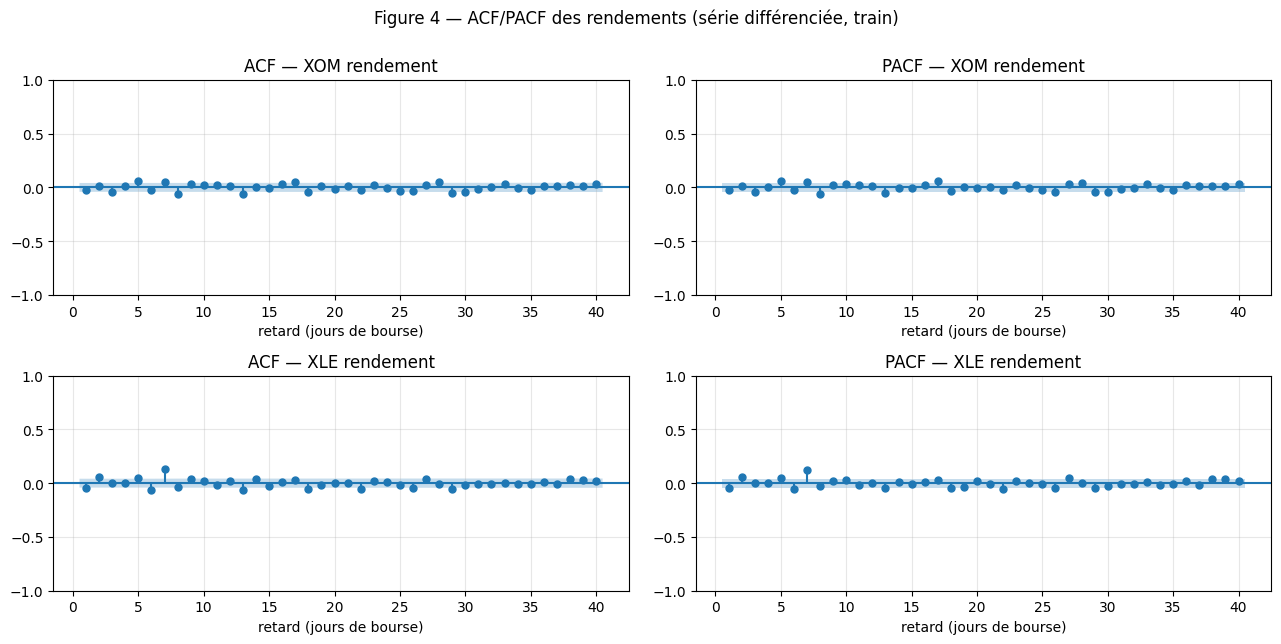

,XOM rendement,XLE rendement
n,2261,2261
bande 95 %,0.0412,0.0412
ACF(1),-0.0240,-0.0455
ACF(2),0.0140,0.0575
ACF(5),0.0579,0.0446
ACF(10),0.0262,0.0202
ACF(21),0.0164,-0.0005
PACF(1),-0.0240,-0.0455
PACF(2),0.0134,0.0556
PACF(5),0.0595,0.0450


In [19]:
fig = eda.plot_acf_pacf({"XOM rendement": TRAIN["XOM_ret"], "XLE rendement": TRAIN["XLE_ret"]}, LAGS,
                        "Figure 4 — ACF/PACF des rendements (série différenciée, train)")
save_fig(fig, 4, "acf_pacf_rendements")
plt.show()
acf_ret = acf_table({"XOM rendement": TRAIN["XOM_ret"], "XLE rendement": TRAIN["XLE_ret"]})
acf_ret

**Interprétation de la figure 4 (rendements = log-prix différencié).**
- **La structure de la figure 3 a disparu.** Une seule différenciation suffit à supprimer la persistance des niveaux. Les autocorrélations sont minuscules : la plus forte en valeur absolue vaut −0,064 (retard 8) pour XOM et 0,129 (retard 7) pour XLE. Une autocorrélation de 0,06 n'explique que 0,06² ≈ 0,4 % de la variance du rendement du lendemain.
- **Pas d'ordre ARMA lisible.** Ni l'ACF ni la PACF ne montrent de coupure nette après quelques retards :
  - les rares dépassements sont dispersés (XOM : retards 5, 7, 8, 13, 17, 28, 29, 30 ; XLE : 1, 2, 5, 6, 7, 13, 18, 22, 29) ;
  - aucun motif régulier ne s'en dégage.
- **Mais Ljung-Box rejette l'absence d'autocorrélation**, avec Q(10) = 34,9 pour XOM (p = 0,0001) et 70,1 pour XLE (p < 0,0001). Il y a 8 et 9 retards hors bande sur 40, alors qu'on en attend environ 2 par hasard. Avant d'en conclure qu'il existe une structure ARMA à exploiter, on vérifie d'où vient ce rejet dans le tableau suivant.

In [20]:
# Le rejet de Ljung-Box vient-il de la moyenne ou de la variance ? Trois versions des rendements.
robust = pd.concat({tk: eda.ljungbox_robustness(TRAIN[f"{tk}_ret"]) for tk in ["XOM", "XLE"]})
save_table(robust, "tab05_ljungbox_robustesse")
robust

p-value Q(5)  p-value Q(10)  p-value Q(20)
XOM rendements bruts                              0.0219         0.0001         0.0000
    standardisés par la vol. passée (21 j)        0.9714         0.9822         0.8980
    hors année 2020                               0.5890         0.4435         0.3595
XLE rendements bruts                              0.0050         0.0000         0.0000
    standardisés par la vol. passée (21 j)        0.4983         0.5343         0.7385
    hors année 2020                               0.6857         0.5099         0.8452

**Interprétation du contrôle de robustesse de Ljung-Box.**
Le test de Ljung-Box suppose une variance constante. Avec du regroupement de volatilité, quelques jours très agités suffisent à produire de grandes autocorrélations empiriques, et le test rejette trop souvent. On le refait donc sur deux versions corrigées des rendements :

| Version des rendements | XOM : p-value Q(10) | XLE : p-value Q(10) |
| --- | --- | --- |
| bruts | 0,0001 | < 0,0001 |
| divisés par leur volatilité des 21 jours précédents | **0,98** | **0,53** |
| sans l'année 2020 | **0,44** | **0,51** |

Le rejet **disparaît entièrement** dans les deux versions corrigées, pour Q(5), Q(10) et Q(20). Même le retard 7 de XLE, le plus marqué (0,129), tombe à 0,0008 sans 2020.

**Conclusion.**
- L'autocorrélation apparente des rendements est un **artefact de l'hétéroscédasticité de 2020**, pas une dynamique exploitable de la moyenne.
- En moyenne, les rendements sont compatibles avec un **bruit blanc**. Le log-prix est donc proche d'une marche aléatoire, et ARIMA(0,1,0) est le candidat de référence. Il sera comparé en 3.1 à des ARIMA(p,1,q) de petits ordres (p, q ≤ 2) et au choix d'`auto_arima`.
- Il faudra s'attendre à ce que les termes AR/MA éventuellement retenus aient un pouvoir prédictif très faible.

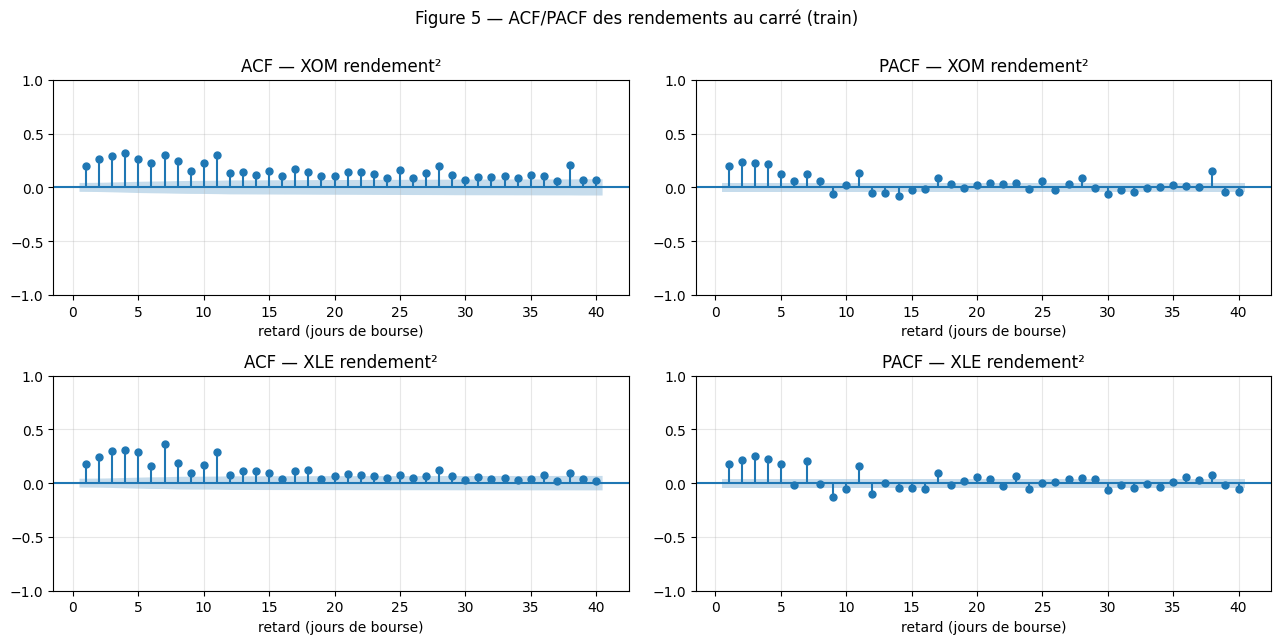

,XOM rendement²,XLE rendement²
n,2261,2261
bande 95 %,0.0412,0.0412
ACF(1),0.2028,0.1772
ACF(2),0.2673,0.2397
ACF(5),0.2645,0.2934
ACF(10),0.2227,0.1677
ACF(21),0.1434,0.0840
PACF(1),0.2028,0.1772
PACF(2),0.2359,0.2151
PACF(5),0.1256,0.1785


In [21]:
sq = {"XOM rendement²": TRAIN["XOM_ret"] ** 2, "XLE rendement²": TRAIN["XLE_ret"] ** 2}
fig = eda.plot_acf_pacf(sq, LAGS, "Figure 5 — ACF/PACF des rendements au carré (train)")
save_fig(fig, 5, "acf_pacf_rendements_carres")
plt.show()
acf_sq = acf_table(sq)
save_table(pd.concat([acf_logp, acf_ret, acf_sq], axis=1), "tab06_acf_resume")
acf_sq

**Interprétation de la figure 5 (rendements au carré).**
- **Le contraste avec la figure 4 est total.** Les rendements eux-mêmes sont quasi non autocorrélés, mais leurs carrés le sont fortement et durablement :
  - **XOM** : ACF(1) = 0,20 ; maximum 0,32 au retard 4 ; ACF(40) encore égale à 0,065 ; les **40 retards** dépassent la bande ;
  - **XLE** : maximum 0,37 au retard 7 ; 32 retards sur 40 hors bande ;
  - **Ljung-Box** : Q(10) = 1 464 pour XOM et 1 343 pour XLE (p < 0,0001).
- **Lecture économique.** Un jour de forte variation, dans un sens ou dans l'autre, est suivi d'autres jours de forte variation : c'est la mesure chiffrée du regroupement de volatilité de la figure 2. La décroissance lente de l'ACF indique une volatilité **très persistante**.
- **Implication pour le modèle.** La PACF des carrés est significative sur les ~5 premiers retards (entre 0,13 et 0,25), ce qui correspondrait à un ARCH d'ordre élevé. Un **GARCH(1,1)** représente cette dynamique de façon beaucoup plus parcimonieuse : la variance d'aujourd'hui dépend du choc d'hier **et** de la variance d'hier. Ce diagnostic justifie la section 3.3.
- **Un rendement non autocorrélé n'est pas un rendement indépendant.** Ces rendements sont imprévisibles en moyenne (figure 4), mais leur amplitude est en partie prévisible.

### 2.4 Décomposition STL du log-prix (train)

STL (Seasonal-Trend decomposition using Loess) en version **robuste**, pour que les chocs de 2020 ne déforment pas la tendance et la saisonnalité. On décompose le log-prix, et non le prix, pour que les composantes soient additives : une variation de la composante correspond à un pourcentage du prix.
Trois périodes sont testées : **5** (semaine de bourse), **21** (mois de bourse) et **252** (année de bourse). Pour juger objectivement la saisonnalité, on calcule la **force** de chaque composante (Wang, Smith & Hyndman, 2006) : F = max(0, 1 − Var(résidu) / Var(composante + résidu)). F proche de 0 signifie une composante inexistante, F proche de 1 une composante dominante.

In [22]:
strength = pd.DataFrame({(tk, p): eda.stl_strength(eda.stl_decompose(TRAIN[f"{tk}_logp"], p))
                         for tk in ["XOM", "XLE"] for p in (5, 21, 252)}).T
strength.index.names = ["actif", "période"]
save_table(strength, "tab07_stl_force")
strength

force tendance F_T  force saisonnalité F_S  amplitude saisonnière (max - min)  écart-type résidu
actif période                                                                                                  
XOM   5                    0.9968                  0.0000                             0.0978             0.0201
      21                   0.9912                  0.0319                             0.1313             0.0332
      252                  0.8686                  0.0000                             0.4105             0.1283
XLE   5                    0.9955                  0.0000                             0.2300             0.0218
      21                   0.9859                  0.0199                             0.1466             0.0386
      252                  0.8559                  0.0012                             0.3169             0.1231

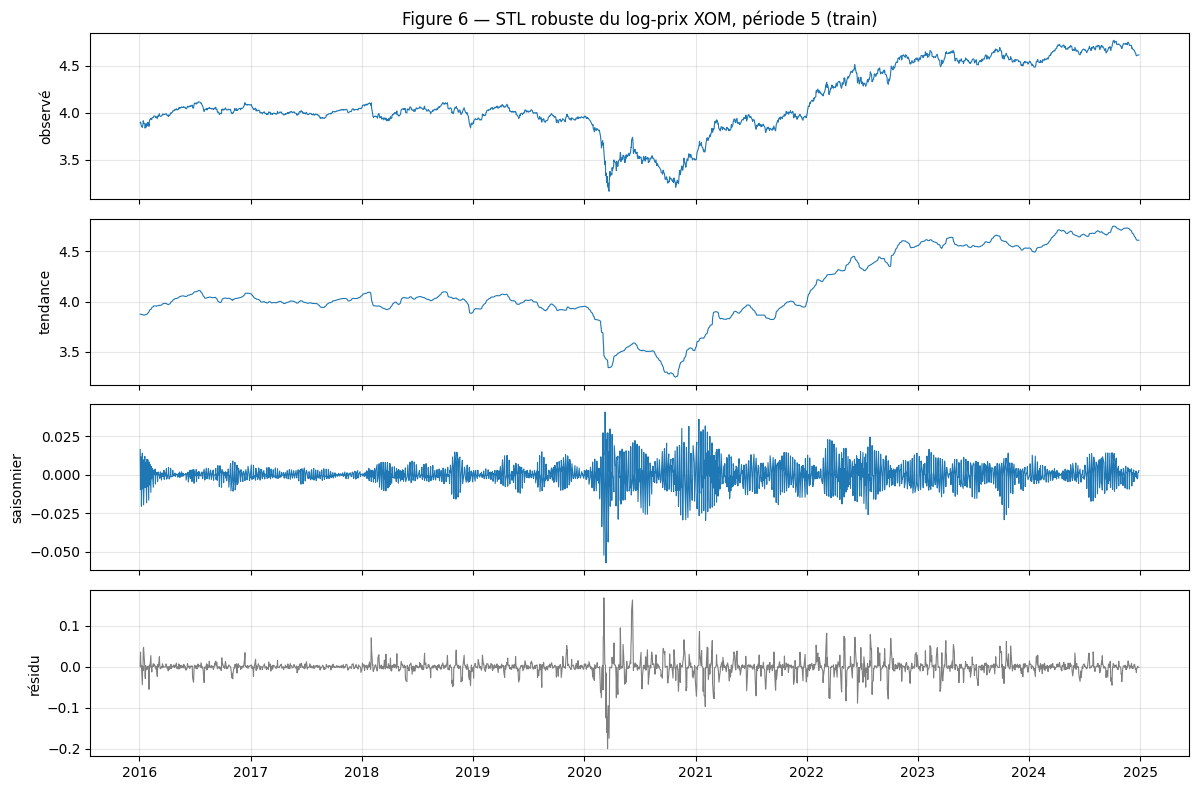

In [23]:
stl5 = eda.stl_decompose(TRAIN["XOM_logp"], 5)
fig = eda.plot_stl(stl5, "Figure 6 — STL robuste du log-prix XOM, période 5 (train)")
save_fig(fig, 6, "stl_xom_p5")
plt.show()

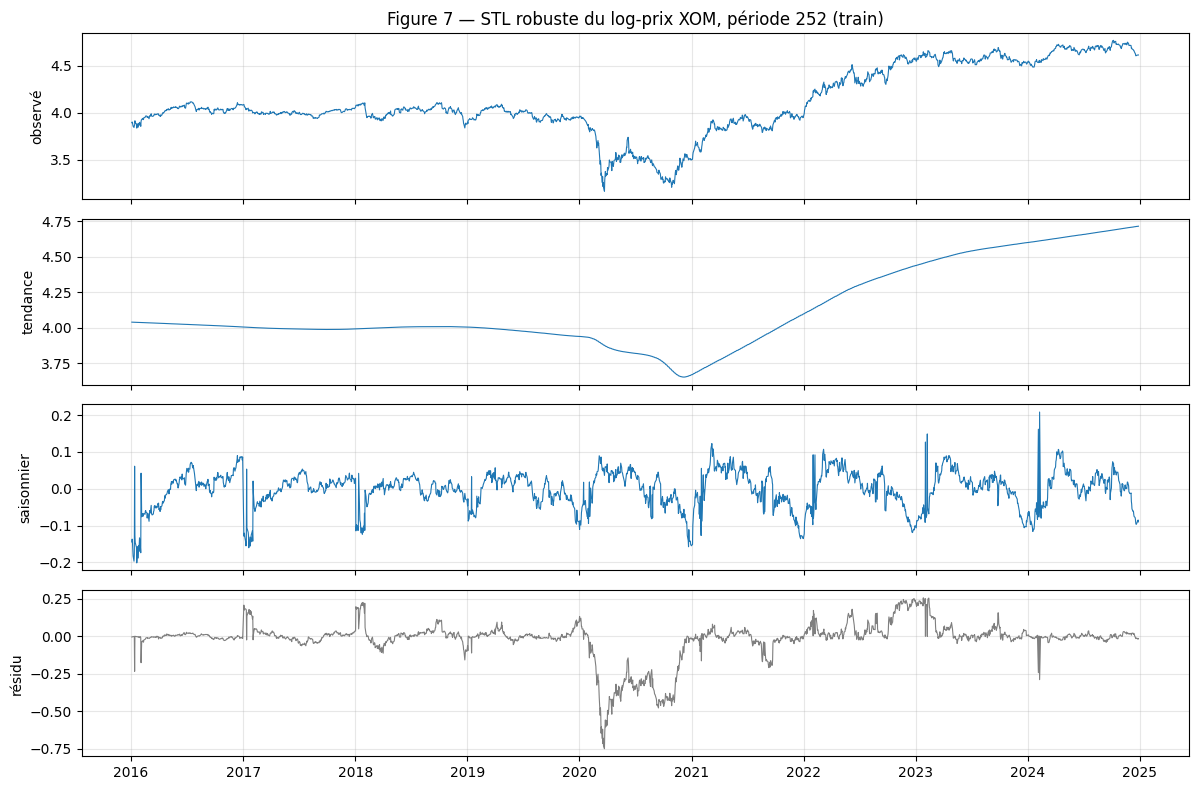

In [24]:
stl252 = eda.stl_decompose(TRAIN["XOM_logp"], 252)
fig = eda.plot_stl(stl252, "Figure 7 — STL robuste du log-prix XOM, période 252 (train)")
save_fig(fig, 7, "stl_xom_p252")
plt.show()

In [25]:
# Contre-vérification de la saisonnalité hebdomadaire directement sur les rendements :
# un effet « jour de la semaine » est la forme que prendrait une saisonnalité s = 5.
for tk in ["XOM", "XLE"]:
    w = eda.weekday_effect(TRAIN[f"{tk}_ret"])
    print(f"{tk} — Kruskal-Wallis (moyennes) : stat = {w['Kruskal-Wallis stat']:.3f}, p = {w['Kruskal-Wallis p']:.4f} ; "
          f"Levene (variances) : stat = {w['Levene stat']:.3f}, p = {w['Levene p']:.4f}")
    display(w["table"].round(3).T)

XOM — Kruskal-Wallis (moyennes) : stat = 2.806, p = 0.5909 ; Levene (variances) : stat = 1.275, p = 0.2775


,lundi,mardi,mercredi,jeudi,vendredi
mean,0.1130,0.0630,-0.0180,0.0190,-0.0110
std,2.0280,1.7320,1.7540,1.7090,1.7070
count,419.0000,465.0000,463.0000,458.0000,456.0000


XLE — Kruskal-Wallis (moyennes) : stat = 1.735, p = 0.7843 ; Levene (variances) : stat = 2.592, p = 0.0350


,lundi,mardi,mercredi,jeudi,vendredi
mean,0.0650,0.0480,-0.0170,-0.0140,0.0780
std,2.3520,1.7580,1.9470,1.7820,1.7490
count,419.0000,465.0000,463.0000,458.0000,456.0000


**Interprétation de la décomposition STL.**

**Force des composantes (tableau).** La tendance domine dans tous les cas : F_T = 0,997 (période 5), 0,991 (21) et 0,869 (252) pour XOM, avec des valeurs proches pour XLE. La saisonnalité est **inexistante** : F_S = 0,000, 0,032 et 0,000 pour XOM, et 0,000, 0,020 et 0,001 pour XLE. Aucune période testée ne fait apparaître de cycle exploitable.

**Figure 6 (période 5).**
- **Tendance.** Elle reproduit fidèlement le log-prix : une phase plate de 2016 à 2019, la chute de 2020, puis la remontée de 2021–2022.
- **« Saisonnalité ».** Une vraie saisonnalité hebdomadaire répéterait le même motif chaque semaine, avec une amplitude stable. Ici, l'amplitude de la composante suit exactement la volatilité : quasi nulle en 2017, maximale le 2020-03-13 (|s| = 0,057). STL a simplement découpé une partie du bruit en blocs de 5 jours.
- **Ordres de grandeur.** L'écart-type de cette composante (0,008) reste bien inférieur à celui du résidu (0,020).
- **Résidu.** Il concentre les chocs de 2020 et a l'allure des rendements.

**Figure 7 (période 252).**
- **Tendance.** Une fenêtre d'un an la rend très lisse.
- **« Saisonnalité ».** La composante ne répète aucun profil annuel identifiable, et ses pics isolés ne reviennent pas à la même date d'une année sur l'autre.
- **Résidu.** Il absorbe le krach de 2020 (jusqu'à −0,75 en log, soit environ −53 %) et des écarts de ±0,25. Son écart-type (0,128) est six fois celui de la décomposition hebdomadaire.

Une décomposition annuelle ne décrit donc pas ces données.

**Contre-vérification directe.** Une saisonnalité de période 5 se traduirait par un effet « jour de la semaine » sur les rendements.
- **Moyenne.** Le lundi a le rendement moyen le plus élevé (0,113 % pour XOM), mais avec l'écart-type le plus fort (2,03 %). Le test de Kruskal-Wallis ne détecte **aucune différence** entre jours (p = 0,59 pour XOM, 0,78 pour XLE).
- **Variance.** Le test de Levene ne rejette pas pour XOM (p = 0,28). Il rejette de justesse pour XLE (p = 0,035), dont le lundi est un peu plus volatil (écart-type de 2,35 % contre 1,75 à 1,95 % les autres jours), ce qui est cohérent avec l'accumulation d'informations pendant le week-end.

Cela concerne la **variance**, pas la moyenne : ce n'est pas un motif qu'un SARIMA pourrait modéliser.

**Conclusion.**
- Il n'y a **pas de saisonnalité** à modéliser : D = 0.
- Le SARIMA de période s = 5 sera estimé en 3.1 pour le vérifier formellement, et devrait être écarté.
- La tendance n'est pas une droite déterministe : elle erre, monte et chute. C'est le comportement d'une tendance **stochastique** (racine unitaire), testée en 2.6.

### 2.5 Valeurs aberrantes

**Méthode.** Un rendement est signalé s'il sort de [Q1 − 3·IQR ; Q3 + 3·IQR], où les quartiles sont calculés sur les **63 jours de bourse précédents** (un trimestre).
- **Seuil glissant plutôt que fixe** : la règle s'adapte au régime de volatilité. Un mouvement de 4 % est banal en mars 2020 mais exceptionnel en 2017.
- **Fenêtre décalée d'un jour** (`shift(1)`) : le jour testé n'influence pas son propre seuil, et la règle n'utilise que le passé.
- **k = 3** (et non 1,5) : avec des queues aussi épaisses, k = 1,5 signalerait des centaines de jours parfaitement ordinaires.

La détection est faite sur toute la période, car la variable indicatrice doit exister aussi sur le test.

In [26]:
out = {tk: eda.detect_outliers(panel[f"{tk}_ret"]) for tk in ["XOM", "XLE"]}
counts = pd.DataFrame({tk: o["outlier"].groupby(o.index.year).sum() for tk, o in out.items()}).fillna(0).astype(int)
counts.loc["total"] = counts.sum()
counts.loc["dont test"] = [int(o.loc[test.index, "outlier"].sum()) for o in out.values()]
both = (out["XOM"]["outlier"] & out["XLE"]["outlier"])
print(f"Jours signalés simultanément pour XOM et XLE : {int(both.sum())}")
counts.T

Jours signalés simultanément pour XOM et XLE : 11


Date,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,total,dont test
XOM,1,0,2,0,10,0,0,0,0,2,15,2
XLE,1,0,2,0,10,0,1,0,0,4,18,4


In [27]:
rows = []
for tk, o in out.items():
    f = o[o["outlier"] == 1]
    rows.append(f.assign(actif=tk, échantillon=np.where(f.index.isin(test.index), "test", "train")))
outliers = pd.concat(rows).reset_index().sort_values(["actif", "Date"])
outliers = outliers[["actif", "Date", "échantillon", "rendement", "borne basse", "borne haute"]]
save_table(outliers, "tab08_outliers", index=False)

# Variables indicatrices sauvegardées pour les modèles (ex. régresseur d'intervention en ARIMAX).
flags = pd.DataFrame({f"{tk}_outlier": o["outlier"] for tk, o in out.items()})
flags.to_csv(ROOT / "data/processed/outliers.csv", lineterminator="\n")
outliers.round(2)

,actif,Date,échantillon,rendement,borne basse,borne haute
15,XLE,2016-11-30,train,4.9600,-4.3800,4.2800
16,XLE,2018-02-02,train,-4.2700,-3.5500,4.0100
17,XLE,2018-02-05,train,-4.2900,-3.6100,4.0100
18,XLE,2020-02-27,train,-5.5000,-4.7400,4.2800
19,XLE,2020-03-06,train,-5.7800,-5.5500,5.3000
20,XLE,2020-03-09,train,-22.4900,-5.5200,5.0300
21,XLE,2020-03-12,train,-13.3200,-5.9600,5.3600
22,XLE,2020-03-13,train,8.8300,-6.2400,5.5700
23,XLE,2020-03-16,train,-14.6300,-6.6600,6.1300
24,XLE,2020-03-18,train,-15.5000,-6.9000,6.2700


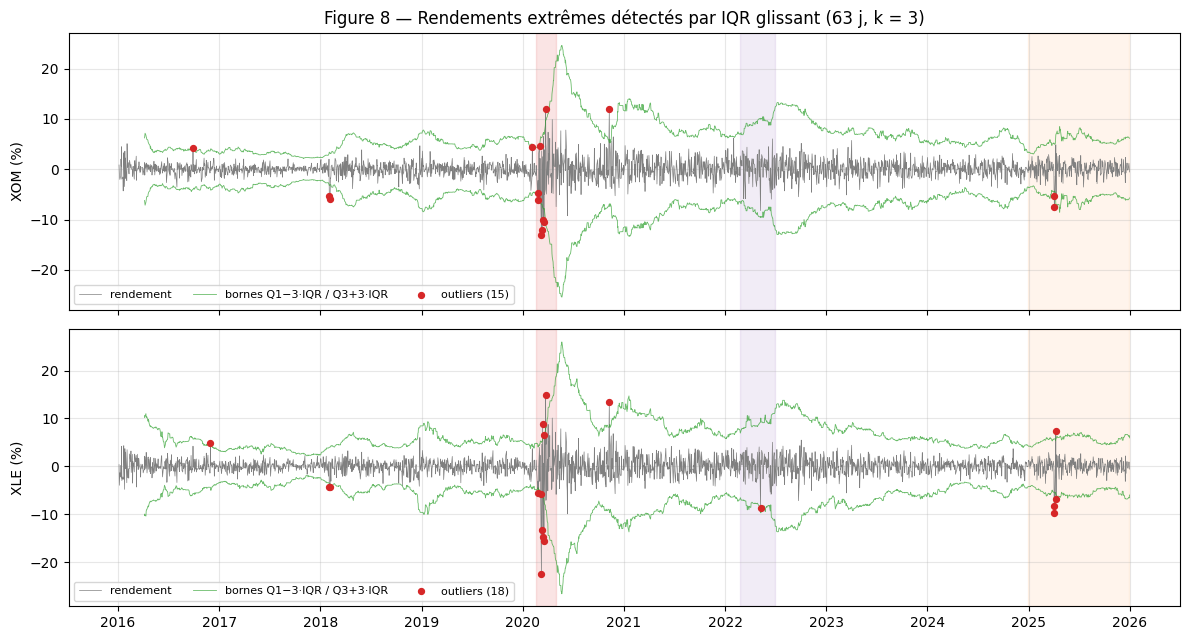

In [28]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
for ax, (tk, o) in zip(axes, out.items()):
    ax.plot(o.index, o["rendement"], lw=0.5, color="grey", label="rendement")
    ax.plot(o.index, o["borne haute"], lw=0.6, color="tab:green", alpha=0.7, label="bornes Q1−3·IQR / Q3+3·IQR")
    ax.plot(o.index, o["borne basse"], lw=0.6, color="tab:green", alpha=0.7)
    f = o[o["outlier"] == 1]
    ax.scatter(f.index, f["rendement"], color="tab:red", s=18, zorder=3, label=f"outliers ({len(f)})")
    shade(ax)
    ax.set_ylabel(f"{tk} (%)")
    ax.grid(alpha=0.3)
    ax.legend(loc="lower left", fontsize=8, ncol=3)
axes[0].set_title("Figure 8 — Rendements extrêmes détectés par IQR glissant (63 j, k = 3)")
fig.tight_layout()
save_fig(fig, 8, "outliers")
plt.show()

**Interprétation des valeurs aberrantes.**

**Bilan.** On détecte 15 jours extrêmes pour XOM (13 dans le train, 2 dans le test) et 18 pour XLE (14 et 4). **11 jours** sont communs aux deux actifs, ce qui confirme qu'il s'agit de chocs de marché et non d'erreurs de données propres à un titre.

**Concentration en 2020.** Dix jours par actif tombent en 2020. Les plus violents sont :
- **2020-03-09** : −13,0 % pour XOM, −22,5 % pour XLE, face à des bornes de −6,9 % et −5,5 %. Ce jour-là, après l'échec des négociations OPEP+, l'Arabie saoudite lance une guerre des prix contre la Russie, en pleine propagation du COVID-19 : le Brent subit sa plus forte baisse en une séance depuis 1991 ([KVIA / CNN Business](https://kvia.com/news/business-technology/2020/03/09/oil-crashes-by-most-since-1991-as-saudi-arabia-launches-price-war/)). Notre propre série du Brent (`BZ=F`) perd −24,1 % ce jour-là, exactement la baisse à la clôture rapportée par la presse : la date et la donnée sont recoupées ;
- les 12, 16 et 18 mars, puis le rebond du 24 mars (+11,9 % pour XOM, +14,9 % pour XLE) ;
- **2020-11-09** (+11,9 % et +13,3 %) : Pfizer et BioNTech annoncent que leur vaccin contre le COVID-19 est efficace à plus de 90 % d'après les premiers résultats de phase 3, ce qui déclenche une forte hausse du pétrole et des valeurs énergétiques ([PBS NewsHour](https://www.pbs.org/newshour/world/global-markets-rocket-higher-amid-vaccine-news-and-u-s-election)).

**Dans le test.** Les jours détectés se concentrent sur **3 au 10 avril 2025** : chute de −7,5 % pour XOM et de −9,7 % pour XLE le 4 avril, puis rebond de +7,5 % pour XLE le 9 avril. Cette séquence suit exactement le calendrier des droits de douane américains : annonce des tarifs « réciproques » le 2 avril après la clôture, chute des marchés les 3 et 4 avril, suspension de 90 jours annoncée le 9 avril, nouvelle baisse le 10 avril ([Wikipedia, « 2025 stock market crash »](https://en.wikipedia.org/wiki/2025_stock_market_crash)). Les quatre jours signalés pour XLE (3, 4, 9 et 10 avril) correspondent un à un à ces étapes.

Toutes les sources sont regroupées dans `docs/sources.md`.

**Une limite de la règle.** La figure montre qu'après mars 2020 les bornes s'élargissent jusqu'à environ ±25 %, parce que le trimestre précédent était lui-même extrême. Des baisses importantes ne sont donc pas signalées :
- −7,4 % pour XOM le 2020-05-01 (borne à −22,5 %) ;
- −9,2 % pour XOM et −9,9 % pour XLE le 2020-06-11 (bornes à −18,1 % et −20,1 %). Une règle glissante juge chaque jour **par rapport à son régime** : c'est voulu, mais elle réagit avec retard aux changements de régime.

**Traitement retenu : conservation, avec une variable indicatrice.**
1. **Ces chocs sont réels.** Ils correspondent à des événements de marché identifiables et se retrouvent sur les deux actifs. Ce ne sont pas des erreurs de mesure.
2. **Les supprimer ou les lisser sous-estimerait le risque.** La volatilité est justement ce que modélise GARCH : retirer les jours extrêmes ferait disparaître l'objet même de l'étude, et donnerait des intervalles de prévision trop étroits.
3. **Les remplacer serait un choix arbitraire.** Le remplacement par une médiane ou par interpolation créerait des données qui n'ont jamais existé.

Les indicatrices `XOM_outlier` et `XLE_outlier` sont sauvegardées dans `data/processed/outliers.csv`. Elles pourront servir de variables d'intervention (ARIMAX), ou à tester la sensibilité des résultats aux jours extrêmes.

**Sensibilité aux paramètres.** La fenêtre (63 jours) et le seuil (k = 3) sont des choix. On refait la détection sur une grille de 16 réglages, avec des fenêtres de 21, 63, 126 et 252 jours et k = 2 ; 2,5 ; 3 ; 3,5. On regarde ensuite :
- combien de jours chaque réglage signale ;
- quels jours restent signalés quel que soit le réglage : le **noyau**, défini comme les jours signalés par au moins 12 des 16 réglages.

In [29]:
sens = {tk: eda.outlier_sensitivity(panel[f"{tk}_ret"], test.index) for tk in ["XOM", "XLE"]}
grid = pd.concat({tk: g for tk, (g, _) in sens.items()})
save_table(grid, "tab08b_outliers_sensibilite")
grid.unstack("k")["total"]

k            2.0000  2.5000  3.0000  3.5000
    fenêtre                                
XOM 21           65      33      18      11
    63           40      23      15      11
    126          49      26      17      12
    252          54      31      21      15
XLE 21           66      29      14      11
    63           49      30      18      15
    126          59      34      24      16
    252          56      36      27      20

In [30]:
core = pd.concat({tk: c for tk, (_, c) in sens.items()})
core.index.names = ["actif", "Date"]
save_table(core, "tab08c_outliers_noyau")
for tk, (g, c) in sens.items():
    ref = int(out[tk]["outlier"].sum())
    print(f"{tk} : noyau de {len(c)} jours, tous dans la référence : {bool(c['dans la référence'].all())} "
          f"(référence = {ref} jours, dont {ref - len(c)} hors noyau)")
core.round(2)

XOM : noyau de 11 jours, tous dans la référence : True (référence = 15 jours, dont 4 hors noyau)
XLE : noyau de 14 jours, tous dans la référence : True (référence = 18 jours, dont 4 hors noyau)


rendement  réglages qui le signalent  dans la référence
actif Date                                                               
XOM   2018-02-02    -5.2300                         16               True
      2018-02-05    -5.8600                         16               True
      2020-02-27    -6.2100                         14               True
      2020-03-09   -13.0400                         12               True
      2020-03-12   -12.1400                         12               True
      2020-03-16   -10.0100                         12               True
      2020-03-18   -10.5600                         12               True
      2020-03-24    11.9400                         12               True
      2020-11-09    11.9200                         16               True
      2025-04-03    -5.4000                         13               True
      2025-04-04    -7.4700                         16               True
XLE   2018-02-02    -4.2700                         15               True
      2018-02-05    -4.2900                         14               True
      2020-02-27    -5.5000                         12               True
      2020-03-09   -22.4900                         16               True
      2020-03-12   -13.3200                         12               True
      2020-03-13     8.8300                         12               True
      2020-03-16   -14.6300                         13               True
      2020-03-18   -15.5000                         12               True
      2020-03-24    14.8700                         13               True
      2020-11-09    13.3400                         16               True
      2025-04-03    -8.1800                         16               True
      2025-04-04    -9.6500                         16               True
      2025-04-09     7.4600                         16               True
      2025-04-10    -6.7600                         15               True

**Interprétation de la sensibilité.**

**Le nombre de jours signalés dépend beaucoup des paramètres.** Selon le réglage, on obtient de 11 à 65 jours pour XOM et de 11 à 66 pour XLE. Les deux paramètres jouent :
- **k = 2** produit 40 à 66 signalements, dont beaucoup de mouvements ordinaires pour des queues aussi épaisses ;
- **une fenêtre de 21 jours** s'adapte si vite au régime qu'elle ne retrouve qu'environ la moitié des jours de la référence.

Le nombre « 15 outliers » n'a donc pas de valeur absolue : il dépend de la définition retenue.

**Mais les jours importants sont robustes.** Le **noyau**, signalé par au moins 12 des 16 réglages, compte **11 jours pour XOM et 14 pour XLE**, et notre réglage de référence (63 jours, k = 3) les retrouve **tous**. Ce sont :
- les deux séances de début février 2018 ;
- les journées de mars 2020 : le 27 février, puis les 9, 12, 16, 18 et 24 mars, plus le 13 mars pour XLE ;
- le 9 novembre 2020 ;
- avril 2025 : les 3 et 4 avril pour XOM, ainsi que les 9 et 10 pour XLE.

Les **4 jours** de la référence qui restent hors du noyau, pour chaque actif, sont des cas limites dont le statut dépend du réglage :
- XOM : 2016-09-28, 2020-02-05, 2020-02-24, 2020-03-02 ;
- XLE : 2016-11-30, 2020-03-06, 2020-03-19, 2022-05-09.

**Conséquence pratique limitée.** Comme les outliers sont **conservés** dans toutes les estimations, le choix des paramètres n'affecte que la variable indicatrice, pas les données des modèles. Si l'indicatrice est utilisée comme régresseur, il sera prudent de vérifier que les résultats tiennent avec la version « noyau » (`tab08c_outliers_noyau.csv`).

### 2.6 Tests de stationnarité : ADF et KPSS (train)

Les deux tests sont complémentaires car leurs **hypothèses nulles sont opposées** :
- **ADF** (Dickey-Fuller augmenté) : H₀ = la série a une racine unitaire (non stationnaire). Le nombre de retards augmentés est choisi par AIC, pour absorber l'autocorrélation des résidus du test.
- **KPSS** : H₀ = la série est stationnaire (autour d'une constante, ou d'une tendance déterministe dans la spécification « constante + tendance »). Le nombre de retards de la variance de long terme est choisi automatiquement (Hobijn et al., 1998).

Chaque série est testée avec deux spécifications. La spécification « constante + tendance » est la plus exigeante pour le log-prix, qui présente une dérive visible : elle vérifie qu'il ne s'agit pas d'une simple tendance déterministe.
Décision au seuil de 5 % : ADF rejette H₀ si sa statistique est **inférieure** à la valeur critique, KPSS si sa statistique est **supérieure** à la sienne.

In [31]:
stationarity = eda.stationarity_table({
    "XOM log-prix": TRAIN["XOM_logp"], "XOM rendement": TRAIN["XOM_ret"],
    "XLE log-prix": TRAIN["XLE_logp"], "XLE rendement": TRAIN["XLE_ret"],
})
save_table(stationarity, "tab09_adf_kpss")
stationarity.round(4)

ADF stat  ADF VC 5 %  ADF retards   ADF p  ADF rejette H0  KPSS stat  KPSS VC 5 %  KPSS retards  KPSS p  KPSS rejette H0  \
série         spécification                                                                                                                                    
XOM log-prix  constante              -0.9714     -2.8628           18  0.7635           False     3.5632       0.4630            29  < 0.01             True   
              constante + tendance   -1.5995     -3.4124           18  0.7926           False     1.3972       0.1460            29  < 0.01             True   
XOM rendement constante             -10.5566     -2.8628           17  0.0000            True     0.1439       0.4630             8  > 0.10            False   
              constante + tendance  -10.5684     -3.4124           17  0.0000            True     0.0845       0.1460             8  > 0.10            False   
XLE log-prix  constante              -1.5033     -2.8628            7  0.5319           False     3.5858       0.4630            29  < 0.01             True   
              constante + tendance   -1.9726     -3.4124            7  0.6163           False     1.2637       0.1460            29  < 0.01             True   
XLE rendement constante             -16.0638     -2.8628            6  0.0000            True     0.0840       0.4630             9  > 0.10            False   
              constante + tendance  -16.0600     -3.4124            6  0.0000            True     0.0607       0.1460             9  > 0.10            False   

                                                         conclusion  
série         spécification                                          
XOM log-prix  constante             non stationnaire : différencier  
              constante + tendance  non stationnaire : différencier  
XOM rendement constante                                stationnaire  
              constante + tendance                     stationnaire  
XLE log-prix  constante             non stationnaire : différencier  
              constante + tendance  non stationnaire : différencier  
XLE rendement constante                                stationnaire  
              constante + tendance                     stationnaire

**Interprétation des tests ADF et KPSS (train).**

**Log-prix : non stationnaires.**
- **XOM, spécification constante.** L'ADF vaut −0,97, alors que la valeur critique à 5 % est −2,86, avec 18 retards et p = 0,76 : la racine unitaire **n'est pas rejetée**. Le KPSS vaut 3,56, très au-dessus de la valeur critique de 0,463 (p < 0,01) : la stationnarité **est rejetée**.
- **XOM, spécification constante + tendance.** Même verdict : ADF −1,60 contre −3,41 (p = 0,79) ; KPSS 1,40 contre 0,146 (p < 0,01). Le log-prix n'est donc **pas non plus stationnaire autour d'une tendance déterministe**, et retirer une droite ne suffirait pas.
- **XLE.** Résultats identiques : ADF −1,50 (p = 0,53) et −1,97 (p = 0,62) ; KPSS 3,59 et 1,26.
- **Les deux tests concordent** : selon le tableau de décision du plan, conclusion « non stationnaire : différencier ».

**Rendements (log-prix différencié) : stationnaires.**
- **ADF.** La racine unitaire est massivement rejetée : −10,56 pour XOM et −16,06 pour XLE, contre −2,86 (p < 0,0001).
- **KPSS.** La stationnarité n'est pas rejetée : 0,144 pour XOM et 0,084 pour XLE, contre 0,463 (p > 0,10).
- **Les deux spécifications** donnent la même conclusion, et les deux tests concordent : **stationnaire**.

**Fiabilité.** Toutes les statistiques sont loin de leurs valeurs critiques : les conclusions ne dépendent ni du seuil choisi ni de la spécification. Le nombre élevé de retards retenus par AIC (18 pour l'ADF de XOM, 29 pour le KPSS des log-prix) reflète la persistance et l'hétéroscédasticité de la série. Ce choix rend le test robuste à l'autocorrélation, sans changer la décision.

Dernière question : la non-stationnarité du log-prix ne serait-elle qu'un effet du krach de 2020 ?

In [32]:
# Robustesse : la non-stationnarité du log-prix n'est-elle qu'un effet du krach de 2020 ?
za = eda.zivot_andrews_table({"XOM log-prix": TRAIN["XOM_logp"], "XLE log-prix": TRAIN["XLE_logp"]})
save_table(za, "tab10_zivot_andrews")
za.round(4)

statistique  valeur critique 5 %  p-value  retards date de rupture estimée  H0 rejetée (5 %)
série        spécification                                                                                                              
XOM log-prix rupture de niveau                  -3.7940              -4.8107   0.4831       18              2021-12-20             False
             rupture de niveau et de pente      -4.2081              -5.0733   0.3688       18              2020-01-06             False
XLE log-prix rupture de niveau                  -3.9725              -4.8107   0.3685        7              2021-12-20             False
             rupture de niveau et de pente      -4.5680              -5.0733   0.1839        7              2020-01-07             False

**Interprétation du test de Zivot-Andrews.** Une série stationnaire autour d'une tendance qui **casse** une fois peut ressembler à une marche aléatoire, et l'ADF ne rejette alors pas la racine unitaire à tort (Perron, 1989). Zivot-Andrews teste la racine unitaire contre une alternative **stationnaire avec une rupture à date inconnue**, que le test place lui-même.

**Résultat.**
- **Date de rupture.** Le test la place début janvier 2020 (spécification niveau + pente) ou en décembre 2021 (niveau seul), cohérent avec la figure 2.
- **Décision.** Même avec cette rupture, la racine unitaire n'est **pas rejetée** :

  | | Statistique | Valeur critique à 5 % | p-value |
  | --- | --- | --- | --- |
  | XOM | −3,79 / −4,21 | −4,81 / −5,07 | 0,48 / 0,37 |
  | XLE | −3,97 / −4,57 | −4,81 / −5,07 | 0,37 / 0,18 |

**Conclusion.** La non-stationnarité du log-prix n'est pas un artefact du krach de 2020 : c'est une vraie racine unitaire.

### 2.7 Conclusion : ordre de différenciation d = 1

Les éléments convergent tous :

| Indice | Log-prix | Rendements (Δ log-prix) |
| --- | --- | --- |
| Graphique (fig. 1–2) | tendance errante, ruptures | oscillent autour de 0 |
| ACF (fig. 3–4) | ACF(1) = 0,998, décroissance très lente | autocorrélations ≤ 0,13, bruit blanc une fois la volatilité neutralisée |
| ADF (H₀ : racine unitaire) | non rejetée (p ≥ 0,53) | rejetée (p < 0,0001) |
| KPSS (H₀ : stationnaire) | rejetée (p < 0,01) | non rejetée (p > 0,10) |
| Zivot-Andrews (rupture permise) | non rejetée (p ≥ 0,18) | — |
| **Conclusion** | **I(1)** | **I(0)** |

**Les log-prix de XOM et de XLE sont intégrés d'ordre 1 : d = 1.** Une seule différenciation suffit, puisque les rendements sont stationnaires : une seconde différenciation (d = 2) serait une sur-différenciation, qui créerait artificiellement une autocorrélation négative. Il n'y a pas de saisonnalité : D = 0.

**Conséquences pour la section 3.**
1. **ARIMA(p, 1, q) sur le log-prix**, équivalent à un ARMA(p, q) sur les rendements. Le candidat de référence est ARIMA(0,1,0), la marche aléatoire, puisque les rendements sont un bruit blanc en moyenne. La constante sera probablement non significative (t HAC ≈ 0,86 pour XOM, p = 0,39).
2. **SARIMA s = 5** estimé pour la forme, puis écarté : aucune saisonnalité n'a été détectée, ni par STL ni par l'effet jour de la semaine.
3. **VAR sur les rendements** : c'est la version stationnaire des deux séries.
4. **Cointégration sur les log-prix** : les deux séries sont I(1), condition nécessaire pour qu'une combinaison linéaire des deux soit stationnaire. La corrélation de 0,914 et le parallélisme de la figure 2 rendent ce test pertinent.
5. **GARCH sur les rendements** : la variance n'est pas constante (ACF des carrés, kurtosis de 6,6 et 16,4), et une loi de Student est justifiée.

## 3. Modélisation classique

### 3.1 ARIMA et SARIMA sur le log-prix de XOM (train)

**Conventions communes à toute la section 3.1.**
- **Forme d'estimation.** Un ARIMA(p, 1, q) sur le log-prix est **exactement** un ARMA(p, q) sur sa différence première, le rendement r_t = 100 × Δ ln P_t. On estime donc chaque modèle sous cette forme ARMA : la constante éventuelle de l'ARMA est la **dérive** du log-prix, et tous les modèles portent sur les mêmes 2 261 observations, ce qui rend leurs AIC et BIC directement comparables.
- **Ordre d'intégration.** d = 1 est **imposé**, conformément à la conclusion du §2.7. On ne laisse pas la recherche automatique le redécider (on vérifie seulement qu'elle aboutirait au même choix).
- **Échantillon.** Toute l'identification et l'estimation se font sur le **train**. Le test ne servira qu'en section 6.
- **Inférence.** Les p-values des coefficients utilisent des erreurs-types **robustes** (sandwich QMLE). Les résidus présentent des effets ARCH (§2.3), qui rendent les erreurs-types classiques trop optimistes.

In [33]:
from src import classical as C

r_train = C.returns_for_model(TRAIN["XOM_logp"])   # 2 261 rendements en %, index positionnel
dates_r = TRAIN.index[1:]                          # dates correspondantes (pour les contrôles par période)
print(f"{len(r_train)} rendements, du {dates_r[0].date()} au {dates_r[-1].date()}")

2261 rendements, du 2016-01-05 au 2024-12-27


#### 3.1.1 Identification manuelle (Box-Jenkins)

**Lecture des ACF/PACF des rendements (figure 4, §2.3).**
- Aucune coupure nette : ni l'ACF ni la PACF ne s'annulent brusquement après un retard q ou p précis, ce qui serait la signature d'un MA(q) ou d'un AR(p).
- Les seules autocorrélations au retard 1 sont minuscules et négatives : ACF(1) = PACF(1) = −0,024.
- Le contrôle de Ljung-Box robuste (§2.3) a montré que l'autocorrélation apparente disparaît une fois la volatilité neutralisée.

**Candidats retenus avant toute estimation**, chacun avec et sans dérive :

| Candidat | Raison |
| --- | --- |
| ARIMA(0,1,0) | La marche aléatoire, **référence** dictée par l'ACF : rendements ≈ bruit blanc. |
| ARIMA(1,1,0) | Pour tester l'ACF/PACF(1) = −0,024 comme un AR(1)… |
| ARIMA(0,1,1) | …ou comme un MA(1) : les deux formes sont indiscernables quand le coefficient est aussi petit. |
| ARIMA(1,1,1) | Modèle mixte minimal, pour vérifier qu'une combinaison AR + MA n'apporte rien de plus. |

**Pourquoi tester la dérive.** Le rendement moyen n'est pas significativement différent de zéro (t HAC = 0,86, §2.2) ; on vérifie que l'estimation conjointe le confirme.

In [34]:
manual = {}
for p, q in [(0, 0), (1, 0), (0, 1), (1, 1)]:
    for drift in (False, True):
        manual[C.label(p, q, drift)] = C.fit_arima(r_train, p, q, drift=drift)
tab_manual = C.compare(manual)
save_table(tab_manual, "tab11_arima_candidats_manuels")
tab_manual.round(3)

,nb paramètres,log-vraisemblance,AIC,BIC,ΔAIC,σ² (%²),ΔBIC,coefficients (p-value robuste),coefficients tous significatifs (5 %)
modèle,,,,,,,,,
"ARIMA(0,1,0)",1,-4517.5510,9037.1030,9042.8260,0.0000,3.1840,0.0000,—,—
"ARIMA(1,1,0)",2,-4516.9200,9037.8390,9049.2860,0.7360,3.1820,6.4600,ar.L1 = -0.0236 (p = 0.494),non
"ARIMA(0,1,1)",2,-4516.9360,9037.8710,9049.3180,0.7680,3.1820,6.4920,ma.L1 = -0.0231 (p = 0.504),non
"ARIMA(0,1,0) + dérive",2,-4517.1910,9038.3820,9049.8290,1.2790,3.1830,7.0030,intercept = 0.0319 (p = 0.396),non
"ARIMA(1,1,1)",3,-4516.4550,9038.9110,9056.0820,1.8080,3.1810,13.2550,ar.L1 = -0.4679 (p = 0.667); ma.L1 = 0.4404 (p...,non
"ARIMA(1,1,0) + dérive",3,-4516.5420,9039.0840,9056.2540,1.9810,3.1810,13.4280,intercept = 0.0325 (p = 0.387); ar.L1 = -0.024...,non
"ARIMA(0,1,1) + dérive",3,-4516.5580,9039.1160,9056.2870,2.0130,3.1810,13.4600,intercept = 0.0318 (p = 0.385); ma.L1 = -0.023...,non
"ARIMA(1,1,1) + dérive",4,-4516.0810,9040.1620,9063.0560,3.0590,3.1800,20.2300,intercept = 0.0467 (p = 0.437); ar.L1 = -0.466...,non


**Interprétation des candidats manuels.**

**La marche aléatoire ARIMA(0,1,0) gagne sur les deux critères** : AIC = 9 037,10 et BIC = 9 042,83, les plus bas des huit candidats. Chaque paramètre ajouté n'améliore la log-vraisemblance que d'environ 0,6 point au plus, alors que l'AIC le pénalise de 1 point et le BIC de ln(2 261)/2 ≈ 3,9 points.

**Aucun coefficient ajouté n'est significatif**, même en se plaçant au seuil de 5 % :

| Terme ajouté | Coefficient | p-value robuste |
| --- | --- | --- |
| AR(1) | −0,024 | 0,49 |
| MA(1) | −0,023 | 0,50 |
| Dérive | 0,032 % par jour | 0,40 |

La dérive estimée est exactement le rendement moyen du §2.2, et sa p-value est cohérente avec le test HAC (p = 0,39).

**L'ARIMA(1,1,1) est un cas d'école.** Ses coefficients AR (−0,468) et MA (+0,440) sont presque opposés : les deux polynômes (1 + 0,468 L) et (1 + 0,440 L) se simplifient presque entièrement, si bien que le modèle revient à une marche aléatoire déguisée. C'est aussi pourquoi leurs erreurs-types explosent (p ≈ 0,67 et 0,69).

**Ordres de grandeur.** Les écarts d'AIC sont tous inférieurs à 2 pour les modèles à un paramètre supplémentaire. Selon la règle usuelle, ils sont donc indiscernables de la marche aléatoire, et le principe de parcimonie la désigne. La variance des chocs, σ² = 3,18 %², ne baisse que dans la troisième décimale d'un modèle à l'autre : aucun candidat ne réduit l'erreur de prévision à un pas de façon perceptible.

**Décision de l'identification manuelle : ARIMA(0,1,0) sans dérive.**

#### 3.1.2 Recherche automatique (`pmdarima.auto_arima`)

**Réglages.**
- **Recherche exhaustive** (`stepwise=False`) sur tous les ARMA(p, q) avec p, q ≤ 5 et p + q ≤ 5 : la recherche pas à pas, par défaut, peut s'arrêter sur un optimum local.
- **Avec ou sans constante**, au choix de l'algorithme (`with_intercept="auto"`).
- **Deux critères**, l'AIC (critère par défaut) et le BIC, qui pénalise davantage le nombre de paramètres.

On vérifie d'abord que les tests d'intégration de `pmdarima` retrouvent d = 1 et D = 0.

In [35]:
import pmdarima as pm

y_level = 100 * TRAIN["XOM_logp"].to_numpy()
ndiffs = {t: pm.arima.ndiffs(y_level, test=t, max_d=2) for t in ("adf", "kpss", "pp")}
nsdiffs = {t: pm.arima.nsdiffs(r_train, m=5, test=t) for t in ("ocsb", "ch")}
print("Différenciations régulières recommandées (log-prix) :", ndiffs)
print("Différenciations saisonnières recommandées (s = 5, rendements) :", nsdiffs)

auto = {crit: C.auto_arima(r_train, crit) for crit in ("aic", "bic")}
for crit, m in auto.items():
    p, _, q = m.order
    print(f"auto_arima ({crit.upper()}) → ARIMA({p},1,{q}), constante : {m.with_intercept}, "
          f"AIC = {m.aic():.2f}, BIC = {m.bic():.2f}")

Différenciations régulières recommandées (log-prix) : {'adf': 1, 'kpss': 1, 'pp': 1}
Différenciations saisonnières recommandées (s = 5, rendements) : {'ocsb': 0, 'ch': 0}


auto_arima (AIC) → ARIMA(3,1,2), constante : False, AIC = 9021.27, BIC = 9055.61
auto_arima (BIC) → ARIMA(0,1,0), constante : False, AIC = 9037.10, BIC = 9042.83


In [36]:
# Surface complète des critères pour p, q ≤ 3 : montre si le choix automatique est un optimum net ou isolé.
grid = C.ic_grid(r_train, 3, 3)
save_table(grid, "tab12_arima_grille_aic_bic", index=False)
pd.concat({"ΔAIC": grid.pivot(index="p", columns="q", values="AIC") - grid["AIC"].min(),
           "ΔBIC": grid.pivot(index="p", columns="q", values="BIC") - grid["BIC"].min()}, axis=1).round(1)

ΔAIC                            ΔBIC                        
q       0       1       2       3       0       1       2       3
p                                                                
0 15.8000 16.6000 18.3000 16.4000  0.0000  6.5000 13.9000 17.7000
1 16.6000 17.6000 19.3000 18.2000  6.5000 13.3000 20.6000 25.2000
2 18.2000 19.3000 21.6000 20.8000 13.8000 20.7000 28.7000 33.6000
3 16.7000 18.7000  0.0000  8.4000 18.1000 25.8000 12.8000 26.9000

**Interprétation de la recherche automatique.**

**Ordres d'intégration.** Les trois tests de `pmdarima` (ADF, KPSS, Phillips-Perron) recommandent d = 1, et les deux tests saisonniers (OCSB, Canova-Hansen) D = 0. La conclusion du §2.7 est confirmée par une procédure indépendante.

**Les deux critères ne choisissent pas le même modèle :**

| Critère | Modèle choisi | AIC | BIC |
| --- | --- | --- | --- |
| AIC | ARIMA(3,1,2) sans constante | **9 021,27** (−15,8 par rapport à la marche aléatoire) | 9 055,61 (+12,8) |
| BIC | ARIMA(0,1,0) sans constante | 9 037,10 | **9 042,83** |

Le choix « BIC » coïncide exactement avec l'identification manuelle.

**Pourquoi l'écart entre AIC et BIC.**
- **La pénalité n'est pas la même.** L'AIC compte 2 points par paramètre, le BIC ln(n) ≈ 7,7 points. Sur 2 261 observations, l'AIC tolère donc des paramètres qui n'améliorent la vraisemblance que marginalement.
- **L'objectif non plus.** Le BIC est **convergent** : il retrouve le vrai modèle quand n grandit. L'AIC vise la meilleure prévision, mais il a tendance à sur-paramétrer quand n est grand.

**La grille confirme que le choix de l'AIC est fragile.** Le minimum en (3, 2) est **isolé** :
- ses voisins sont nettement moins bons, avec un ΔAIC de 8,4 pour (3,3), 18,7 pour (3,1) et 21,6 pour (2,2) ;
- tous les autres modèles de la grille sont au moins 15,8 points au-dessus.

Une vraie dynamique ARMA produirait plutôt une « vallée » régulière de modèles voisins proches. Un optimum en pointe isolée est typique d'un ajustement à des particularités de l'échantillon. On examine donc ce modèle de près.

In [37]:
# Le modèle de l'AIC : coefficients et racines des polynômes AR et MA.
fit312 = C.fit_arima(r_train, 3, 2)
display(C.compare({"ARIMA(3,1,2)": fit312})[["log-vraisemblance", "AIC", "BIC", "coefficients (p-value robuste)"]])
roots312 = C.roots_table(fit312)
save_table(roots312, "tab13_arima312_racines", index=False)
roots312.round(4)

,log-vraisemblance,AIC,BIC,coefficients (p-value robuste)
modèle,,,,
"ARIMA(3,1,2)",-4504.6315,9021.2629,9055.6043,ar.L1 = -1.6595 (p = 0.000); ar.L2 = -0.8521 (...


,polynôme,racine,module,période du cycle (jours)
0,AR,-0.9296-0.4827j,1.0475,2.3597
1,AR,-0.9296+0.4827j,1.0475,2.3597
2,AR,28.5773-0.0000j,28.5773,inf
3,MA,-0.9504-0.5020j,1.0749,2.3660
4,MA,-0.9504+0.5020j,1.0749,2.3660


**Interprétation des coefficients et des racines de l'ARIMA(3,1,2).**

**Des coefficients énormes et opposés.** On trouve ar.L1 = −1,66 et ar.L2 = −0,85, face à ma.L1 = +1,65 et ma.L2 = +0,87 ; ar.L3 = 0,03 n'est pas significatif (p = 0,39). Pris un par un, les quatre premiers coefficients ont une p-value < 0,001. Mais ils sont très fortement corrélés entre eux, et leur significativité individuelle ne dit rien de leur effet **combiné**.

**Les racines le montrent.**
- **AR** : une paire complexe −0,930 ± 0,483 i, de module **1,047**.
- **MA** : une paire −0,950 ± 0,502 i, de module **1,075**.

Les deux paires sont presque identiques et décrivent le **même cycle, de période ≈ 2,36 jours**. Dans le rapport φ(L)/θ(L), elles se simplifient presque exactement. Le modèle se réduit donc à « marche aléatoire + un résidu de cycle de 2,4 jours d'amplitude infime ». La troisième racine AR (module 28,6) correspond au coefficient ar.L3 quasi nul.

**Deux défauts en découlent :**
1. **Le modèle est quasi non identifié.** De nombreuses combinaisons de coefficients donnent presque la même vraisemblance, ce qui explique l'optimum isolé de la grille.
2. **Ses racines sont proches du cercle unité** (modules ≈ 1,05). Le modèle est presque non stationnaire et presque non inversible, ce qui le rend numériquement instable.

**Un cycle de 2,4 jours de bourse n'a aucune interprétation économique** pour une action pétrolière.

In [38]:
# Le gain d'AIC survit-il sans 2020, et sur rendements standardisés par la volatilité passée ?
specs = {"ARIMA(1,1,0)": dict(p=1), "ARIMA(0,1,1)": dict(q=1), "ARIMA(1,1,1)": dict(p=1, q=1),
         "ARIMA(3,1,2)": dict(p=3, q=2), "SARIMA(0,1,0)(1,0,0)[5]": dict(seasonal=(1, 0, 0))}
robust_ic = C.ic_robustness(r_train, dates_r, specs)
save_table(robust_ic, "tab14_arima_robustesse_criteres")
robust_ic.round(2)

ΔAIC vs (0,1,0)                                              ΔBIC vs (0,1,0)                                         
version                 échantillon complet hors 2020 standardisé (vol. 21 j passée) échantillon complet hors 2020 standardisé (vol. 21 j passée)
modèle                                                                                                                                           
ARIMA(1,1,0)                         0.7400    0.5400                         1.3800              6.4600    6.1500                         7.1000
ARIMA(0,1,1)                         0.7700    0.4500                         1.3700              6.4900    6.0500                         7.0900
ARIMA(1,1,1)                         1.8100    1.4100                         3.1800             13.2600   12.6200                        14.6100
ARIMA(3,1,2)                       -15.8400   -7.8200                         9.2100             12.7800   20.2100                        37.7800
SARIMA(0,1,0)(1,0,0)[5]             -5.6700    1.7300                         1.9200              0.0500    7.3400                         7.6300

**Interprétation du contrôle de robustesse des critères.**

Ce tableau répond à une question précise : le gain d'AIC d'un modèle vient-il d'une vraie dynamique de la moyenne, ou de quelques jours extrêmes ? La vraisemblance gaussienne suppose une variance constante. Les jours de mars 2020, dont la variance est 25 fois plus forte que la normale, pèsent donc démesurément dans la comparaison.

| Modèle | ΔAIC, échantillon complet | ΔAIC, hors 2020 | ΔAIC, standardisé |
| --- | --- | --- | --- |
| ARIMA(3,1,2) | **−15,8** | −7,8 | **+9,2** |
| SARIMA(0,1,0)(1,0,0)[5] | **−5,7** | +1,7 | +1,9 |
| ARIMA(1,1,0), (0,1,1), (1,1,1) | +0,7 à +1,8 | +0,5 à +1,4 | +1,4 à +3,2 |

**Lecture.**
- **Le gain de l'ARIMA(3,1,2) fond de moitié sans 2020**, et **s'inverse** sur les rendements standardisés par leur volatilité passée : le modèle y devient 9,2 points **moins bon** que la marche aléatoire. Au BIC, il est battu dans les trois versions (+12,8, +20,2, +37,8).
- **Le gain du SARIMA disparaît** dès qu'on retire 2020 ou qu'on standardise.
- **Les petits modèles** restent moins bons que la marche aléatoire dans toutes les versions.

**Conclusion.** Les seuls gains d'AIC observés viennent de l'hétéroscédasticité de 2020, pas d'une dynamique exploitable de la moyenne. C'est la même conclusion que le contrôle de Ljung-Box du §2.3, obtenue ici par une autre voie.

#### 3.1.3 Test d'une saisonnalité s = 5 (SARIMA)

L'analyse exploratoire n'a trouvé aucune saisonnalité : force STL F_S = 0 et effet jour de la semaine non significatif (§2.4). Les tests OCSB et Canova-Hansen ci-dessus concluent aussi à D = 0 : pas de différenciation saisonnière.
On estime malgré tout les trois formes saisonnières stationnaires les plus simples autour de la marche aléatoire (SAR(1), SMA(1) et SARMA(1,1) de période 5) pour **vérifier formellement**, comme l'exige le cahier, que ces termes n'apportent rien. Trois critères sont examinés : l'AIC et le BIC, le rapport de vraisemblance (LR) contre ARIMA(0,1,0), et la significativité robuste des coefficients saisonniers.

In [39]:
rw = manual["ARIMA(0,1,0)"]
seasonal_fits, rows = {}, []
for s in [(1, 0, 0), (0, 0, 1), (1, 0, 1)]:
    name = C.label(0, 0, seasonal=s)
    res = C.fit_arima(r_train, 0, 0, seasonal=s)
    seasonal_fits[name] = res
    lr = C.lr_test(rw, res)
    rows.append({"modèle": name, "ΔAIC vs (0,1,0)": res.aic - rw.aic, "ΔBIC vs (0,1,0)": res.bic - rw.bic,
                 "LR": lr["LR"], "ddl": lr["ddl"], "p-value LR": lr["p-value"],
                 "coefficients (p-value robuste)": C.summary_row(res, name)["coefficients (p-value robuste)"]})
tab_sarima = pd.DataFrame(rows).set_index("modèle")
save_table(tab_sarima, "tab15_sarima_s5")

# s = 5 jours de bourse = « une semaine » seulement s'il n'y a pas de jour férié entre t−5 et t.
same_day = (dates_r.dayofweek[5:] == dates_r.dayofweek[:-5]).mean()
print(f"Part des couples (t, t−5) tombant le même jour de la semaine : {same_day:.1%}")
tab_sarima.round(4)

Part des couples (t, t−5) tombant le même jour de la semaine : 82.0%


,"ΔAIC vs (0,1,0)","ΔBIC vs (0,1,0)",LR,ddl,p-value LR,coefficients (p-value robuste)
modèle,,,,,,
"SARIMA(0,1,0)(1,0,0)[5]",-5.6696,0.0539,7.6696,1,0.0056,ar.S.L5 = 0.0582 (p = 0.119)
"SARIMA(0,1,0)(0,0,1)[5]",-5.3004,0.4231,7.3004,1,0.0069,ma.S.L5 = 0.0554 (p = 0.140)
"SARIMA(0,1,0)(1,0,1)[5]",-4.4382,7.0090,8.4382,2,0.0147,ar.S.L5 = 0.2853 (p = 0.591); ma.S.L5 = -0.226...


**Interprétation du test SARIMA s = 5.**

**Ce que disent les critères.** Le résultat est **plus nuancé** que prévu par le plan, et il est rapporté tel quel :

| Critère | SAR(1)₅ | SMA(1)₅ | Verdict |
| --- | --- | --- | --- |
| AIC | −5,7 | −5,3 | en faveur |
| Rapport de vraisemblance | p = 0,006 | p = 0,007 | en faveur |
| BIC | +0,05 | +0,42 | aucun gain |
| Wald robuste du coefficient | 0,058, p = 0,12 | 0,055, p = 0,14 | non significatif |

La forme SARMA(1,1)₅ reproduit la quasi-annulation déjà vue en 3.1.2 (ar.S.L5 = 0,285 et ma.S.L5 = −0,227 se compensent ; p = 0,59 et 0,68).

**Pourquoi le test LR et le test de Wald divergent.** Le test LR compare deux vraisemblances gaussiennes à variance constante. Avec des effets ARCH, cette vraisemblance est mal spécifiée, et le test LR rejette trop souvent. Le Wald robuste tient compte de l'hétéroscédasticité.

Le tableau de robustesse tranche : sans 2020 ou sur rendements standardisés, le terme saisonnier **dégrade** l'AIC (+1,7 et +1,9). Le gain apparent est la petite autocorrélation au retard 5 (ACF(5) = 0,058, §2.3), qui provenait déjà de 2020.

**Trois éléments achèvent d'écarter une vraie saisonnalité hebdomadaire :**
1. **Pas d'effet jour de la semaine** dans la moyenne (Kruskal-Wallis p = 0,59, §2.4) ni de saisonnalité STL (F_S = 0).
2. **« 5 jours de bourse » n'est même pas une semaine fixe.** À cause des jours fériés, seuls **82 %** des couples (t, t−5) tombent le même jour de la semaine. Un terme de retard 5 ne capte donc pas un effet calendaire stable.
3. **Les tests OCSB et Canova-Hansen** concluent à D = 0.

**Décision : SARIMA écarté.** La saisonnalité s = 5 a été testée formellement. Son seul soutien statistique (AIC et LR) repose sur une hypothèse de variance constante que les données violent, et il disparaît dès qu'on corrige cette violation.

#### 3.1.4 Diagnostics des résidus

On diagnostique les deux modèles qui restent en lice : **ARIMA(0,1,0)**, choisi par l'identification manuelle et le BIC, et **ARIMA(3,1,2)**, choisi par `auto_arima` avec l'AIC. Pour chacun :

| Test | Hypothèse nulle | Réglages |
| --- | --- | --- |
| Ljung-Box | pas d'autocorrélation des résidus | retards 10 et 20 ; degrés de liberté diminués de p + q (le nombre de coefficients ARMA estimés) |
| Jarque-Bera | normalité des résidus | préféré à Shapiro-Wilk, qui rejette au moindre écart sur ~2 000 points |
| ARCH-LM d'Engle | variance conditionnelle constante | retards 5 et 10 |

On y ajoute le Ljung-Box sur résidus **standardisés par leur volatilité passée**. C'est le même contrôle qu'au §2.3 : il sépare une vraie autocorrélation de la moyenne d'un effet de l'hétéroscédasticité.

In [40]:
retained = {"ARIMA(0,1,0)": rw, "ARIMA(3,1,2)": fit312}
diag = C.diagnostics_table(retained)
save_table(diag, "tab16_arima_diagnostics")
display(diag.round(4).T)
C.decisions(diag).T

modèle,"ARIMA(0,1,0)","ARIMA(3,1,2)"
ddl retirés (p+q),0.0000,5.0000
Ljung-Box Q(10),34.8996,11.2499
p LB(10),0.0001,0.0466
Ljung-Box Q(20),59.0905,28.6554
p LB(20),0.0000,0.0178
skewness,-0.1630,-0.1342
excès kurtosis,6.6224,5.9807
Jarque-Bera,4141.6970,3376.4974
p JB,0.0000,0.0000
ARCH-LM(5),441.1677,382.9780


modèle,"ARIMA(0,1,0)","ARIMA(3,1,2)"
autocorrélation LB(10),détecté,détecté
autocorrélation LB(20),détecté,détecté
autocorrélation LB(10) standardisé,non détecté,détecté
non-normalité (JB),détecté,détecté
effet ARCH(5),détecté,détecté
effet ARCH(10),détecté,détecté


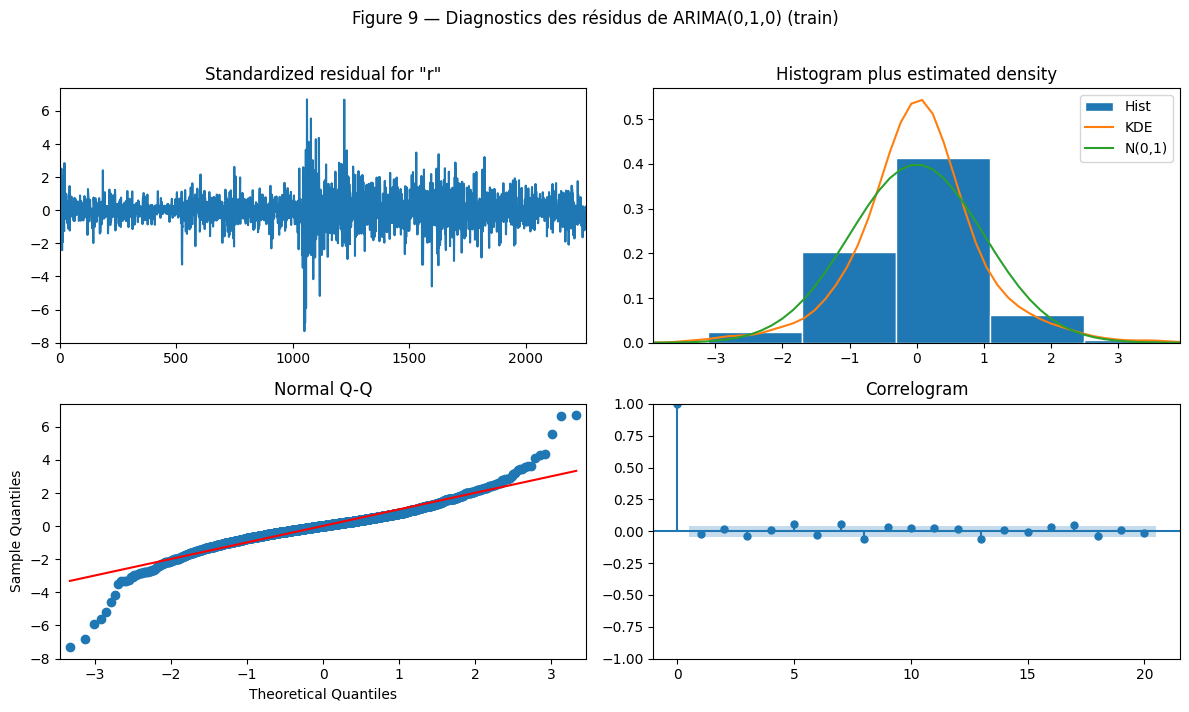

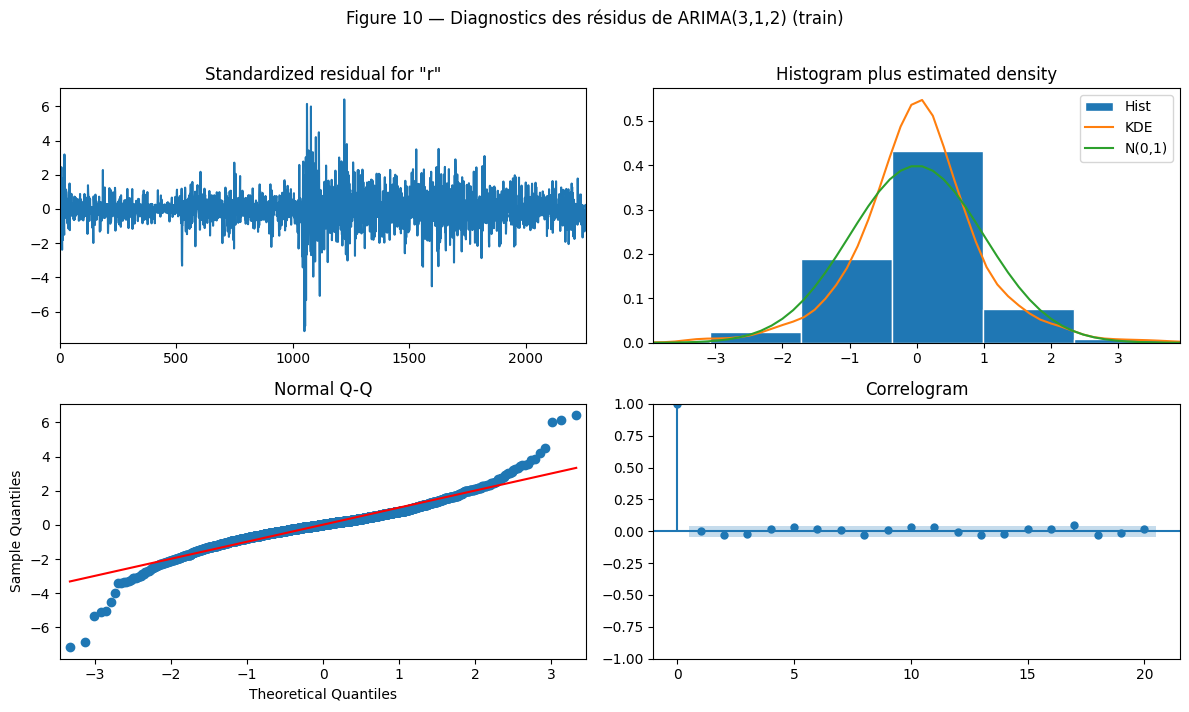

In [41]:
for num, (name, res) in zip((9, 10), retained.items()):
    fig = res.plot_diagnostics(figsize=(12, 7), lags=20)
    fig.suptitle(f"Figure {num} — Diagnostics des résidus de {name} (train)", y=1.01)
    fig.tight_layout()
    save_fig(fig, num, f"diagnostics_{name.replace('(', '').replace(')', '').replace(',', '')}")
    plt.show()

**Interprétation des diagnostics.**

**Autocorrélation des résidus (Ljung-Box).**
- **ARIMA(0,1,0)** : ses résidus sont les rendements eux-mêmes. Le test brut rejette (Q(10) = 34,9, p = 0,0001), mais la version standardisée **ne rejette pas** (p = 0,98 à 10 retards, 0,90 à 20). Comme au §2.3, il n'y a **pas d'autocorrélation dans la moyenne** une fois la volatilité neutralisée.
- **ARIMA(3,1,2)** : malgré ses 5 paramètres, et après correction des degrés de liberté, le test brut rejette encore au seuil de 5 % (p = 0,047 et 0,018). Surtout, la version standardisée **rejette** à 10 retards (p = 0,013), là où la marche aléatoire passe.

Le modèle de l'AIC « nettoie » en apparence le corrélogramme brut (figure 10, plus plat que la figure 9), parce qu'il s'est ajusté aux jours agités de 2020. Mais il **introduit** une structure parasite dans les jours calmes. C'est le symptôme classique d'un sur-ajustement.

**Normalité (Jarque-Bera).** Elle est rejetée pour les deux modèles (JB = 4 142 et 3 376, p < 0,0001 ; excès de kurtosis de 6,6 et 6,0). Sur les graphiques Q-Q, les points s'écartent de la droite aux deux extrémités : les résidus descendent jusqu'à environ −7 écarts-types là où une loi normale s'arrêterait vers −3,3. Il s'agit de **queues épaisses**, surtout à gauche. L'histogramme est plus pointu au centre que la courbe N(0,1).

**Variance conditionnelle (ARCH-LM).** C'est le rejet le plus massif : ARCH-LM(5) = 441 et ARCH-LM(10) = 492 pour la marche aléatoire, et des valeurs comparables pour l'ARIMA(3,1,2), avec p < 0,0001 partout. Sur le graphe des résidus standardisés, les fortes valeurs sont **regroupées** :
- autour de l'observation 1 050, soit le 2020-03-09 ;
- et vers l'observation 1 220, en novembre 2020.

La variance d'un ARIMA est constante par construction : ce modèle ne peut pas représenter ces regroupements.

**Bilan honnête.** Aucun des deux modèles n'a des résidus « bruit blanc gaussien i.i.d. ». Mais leurs échecs sont de nature différente :
- **ARIMA(0,1,0)** décrit correctement la **moyenne** : pas d'autocorrélation résiduelle une fois la volatilité neutralisée. Ce qu'il ne modélise pas, c'est la **variance** (effets ARCH) et la **forme de la loi** (queues épaisses). Ces deux défauts sont exactement ceux que traite un GARCH à loi de Student : ils **justifient la section 3.3**, ils ne disqualifient pas le modèle de moyenne.
- **ARIMA(3,1,2)** ne fait pas mieux sur la variance ni sur la normalité, et fait moins bien sur l'autocorrélation.

**Conséquence pratique.** Les intervalles de prévision gaussiens à variance constante de ces ARIMA seront **trop étroits en période agitée et trop larges en période calme**. On le vérifiera en section 6 en comparant leur couverture à celle des intervalles ARIMA-GARCH.

#### 3.1.5 Décision

| Critère | ARIMA(0,1,0) | ARIMA(3,1,2) | SARIMA s = 5 |
| --- | --- | --- | --- |
| Identification manuelle (ACF/PACF) | ✔ retenu | — | — |
| `auto_arima`, AIC | — | ✔ choisi | — |
| `auto_arima`, BIC | ✔ choisi | — | — |
| Coefficients significatifs (robustes) | aucun à estimer | oui individuellement, mais quasi-annulation des racines | non (p ≥ 0,12) |
| Gain d'AIC robuste (hors 2020, standardisé) | référence | non : il s'inverse | non |
| Résidus sans autocorrélation (LB standardisé) | ✔ p = 0,98 | ✘ p = 0,013 | — |
| Interprétation | prix de demain = prix d'aujourd'hui | cycle de 2,4 jours sans sens économique | effet hebdomadaire inexistant |

**Modèle ARIMA retenu : ARIMA(0,1,0) sans dérive**, c'est-à-dire la **marche aléatoire** : ln P_t = ln P_{t−1} + ε_t, avec σ = √3,184 ≈ 1,78 % par jour.

**Pourquoi ce choix.**
- C'est le choix de l'identification manuelle, du BIC et de tous les contrôles de robustesse.
- Il est cohérent avec l'hypothèse d'**efficience des marchés** : l'information passée sur les prix ne permet pas de prévoir la variation du lendemain.
- La prévision ponctuelle à tout horizon h est simplement le dernier prix observé. C'est pourquoi la marche aléatoire est aussi la **baseline** de la section 6.

**ARIMA(3,1,2) conservé comme modèle concurrent.** C'est le choix de la procédure automatique, et l'écarter sur la seule base de l'échantillon d'apprentissage serait un peu rapide. Il sera donc évalué hors échantillon en section 6, avec le test de Diebold-Mariano. Les diagnostics laissent attendre qu'il ne fasse pas mieux que la marche aléatoire, et il faudra le vérifier plutôt que le supposer.

**Ce qui reste à traiter.**
1. **Effets ARCH massifs** dans les résidus (section 3.3, GARCH).
2. **Queues épaisses** (loi de Student dans le GARCH).
3. **Interactions entre XOM et XLE**, qu'un modèle univarié ignore (section 3.2, VAR et cointégration).

### 3.2 VAR, causalité de Granger et cointégration (train)

**Pourquoi deux niveaux d'analyse.** Le §2.7 a montré que les log-prix de XOM et de XLE sont I(1) et leurs rendements I(0). Chaque outil s'applique donc à la série qui respecte ses hypothèses :
- **Dynamique de court terme : VAR sur les rendements.** Un VAR estimé sur des séries non stationnaires donnerait des tests aux lois non standard, et un risque de régression fallacieuse.
- **Relation de long terme : cointégration sur les log-prix.** La cointégration ne se définit qu'entre séries I(1) : une combinaison linéaire des deux prix peut être stationnaire alors que chaque prix ne l'est pas.

**Si une cointégration existe**, un VAR en différences seul serait mal spécifié, car il oublierait le terme de rappel vers l'équilibre. On estime alors un **VECM**, qui ajoute ce terme au VAR en différences.

On garde la même méthode qu'en 3.1 : chaque résultat est vérifié **hors 2020** et sur **données standardisées par la volatilité passée**, pour distinguer une vraie dynamique d'un effet de l'hétéroscédasticité.

In [42]:
R_pair = TRAIN[["XOM_ret", "XLE_ret"]].dropna()   # rendements en %, 2 261 jours
L_pair = TRAIN[["XOM_logp", "XLE_logp"]]          # log-prix, 2 262 jours
print(f"Corrélation des rendements XOM/XLE (train) : {R_pair.corr().iloc[0, 1]:.3f}")

Corrélation des rendements XOM/XLE (train) : 0.915


#### 3.2.1 Choix de l'ordre du VAR

Quatre critères d'information sont comparés pour un ordre maximal de 10 retards, soit deux semaines de bourse :
- l'**AIC** et le **FPE**, orientés vers la prévision ;
- le **BIC** et le **HQ**, convergents, qui pénalisent davantage les paramètres.

Chaque retard ajoute K² = 4 coefficients.

In [43]:
ic = C.var_ic_table(R_pair)
order_sel = C.var_order_selection(R_pair)
save_table(ic, "tab17_var_criteres")
save_table(order_sel, "tab17b_var_ordre_robustesse")
display(ic.round(4))
order_sel

,AIC,BIC,HQIC,FPE
ordre p,,,,
0,0.6307,0.6358,0.6326,1.8790
1,0.6305,0.6457,0.6360,1.8785
2,0.6211,0.6465,0.6304,1.8610
3,0.6184,0.6540,0.6314,1.8560
4,0.6180,0.6637,0.6347,1.8552
5,0.6173,0.6732,0.6377,1.8539
6,0.6159,0.6820,0.6400,1.8514
7,0.5949,0.6712,0.6228,1.8129
8,0.5951,0.6815,0.6266,1.8132


,AIC,BIC,HQIC,FPE
échantillon complet,9,0,7,9
hors 2020,0,0,0,0
standardisé (vol. 21 j passée),0,0,0,0


**Interprétation du choix d'ordre.**

**Les critères divergent fortement :**

| Critère | Ordre choisi |
| --- | --- |
| AIC | 9 |
| FPE | 9 |
| HQ | 7 |
| BIC | **0** |

Le BIC ne retient aucun retard : pour lui, les rendements de XOM et de XLE n'ont aucune dynamique commune exploitable. La valeur de l'AIC est presque plate de p = 0 à p = 6 (de 0,631 à 0,616), puis **chute d'un coup au retard 7** (0,595). Tout le gain de l'AIC tient donc à ce seul retard. C'est exactement le retard où l'EDA avait trouvé la plus forte autocorrélation de XLE (0,129, §2.3), et elle venait de 2020.

**Le contrôle de robustesse tranche :** hors 2020, comme sur rendements standardisés, **les quatre critères choisissent p = 0**. Les ordres 7 et 9 ne reflètent donc pas une dynamique de la moyenne, mais l'hétéroscédasticité de mars 2020.

**Décision.** Le modèle multivarié le plus fidèle aux données est un **VAR(0)** : un bruit blanc bivarié dont les chocs sont fortement corrélés (corrélation de 0,915), sans aucune dépendance au passé. Un VAR(0) ne permet toutefois aucun test de Granger, puisqu'il n'a pas de retard. On estime donc aussi le **VAR(1)**, le plus petit VAR qui en contienne, ainsi que les VAR(7) et VAR(9) des critères, pour comparer leurs diagnostics.

#### 3.2.2 Estimation et diagnostics du VAR

On estime les VAR désignés par les critères, pour les comparer :
- **VAR(0)** : le choix du BIC et de toutes les versions robustes ;
- **VAR(1)** : le plus petit VAR qui contienne des retards, donc le minimum pour tester une causalité de Granger ;
- **VAR(7)** et **VAR(9)** : les choix du HQ et de l'AIC.

**Diagnostics appliqués à chacun :**
- **stabilité** : module des valeurs propres de la matrice compagnon < 1 ;
- **autocorrélation** : Portmanteau multivarié de Hosking, ajusté, sur résidus bruts puis standardisés ;
- **normalité** : Jarque-Bera multivarié ;
- **effets ARCH** : ARCH-LM équation par équation.

In [44]:
var_fits = {f"VAR({p})": C.fit_var(R_pair, p) for p in (0, 1, 7, 9)}
var_diag = pd.DataFrame([C.var_diagnostics(r, n) for n, r in var_fits.items()]).set_index("modèle")
save_table(var_diag, "tab18_var_diagnostics")
var_diag.round(4).T

modèle,VAR(0),VAR(1),VAR(7),VAR(9)
stable,True,True,True,True
module max (matrice compagnon),0.0000,0.0411,0.8054,0.8054
p Portmanteau(10),0.0000,0.0000,0.0246,0.2415
p Portmanteau(20),0.0000,0.0000,0.0001,0.0003
p Portmanteau(10) standardisé,0.7678,0.0376,0.0000,0.0000
p Portmanteau(20) standardisé,0.4476,0.0334,0.0000,0.0000
JB multivarié,33989.3561,34565.0860,22674.3715,21681.4313
p JB,0.0000,0.0000,0.0000,0.0000
ARCH-LM(5) XOM_ret,443.0082,423.9853,328.2938,321.5098
p ARCH-LM(5) XOM_ret,0.0000,0.0000,0.0000,0.0000


In [45]:
# Coefficients du VAR(1) : estimation complète puis hors 2020, pour juger de leur stabilité.
v1_full = var_fits["VAR(1)"]
v1_ex2020 = C.fit_var(R_pair[R_pair.index.year != 2020], 1)
coefs = pd.concat({"complet": v1_full.params, "p-value (classique)": v1_full.pvalues,
                   "hors 2020": v1_ex2020.params}, axis=1)
save_table(coefs, "tab18b_var1_coefficients")
coefs.round(4)

complet         p-value (classique)         hors 2020        
           XOM_ret XLE_ret             XOM_ret XLE_ret   XOM_ret XLE_ret
const       0.0323  0.0322              0.3896  0.4251    0.0564  0.0546
L1.XOM_ret  0.1010  0.1046              0.0529  0.0626    0.0330 -0.0084
L1.XLE_ret -0.1268 -0.1344              0.0089  0.0100   -0.0082  0.0159

**Interprétation des diagnostics du VAR.**

**Stabilité.** Les quatre VAR sont stables. Les valeurs propres de la matrice compagnon ont un module d'au plus 0,04 pour le VAR(1) et 0,81 pour les VAR(7) et VAR(9), toutes inférieures à 1 : les prévisions convergent vers la moyenne et les réponses aux chocs s'amortissent.

**Autocorrélation des résidus (Portmanteau).** C'est le diagnostic qui départage les modèles :

| Modèle | p brut (h = 10) | p standardisé (h = 10) | p standardisé (h = 20) |
| --- | --- | --- | --- |
| VAR(0) | < 0,0001 | **0,77** | **0,45** |
| VAR(1) | < 0,0001 | 0,038 | 0,033 |
| VAR(7) | 0,025 | < 0,0001 | < 0,0001 |
| VAR(9) | 0,24 | < 0,0001 | < 0,0001 |

- **Résidus bruts.** Ajouter des retards fait disparaître une partie de l'autocorrélation : le VAR(9) passe même à h = 10. Mais ce « nettoyage » porte sur les jours agités de 2020.
- **Résidus standardisés.** Le classement s'inverse. Seul le **VAR(0) est propre** ; plus on ajoute de retards, plus on crée de structure parasite dans les périodes calmes. C'est la même signature de sur-ajustement que pour l'ARIMA(3,1,2) en 3.1.

**Coefficients du VAR(1) : l'origine du problème.**
- **Sur l'échantillon complet**, chaque rendement réagit **positivement** au rendement passé de XOM (+0,10) et **négativement** à celui de XLE (−0,13). Seul ce dernier est significatif en test classique (p ≈ 0,01).
- **Hors 2020**, ces coefficients s'effondrent : +0,03 et −0,01 dans l'équation de XOM, −0,01 et +0,02 dans celle de XLE.

La dynamique estimée vient presque entièrement des journées de mars 2020. Avec des régresseurs aussi corrélés (0,915), deux coefficients opposés reviennent d'ailleurs à un effet de l'**écart** de la veille entre XOM et XLE.

**Normalité et effets ARCH.**
- La normalité est massivement rejetée : Jarque-Bera multivarié entre 21 681 et 34 565.
- Les effets ARCH le sont aussi : ARCH-LM(5) entre 321 et 458 selon le modèle et l'équation, avec p < 0,0001 partout.

Comme en 3.1, ces deux défauts concernent la variance et la forme de la loi, et relèvent d'un modèle GARCH (§3.3). La corrélation entre les résidus des deux équations (≈ 0,915) montre que l'essentiel du lien entre XOM et XLE est **contemporain** : les deux actifs bougent le même jour, pas l'un après l'autre.

#### 3.2.3 Causalité de Granger

**Définition.** « X cause Y au sens de Granger » signifie que les valeurs passées de X **améliorent la prévision** de Y, une fois connues les valeurs passées de Y. Il s'agit d'une **prédictibilité incrémentale**, pas d'une causalité économique : deux séries peuvent se « causer » au sens de Granger simplement parce qu'elles réagissent avec des délais différents à une même information.

**Test.** Pour chaque équation, on teste H₀ : tous les coefficients des retards de l'autre variable sont nuls, en trois versions :
- **F classique** : le test standard du VAR, qui suppose des erreurs homoscédastiques ;
- **Wald robuste HC3** : corrige l'hétéroscédasticité ;
- **Wald HAC** (Newey-West, 7 retards) : corrige aussi l'autocorrélation.

Le test est fait pour p = 1, 7 et 9, sur l'échantillon complet puis hors 2020.

In [46]:
granger = C.granger_tests(R_pair)
save_table(granger, "tab19_granger")
granger.round(4)

p classique  p HC3  p HAC
échantillon         retards p sens                                        
échantillon complet 1         XLE_ret → XOM_ret       0.0089 0.1954 0.0908
                              XOM_ret → XLE_ret       0.0627 0.4210 0.2069
                    7         XLE_ret → XOM_ret       0.0000 0.0339 0.0085
                              XOM_ret → XLE_ret       0.0028 0.5151 0.0170
                    9         XLE_ret → XOM_ret       0.0000 0.0162 0.0016
                              XOM_ret → XLE_ret       0.0056 0.6351 0.0427
hors 2020           1         XLE_ret → XOM_ret       0.8708 0.8894 0.8812
                              XOM_ret → XLE_ret       0.8732 0.8929 0.8861
                    7         XLE_ret → XOM_ret       0.0549 0.0893 0.1174
                              XOM_ret → XLE_ret       0.0257 0.0551 0.0471
                    9         XLE_ret → XOM_ret       0.0916 0.1791 0.1870
                              XOM_ret → XLE_ret       0.0466 0.1024 0.1208

**Interprétation des tests de Granger.**

**La conclusion dépend entièrement de l'inférence utilisée et de l'échantillon :**

| Retards | Sens | F classique | HC3 robuste | HAC | HC3 hors 2020 |
| --- | --- | --- | --- | --- | --- |
| 1 | XLE → XOM | **0,009** | 0,195 | 0,091 | 0,889 |
| 1 | XOM → XLE | 0,063 | 0,421 | 0,207 | 0,893 |
| 7 | XLE → XOM | **< 0,001** | **0,034** | **0,009** | 0,089 |
| 7 | XOM → XLE | **0,003** | 0,515 | **0,017** | 0,055 |
| 9 | XLE → XOM | **< 0,001** | **0,016** | **0,002** | 0,179 |
| 9 | XOM → XLE | **0,006** | 0,635 | **0,043** | 0,102 |

(En gras : rejet de H₀ au seuil de 5 %.)

**Lecture.**
1. **Le test F classique** trouve une causalité partout ou presque. Mais il suppose une variance constante, ce que les tests ARCH-LM réfutent, et il rejette donc trop souvent.
2. **Avec une erreur-type robuste** (HC3), la causalité disparaît à 1 retard. À 7 et 9 retards, il ne reste que le sens **XLE → XOM**.
3. **Hors 2020**, plus aucun test robuste ne rejette au seuil de 5 %. Avec 7 retards, quelques p-values restent proches du seuil (0,055 en HC3 pour XOM → XLE, 0,047 en HAC), mais sans régularité d'un réglage à l'autre.

**Conclusion.** Il n'y a **pas de prédictibilité croisée robuste** entre les rendements de XOM et de XLE. Le seul signal, le passé de XLE aidant à prévoir XOM, n'apparaît qu'avec 7 à 9 retards, sur l'échantillon qui contient 2020. Il disparaît sans cette année.

**Interprétation prudente.** Même là où il est significatif, ce résultat signifierait seulement que « le passé de XLE aide à prévoir XOM », **pas** que « XLE cause XOM ». Les deux actifs réagissent à la même information sectorielle (prix du pétrole, demande), et un décalage d'un jour peut venir de différences de liquidité ou d'heure de cotation sans lien causal.

L'absence de prédictibilité croisée est cohérente avec l'**efficience des marchés** : si le passé de l'ETF permettait de prévoir l'action, cette information serait exploitée et disparaîtrait des prix.

#### 3.2.4 Cointégration des log-prix

**Engle-Granger (deux étapes).** On régresse un log-prix sur l'autre, puis on teste la racine unitaire du résidu. H₀ : pas de cointégration. Les valeurs critiques de MacKinnon sont plus sévères que celles d'un ADF simple, puisque le résidu est estimé. Le test est fait dans les deux sens, car il n'est pas symétrique, avec une constante puis avec une constante et une tendance.

**Johansen.** Il teste directement le **rang** r de cointégration dans un VAR en niveaux, avec deux statistiques :
- la **trace**, qui teste H₀ : r ≤ r₀ ;
- la **valeur propre maximale**, qui teste H₀ : r = r₀ contre r = r₀ + 1.

On lit les tests de façon séquentielle : d'abord r = 0, puis r ≤ 1 si le premier est rejeté.

Le nombre de retards en différences k dépend du choix d'ordre fait en 3.2.1. On présente donc les trois valeurs possibles : k = 0 (VAR(1) en niveaux, choix du BIC et des versions robustes), k = 6 (HQ) et k = 8 (AIC).

In [47]:
eg = C.engle_granger(L_pair)
save_table(eg, "tab20_engle_granger")
eg.round(4)

statistique  valeur critique 5 %  p-value  H0 rejetée (5 %)
régression            déterministe                                                                     
XOM_logp sur XLE_logp constante                 -3.4565              -3.3388   0.0365              True
                      constante + tendance      -3.4753              -3.7848   0.1050             False
XLE_logp sur XOM_logp constante                 -3.6092              -3.3388   0.0239              True
                      constante + tendance      -3.6374              -3.7848   0.0719             False

In [48]:
joh = C.johansen_table(L_pair, {"k = 0 (BIC, robuste)": 0, "k = 6 (HQ)": 6, "k = 8 (AIC)": 8})
save_table(joh, "tab21_johansen")
joh.round(2)

trace  VC trace 10 %  VC trace 5 %    λmax  VC λmax 10 %  VC λmax 5 %        trace : décision λmax : décision
retards (Δ)          H0                                                                                                                   
k = 0 (BIC, robuste) r = 0 14.7300        13.4300       15.4900 12.1900       12.3000      14.2600  rejet à 10 % seulement       non rejet
                     r ≤ 1  2.5300         2.7100        3.8400  2.5300        2.7100       3.8400               non rejet       non rejet
k = 6 (HQ)           r = 0 15.8000        13.4300       15.4900 15.1300       12.3000      14.2600             rejet à 5 %     rejet à 5 %
                     r ≤ 1  0.6700         2.7100        3.8400  0.6700        2.7100       3.8400               non rejet       non rejet
k = 8 (AIC)          r = 0 21.6300        13.4300       15.4900 21.1400       12.3000      14.2600             rejet à 5 %     rejet à 5 %
                     r ≤ 1  0.4900         2.7100        3.8400  0.4900        2.7100       3.8400               non rejet       non rejet

In [49]:
# Stabilité de la relation : est-elle présente dans chaque moitié du train, de part et d'autre de 2020 ?
subp = C.cointegration_subperiods(L_pair, {"2016-2019": ("2016", "2019"), "2021-2024": ("2021", "2024"),
                                           "2016-2024 (train complet)": ("2016", "2024")})
save_table(subp, "tab22_cointegration_sous_periodes")
subp.round(3)

,n,Engle-Granger p-value,Johansen trace (r = 0),VC 10 %,VC 5 %
période,,,,,
2016-2019,1006,0.0810,14.3320,13.4290,15.4940
2021-2024,1003,0.2320,10.5540,13.4290,15.4940
2016-2024 (train complet),2262,0.0360,14.7260,13.4290,15.4940


**Interprétation des tests de cointégration.** Les résultats sont **ambigus** et sont rapportés comme tels.

**Engle-Granger.**
- **Avec constante**, l'absence de cointégration est rejetée au seuil de 5 % dans les deux sens : statistique −3,46, p = 0,037 (XOM sur XLE) ; −3,61, p = 0,024 (XLE sur XOM). La valeur critique est −3,34.
- **Avec une tendance en plus**, elle ne l'est plus : p = 0,105 et 0,072.

La tendance n'est de toute façon pas justifiée, puisque la dérive des rendements n'est pas significative (§2.2). La spécification « constante » est la plus pertinente.

**Johansen.** Le verdict dépend du nombre de retards :

| Retards en différences | Trace (r = 0) | λmax (r = 0) | Décision |
| --- | --- | --- | --- |
| k = 0 (BIC, robuste) | 14,73 | 12,19 | trace : rejet à 10 % seulement (VC à 5 % : 15,49) ; λmax : non rejet |
| k = 6 (HQ) | 15,80 | 15,13 | rejet à 5 % |
| k = 8 (AIC) | 21,63 | 21,14 | rejet à 5 % |

Dans les trois cas, r ≤ 1 n'est pas rejeté. S'il y a cointégration, il y a donc **au plus une** relation.

Or les retards 6 et 8 sont précisément ceux que les contrôles de robustesse ont attribués à 2020 (§3.2.1). Avec l'ordre robuste (k = 0), Johansen ne rejette qu'au seuil de **10 %**.

**Sous-périodes.** La relation n'est **significative dans aucune moitié** du train prise séparément :
- 2016–2019 : Engle-Granger p = 0,081, trace 14,33 ;
- 2021–2024 : Engle-Granger p = 0,232, trace 10,55.

On ne peut toutefois pas en conclure qu'elle est absente. Avec quatre ans de données chacune, ces sous-périodes offrent moins de puissance pour détecter un retour lent à l'équilibre.

**Verdict.** La cointégration XOM/XLE est **faible et fragile**. Elle est significative à 5 % avec Engle-Granger (spécification avec constante), mais seulement à 10 % avec Johansen sous l'ordre robuste, et elle n'est stable dans aucune des deux sous-périodes. Le retour à l'équilibre est donc, au mieux, lent et imparfait.

**Un lien en partie mécanique.** XOM est le **premier composant** de l'ETF XLE : **24,47 %** de l'ETF au 5 novembre 2026, devant Chevron (18,78 %) ([StockAnalysis, positions de XLE](https://stockanalysis.com/etf/xle/holdings/)). D'autres relevés de 2026 donnent 22 à 23 %. Cette pondération varie dans le temps, et sa valeur exacte sur 2016–2024 n'est pas vérifiée ici. Avec environ un quart de l'ETF, une partie de la relation entre les deux prix tient en tout cas à la construction même de l'indice. Les écarts, eux, viennent de tout ce qui distingue XOM du reste du secteur : résultats propres à l'entreprise, rachats d'actions, différence d'exposition au raffinage.

**Décision.** Le cahier demande un VECM si une cointégration est détectée. On estime donc un VECM avec **r = 1**, retenu au seuil de 10 %, et on l'interprète **conditionnellement** : il décrit le retour à l'équilibre *si* la relation existe.

#### 3.2.5 VECM

**Spécification.**
- **Rang** r = 1, avec k = 0 retard en différences (cohérent avec l'ordre robuste du VAR).
- **Constante restreinte** à la relation de cointégration (« ci ») : la dérive n'est pas significative (§2.2, §3.1), il n'y a donc pas de tendance linéaire dans les niveaux.

**Forme du modèle.**

  Δy_t = α (β′y_{t−1} + c) + ε_t,  avec y_t = (ln XOM_t, ln XLE_t)′

- **β** est la relation d'équilibre de long terme, normalisée sur XOM.
- **z_t = β′y_t + c** est l'écart à cet équilibre.
- **α** mesure la réaction de chaque actif à cet écart.

**Demi-vie.** L'écart évolue selon z_t = (1 + β′α) z_{t−1} + bruit. Sa demi-vie vaut donc **ln(0,5) / ln(1 + β′α)**. C'est la généralisation à deux variables de la formule ln(0,5)/ln(1 + α) du plan, qui suppose qu'un seul actif s'ajuste. On la recoupe avec la demi-vie d'un AR(1) estimé directement sur l'écart.

In [50]:
vecm = C.fit_vecm(L_pair, k_ar_diff=0, rank=1)
vecm_tab = C.vecm_summary(vecm, ["XOM", "XLE"])
save_table(vecm_tab, "tab23_vecm")
display(vecm_tab.round(5))

beta = vecm.beta.ravel()
spread = pd.Series(L_pair.to_numpy() @ beta + vecm.const_coint.ravel()[0], index=L_pair.index, name="écart")
hl = C.spread_half_life(spread)
print(f"Contrôle : AR(1) de l'écart, ρ = {hl['rho']:.4f}, demi-vie = {hl['demi-vie (jours)']:.1f} jours de bourse")
print(f"Écart : moyenne = {spread.mean():.4f}, écart-type = {spread.std():.4f}, "
      f"min = {spread.min():.3f} le {spread.idxmin().date()}, max = {spread.max():.3f} le {spread.idxmax().date()}")

,valeur,p-value
paramètre,,
β (XOM),1.0000,NaN
β (XLE),-1.1282,NaN
constante de la relation,-0.4531,NaN
α (XOM),-0.0006,0.9279
α (XLE),0.0093,0.1594
vitesse de l'écart β'α,-0.0110,NaN
demi-vie de l'écart (jours de bourse),62.5794,NaN


Contrôle : AR(1) de l'écart, ρ = 0.9890, demi-vie = 62.6 jours de bourse
Écart : moyenne = -0.0003, écart-type = 0.0613, min = -0.150 le 2018-05-04, max = 0.268 le 2020-03-18


In [51]:
vecm_diag = pd.DataFrame([C.vecm_diagnostics(vecm, "VECM (r = 1, k = 0)")]).set_index("modèle")
save_table(vecm_diag, "tab24_vecm_diagnostics")
vecm_diag.round(4).T

modèle,"VECM (r = 1, k = 0)"
p Portmanteau(10),0.0000
p Portmanteau(20),0.0000
p Portmanteau(10) standardisé,0.5310
p Portmanteau(20) standardisé,0.3551
JB multivarié,34529.3069
p JB,0.0000
p ARCH-LM(5) éq. 1,0.0000
p ARCH-LM(5) éq. 2,0.0000


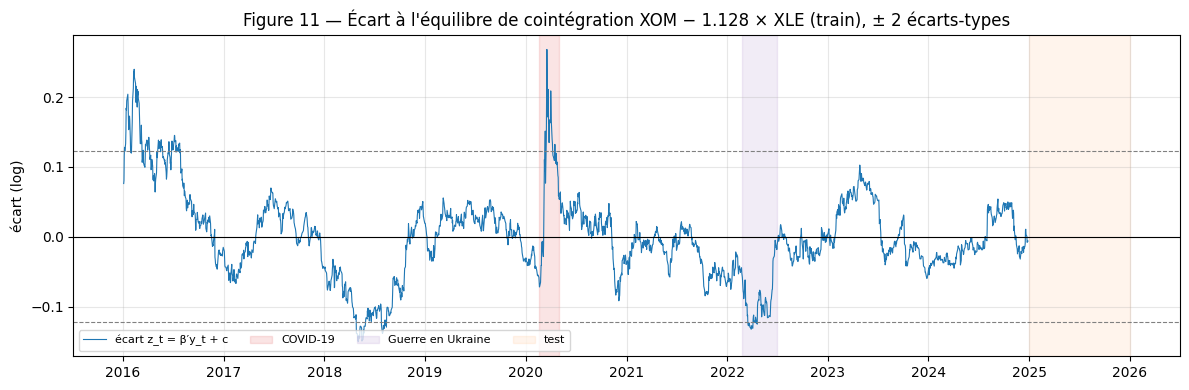

In [52]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(spread.index, spread, lw=0.8, color="tab:blue", label="écart z_t = β′y_t + c")
m, s = spread.mean(), spread.std()
ax.axhline(m, color="black", lw=0.8)
for k in (-2, 2):
    ax.axhline(m + k * s, color="grey", ls="--", lw=0.8)
shade(ax, legend=True)
ax.set_ylabel("écart (log)")
ax.set_title(f"Figure 11 — Écart à l'équilibre de cointégration XOM − {-beta[1]:.3f} × XLE (train), ± 2 écarts-types")
ax.legend(loc="lower left", fontsize=8, ncol=4)
ax.grid(alpha=0.3)
fig.tight_layout()
save_fig(fig, 11, "ecart_cointegration")
plt.show()

**Interprétation du VECM.**

**Relation de long terme (β).** L'équilibre s'écrit

  ln XOM ≈ 1,128 × ln XLE − 0,453.

À long terme, une hausse de 1 % de XLE va de pair avec une hausse d'environ 1,13 % de XOM. XOM est donc un peu plus sensible que la moyenne de son secteur, ce qui est un ordre de grandeur plausible pour une major pétrolière.

**L'écart à l'équilibre (figure 11).** Il oscille autour de zéro (moyenne −0,0003, écart-type 0,061), mais par **longues excursions** de plusieurs mois :
- début 2016 : environ +0,24, la série partant loin de l'équilibre ;
- mi-2018 : creux de −0,15 le 2018-05-04 ;
- **18 mars 2020** : pic de **+0,27**. Ce jour-là, XLE a perdu nettement plus que XOM (−15,5 % contre −10,6 %) ;
- début 2022 : creux d'environ −0,13.

Un écart de 0,1 en log correspond à environ 10 % de sur- ou sous-valorisation relative.

**Vitesse d'ajustement (α).**
- α(XOM) = −0,0006 (p = 0,93) : XOM **ne s'ajuste pas** à l'écart.
- α(XLE) = +0,0093 (p = 0,16) : si l'ajustement existe, il passe plutôt par **XLE**. Quand XOM est cher relativement au secteur (écart positif), c'est XLE qui monte pour combler l'écart. Ce coefficient **n'est pas significatif** au seuil de 5 %.

Aucun des deux α n'est significatif, ce qui est cohérent avec la faiblesse de la cointégration en 3.2.4 : la force de rappel existe peut-être, mais elle est trop faible pour être mesurée avec précision.

**Demi-vie.** La vitesse de retour de l'écart vaut β′α = −0,0110. Elle donne une **demi-vie de 62,6 jours de bourse**, soit environ trois mois : il faut ~3 mois pour résorber la moitié d'un écart. Un AR(1) estimé directement sur l'écart donne la même valeur (ρ = 0,989, 62,6 jours), ce qui confirme le calcul.

**Pourquoi β′α et pas un α seul.** La formule du plan, ln(0,5)/ln(1 + α), ne s'applique que si un seul actif s'ajuste. Appliquée à α(XOM) = −0,0006, elle donnerait plus de 1 200 jours ; appliquée à α(XLE), positif, elle n'a pas de sens. Quand les deux actifs bougent, c'est la combinaison β′α qui mesure la vitesse de l'écart.

**Diagnostics du VECM.**
- **Autocorrélation.** Le Portmanteau brut rejette, mais la version standardisée **ne rejette pas** (p = 0,53 à h = 10, 0,36 à h = 20) : le VECM ne laisse pas d'autocorrélation dans la moyenne. Contrairement au VAR(1), il ne crée pas de structure parasite.
- **Normalité et effets ARCH** : massivement rejetés, comme pour tous les modèles précédents (Jarque-Bera = 34 529 ; ARCH-LM p < 0,0001).

**Portée pratique.** Une demi-vie de trois mois est longue face à l'horizon de prévision du projet (h = 10 jours) : en 10 jours, le rappel ne corrige qu'environ 1 − 0,989¹⁰ ≈ 10 % d'un écart. On ne doit donc pas attendre du VECM un gain de prévision notable à court terme sur la marche aléatoire, ce que la section 6 vérifiera.

#### 3.2.6 Réponses impulsionnelles (IRF) et décomposition de la variance (FEVD)

**Ce que mesurent ces deux outils.**
- **L'IRF** répond à la question : « si XLE subit aujourd'hui un choc inattendu, comment XOM réagit-elle les jours suivants ? » Elle décrit la direction, l'amplitude et la persistance de la réponse.
- **La FEVD** mesure quelle part de l'incertitude de prévision de XOM à l'horizon h provient des chocs de chaque variable.

**Identification.** Les chocs des deux équations sont fortement corrélés le même jour (0,915). Pour les séparer, on utilise une décomposition de Cholesky, qui impose une **hiérarchie contemporaine** : la première variable peut faire bouger la seconde le jour même, pas l'inverse. Cet ordre est une **hypothèse d'identification**, pas un choix technique. On présente donc les deux ordres possibles, pour voir quelles conclusions en dépendent :
- **XLE → XOM** : une nouvelle sectorielle (prix du pétrole, demande) touche tout le secteur, donc XOM, le jour même ;
- **XOM → XLE** : une nouvelle propre à XOM fait bouger mécaniquement l'ETF, dont XOM représente environ un quart.

Les IRF sont calculées sur le VAR(1), le plus petit VAR à retards (§3.2.2), avec des intervalles à 95 % (± 1,96 erreur-type asymptotique).

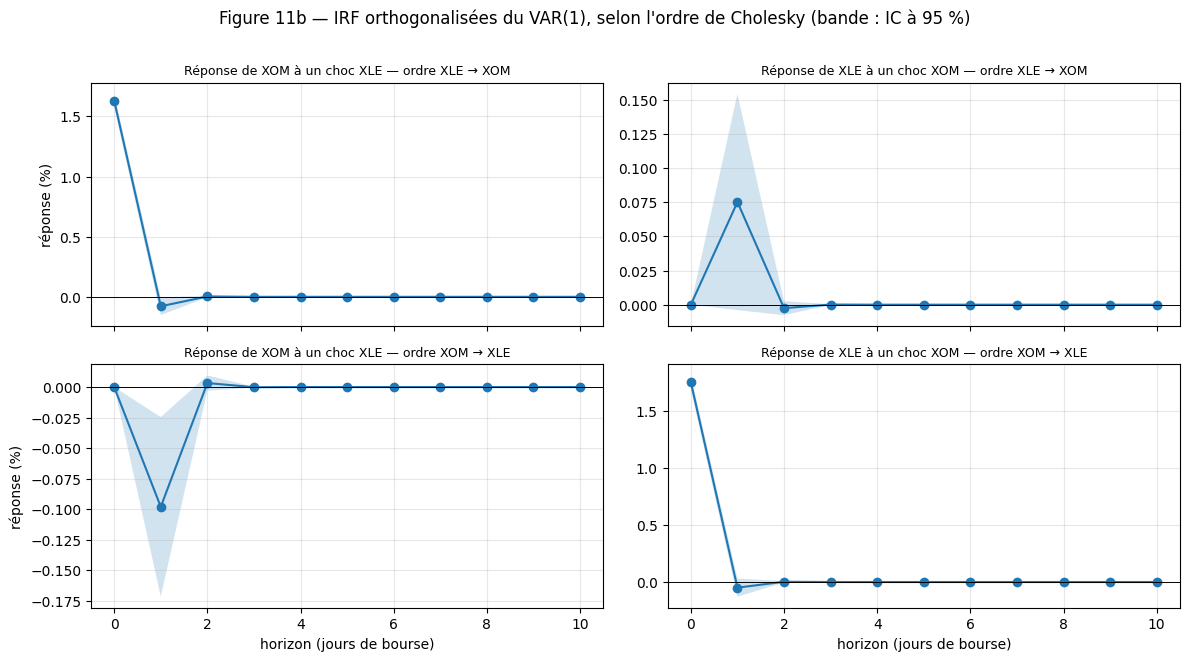

Réponses pour l'ordre XLE → XOM (h = 0 à 3) :


ordre de Cholesky  réponse (%)  erreur-type  significative (|t| > 1,96)
choc    réponse de h                                                                         
XOM_ret XLE_ret    0  XLE_ret → XOM_ret       0.0000       0.0000                       False
                   1  XLE_ret → XOM_ret       0.0752       0.0404                       False
                   2  XLE_ret → XOM_ret      -0.0025       0.0026                       False
                   3  XLE_ret → XOM_ret       0.0001       0.0002                       False
XLE_ret XOM_ret    0  XLE_ret → XOM_ret       1.6309       0.0286                        True
                   1  XLE_ret → XOM_ret      -0.0786       0.0375                        True
                   2  XLE_ret → XOM_ret       0.0031       0.0033                       False
                   3  XLE_ret → XOM_ret      -0.0001       0.0002                       False

,ordre de Cholesky,variable prévue,horizon h,part due au choc XLE_ret,part due au choc XOM_ret
0,XLE_ret → XOM_ret,XLE_ret,1,1.0000,0.0000
1,XLE_ret → XOM_ret,XLE_ret,5,0.9985,0.0015
2,XLE_ret → XOM_ret,XLE_ret,10,0.9985,0.0015
3,XLE_ret → XOM_ret,XOM_ret,1,0.8373,0.1627
4,XLE_ret → XOM_ret,XOM_ret,5,0.8362,0.1638
5,XLE_ret → XOM_ret,XOM_ret,10,0.8362,0.1638
6,XOM_ret → XLE_ret,XOM_ret,1,0.0000,1.0000
7,XOM_ret → XLE_ret,XOM_ret,5,0.0030,0.9970
8,XOM_ret → XLE_ret,XOM_ret,10,0.0030,0.9970
9,XOM_ret → XLE_ret,XLE_ret,1,0.1627,0.8373


In [53]:
irf_res, irf_tabs, fevd_tabs = {}, [], []
for order in (["XLE_ret", "XOM_ret"], ["XOM_ret", "XLE_ret"]):
    v_o, irf_o, rt, ft = C.irf_fevd(R_pair, order, p=1, horizon=10)
    irf_res[" → ".join(order)] = (irf_o, order)
    irf_tabs.append(rt)
    fevd_tabs.append(ft)
irf_tab = pd.concat(irf_tabs, ignore_index=True)
fevd_tab = pd.concat(fevd_tabs, ignore_index=True)
save_table(irf_tab, "tab24b_irf", index=False)
save_table(fevd_tab, "tab24c_fevd", index=False)

fig, axes = plt.subplots(2, 2, figsize=(12, 6.5), sharex=True)
for row, (lab, (irf_o, order)) in zip(axes, irf_res.items()):
    resp, se = irf_o.orth_irfs, irf_o.stderr(orth=True)
    h = np.arange(resp.shape[0])
    for ax, (shock, rep) in zip(row, [("XLE_ret", "XOM_ret"), ("XOM_ret", "XLE_ret")]):
        i, j = order.index(rep), order.index(shock)
        ax.plot(h, resp[:, i, j], marker="o", color="tab:blue")
        ax.fill_between(h, resp[:, i, j] - 1.96 * se[:, i, j], resp[:, i, j] + 1.96 * se[:, i, j], alpha=0.2)
        ax.axhline(0, color="black", lw=0.7)
        ax.set_title(f"Réponse de {rep[:3]} à un choc {shock[:3]} — ordre {lab.replace('_ret', '')}", fontsize=9)
        ax.grid(alpha=0.3)
for ax in axes[1]:
    ax.set_xlabel("horizon (jours de bourse)")
for ax in axes[:, 0]:
    ax.set_ylabel("réponse (%)")
fig.suptitle("Figure 11b — IRF orthogonalisées du VAR(1), selon l'ordre de Cholesky (bande : IC à 95 %)", y=1.01)
fig.tight_layout()
fig.savefig(ROOT / "outputs/figures/fig11b_irf.png", dpi=150, bbox_inches="tight")
plt.show()

print("Réponses pour l'ordre XLE → XOM (h = 0 à 3) :")
display(irf_tab[(irf_tab["ordre de Cholesky"] == "XLE_ret → XOM_ret") & (irf_tab["h"] <= 3) & (irf_tab["choc"] != irf_tab["réponse de"])]
        .round(4).set_index(["choc", "réponse de", "h"]))
fevd_tab.round(4)

**Interprétation des IRF et de la FEVD** (checklist du cours : quel choc, quelle réponse, quand le maximum, à quelle vitesse elle s'atténue, quand la bande inclut zéro).

**IRF, ordre XLE → XOM.**
- **Quel choc, quelle réponse.** Un choc d'un écart-type sur XLE.
- **Quand le maximum.** XOM réagit **le jour même** de **+1,63 %** (erreur-type 0,03, très significatif).
- **À quelle vitesse elle s'atténue.** Le lendemain, la réponse est déjà de signe opposé et minuscule (−0,08 %, erreur-type 0,04 : la bande touche presque zéro). Dès le 2ᵉ jour, elle est nulle (0,003).
- **Dans l'autre sens.** Un choc propre à XOM n'affecte XLE que le lendemain (+0,08 %), et ce n'est pas significatif (|t| ≈ 1,9).

**Le même schéma apparaît avec l'ordre inverse** : tout se passe le jour 0, plus rien après le jour 1. **Conclusion robuste aux deux ordres : il n'y a pas de transmission retardée entre XOM et XLE.** Un choc est absorbé par les deux prix dans la journée. C'est la version dynamique de la conclusion du test de Granger, et elle est cohérente avec l'efficience des marchés. La petite réponse du jour 1 hérite en outre de la fragilité des coefficients du VAR(1), tirés par 2020 (§3.2.2).

**FEVD : le résultat dépend entièrement de l'ordre.**

| Ordre de Cholesky | Part de l'incertitude de prévision de XOM due aux chocs de XLE (h = 1, 5, 10) | Part de celle de XLE due aux chocs de XOM |
| --- | --- | --- |
| XLE → XOM | 83,7 %, 83,6 %, 83,6 % | 0 %, 0,15 %, 0,15 % |
| XOM → XLE | 0 %, 0,3 %, 0,3 % | 83,7 %, 83,5 %, 83,5 % |

- **D'où viennent ces 83,7 %.** C'est exactement le carré de la corrélation contemporaine des chocs (0,915² = 0,837). La FEVD ne fait ici qu'attribuer **la covariance du jour même** à la variable placée en premier.
- **Les parts ne changent pas avec l'horizon**, de h = 1 à h = 10. Contrairement au cas typique du cours (diapo 26), il n'y a **aucune transmission croisée qui se renforcerait à moyen terme**, puisqu'il n'y a pas de dynamique retardée.

**Ce qu'on peut et ce qu'on ne peut pas conclure.**
- **On peut conclure** que XOM et XLE partagent un très gros choc commun quotidien (83,7 % de variance commune) et qu'aucun ne transmet d'information à l'autre avec retard.
- **On ne peut pas conclure** « qui entraîne qui » le jour même. Les deux ordres sont économiquement défendables (choc sectoriel contre poids de XOM dans l'ETF), et les données ne permettent pas de trancher. Comme le dit le cours (diapo 24), on ne choisit pas l'ordre qui donne le résultat le plus convaincant. Il faudrait des restrictions structurelles supplémentaires (SVAR) ou des données intrajournalières, ce qui dépasse le cadre du projet.

#### 3.2.7 Décision

| Question | Réponse | Preuve principale |
| --- | --- | --- |
| Dynamique de court terme entre les rendements ? | **Non** : VAR(0) | tous les critères choisissent p = 0 hors 2020 et sur rendements standardisés ; seul VAR(0) passe le Portmanteau standardisé (p = 0,77) |
| Lien entre XOM et XLE ? | **Oui, mais contemporain** | corrélation des chocs de 0,915 le même jour |
| Réponse à un choc (IRF) ? | **Le jour même, nulle dès le 2ᵉ jour** | robuste aux deux ordres de Cholesky ; la FEVD (83,7 % ou 0,3 %) dépend entièrement de l'ordre, donc la répartition contemporaine n'est pas identifiable |
| Causalité de Granger ? | **Pas de prédictibilité croisée robuste** | rejet seulement en F classique ; robuste hors 2020 : aucun rejet à 5 % |
| Cointégration des log-prix ? | **Faible et fragile** | Engle-Granger p = 0,037 ; Johansen (ordre robuste) au seuil de 10 % seulement ; non significative par sous-période |
| Retour à l'équilibre ? | **Lent et imprécis** | demi-vie de 62,6 jours ; aucun α significatif |

**Modèles conservés pour la section 6 (prévision).**
- **VAR(1)** sur les rendements, comme représentant du VAR. C'est le plus petit VAR à retards, mais ses coefficients sont tirés par 2020 : il servira de point de comparaison.
- **VECM** (r = 1, k = 0), comme modèle de cointégration. Évalué hors échantillon, il dira si le faible rappel vers l'équilibre apporte quelque chose à 10 jours.
- La **marche aléatoire** reste la référence. Elle équivaut d'ailleurs au VAR(0) sans constante.

**Limites à garder en tête.**
1. Tous les tests multivariés de cette section supposent une variance constante. L'hétéroscédasticité massive peut fausser le niveau réel des tests de Johansen, d'où la prudence sur le verdict de cointégration.
2. Le lien entre XOM et XLE est en partie **mécanique**, XOM pesant environ un quart de l'ETF (24,47 % en novembre 2026).
3. Les résidus de tous les modèles gardent des effets ARCH et des queues épaisses, ce qui justifie la section 3.3.

### 3.3 Volatilité conditionnelle : ARCH et GARCH (rendements de XOM, train)

**Pourquoi cette section.** Tous les modèles précédents (ARIMA, VAR, VECM) laissent des résidus à effets ARCH massifs (§3.1.4, §3.2.2). Leur variance est constante par construction, alors que celle des rendements ne l'est manifestement pas. Le GARCH modélise justement la **variance conditionnelle** σ²_t, c'est-à-dire l'amplitude attendue du rendement de demain sachant le passé.

**Modèle complet.** On garde pour la moyenne le choix du §3.1, la marche aléatoire sans dérive :

  r_t = ε_t,  ε_t = σ_t z_t,  z_t i.i.d. de variance 1

  σ²_t = ω + α ε²_{t−1} + γ ε²_{t−1} 1[ε_{t−1} < 0] + β σ²_{t−1}

- **ω** est la constante de la variance.
- **α** mesure l'effet du choc d'hier (« ARCH »).
- **β** mesure l'inertie de la variance (« GARCH »).
- **γ**, seulement dans le GJR-GARCH, est un supplément de réaction aux **baisses** : c'est l'effet de levier.

**Convention de notation.** Elle suit la bibliothèque `arch` : GARCH(p, q) a p termes α et q termes β. Ainsi, GARCH(1,2) a un terme α et deux termes β.

**Piège à retenir.** Un GARCH ne prévoit **pas le sens** du prix, seulement l'**amplitude** probable de ses variations.

In [54]:
# Point de départ exigé par le plan : effets ARCH dans les résidus du modèle de moyenne retenu (ARIMA(0,1,0)).
from statsmodels.stats.diagnostic import het_arch

r_xom = TRAIN["XOM_ret"].dropna()
resid_rw = r_train.to_numpy()   # résidus de la marche aléatoire sans dérive = rendements
arch_start = pd.DataFrame({f"ARCH-LM({k})": dict(zip(["statistique", "p-value"], het_arch(resid_rw, nlags=k)[:2]))
                           for k in (5, 10)}).T
arch_start

,statistique,p-value
ARCH-LM(5),441.1677,0.0000
ARCH-LM(10),491.5506,0.0000


**Interprétation du test ARCH-LM de départ.** Le test régresse les résidus au carré ε²_t sur leurs propres retards, sous H₀ : « pas d'effet ARCH, variance conditionnelle constante ». Sur les résidus de la marche aléatoire, il donne ARCH-LM(5) = 441,2 et ARCH-LM(10) = 491,6, avec p < 0,0001 : **H₀ est massivement rejetée**.

Les gros chocs d'hier annoncent donc de gros chocs aujourd'hui, ce qui confirme l'ACF des rendements au carré (figure 5, §2.3). La modélisation de la variance conditionnelle n'est pas une option : c'est la principale structure exploitable de cette série.

#### 3.3.1 Comparaison des spécifications

On compare **quatre structures**, chacune estimée avec **trois lois** pour z_t :

| Structure | Rôle | Loi | Rôle |
| --- | --- | --- | --- |
| GARCH(1,1) | référence | normale | référence |
| GARCH(1,2) et GARCH(2,1) | ordres supérieurs demandés par le plan | Student | queues épaisses (§2.2) |
| GJR(1,1) | effet de levier | Student asymétrique | asymétrie en plus |

Pour chaque modèle, on vérifie que les contraintes qui garantissent une variance positive sont respectées (ω > 0 ; α, γ, β ≥ 0) et que la persistance est inférieure à 1.

In [55]:
garch_specs = {"GARCH(1,1)": dict(p=1, q=1), "GARCH(1,2)": dict(p=1, q=2),
               "GARCH(2,1)": dict(p=2, q=1), "GJR(1,1)": dict(p=1, o=1, q=1)}
garch_tab = C.garch_compare(r_xom, garch_specs)
save_table(garch_tab, "tab25_garch_comparaison")
garch_tab.round(3)

,,nb paramètres,log-vraisemblance,AIC,BIC,ΔAIC,"ω > 0 et α, γ, β ≥ 0",ΔBIC,persistance,persistance < 1,demi-vie (jours),converge
modèle,loi,,,,,,,,,,,
"GJR(1,1)",t,5,-4041.1670,8092.3340,8120.9520,0.4140,True,0.0000,0.9990,True,1015.3590,True
"GARCH(1,1)",t,4,-4045.2560,8098.5130,8121.4070,6.5930,True,0.4550,0.9990,True,690.6800,True
"GJR(1,1)",skewt,6,-4039.9600,8091.9200,8126.2610,0.0000,True,5.3100,0.9990,True,1225.3670,True
"GARCH(1,1)",skewt,5,-4043.9840,8097.9690,8126.5860,6.0490,True,5.6350,0.9990,True,820.0450,True
"GARCH(1,2)",t,5,-4044.2900,8098.5790,8127.1970,6.6590,True,6.2460,0.9990,True,655.4780,True
"GARCH(2,1)",t,5,-4045.2560,8100.5130,8129.1300,8.5930,True,8.1790,0.9990,True,690.7210,True
"GARCH(1,2)",skewt,6,-4043.2110,8098.4220,8132.7630,6.5020,True,11.8120,0.9990,True,783.1140,True
"GARCH(2,1)",skewt,6,-4043.9840,8099.9690,8134.3100,8.0490,True,13.3580,0.9990,True,819.6520,True
"GJR(1,1)",normal,4,-4078.3610,8164.7210,8187.6150,72.8010,True,66.6640,0.9980,True,300.6970,True


In [56]:
# Faut-il une moyenne non nulle ? On compare au modèle avec constante (même structure et même loi).
mu_test = C.fit_garch(r_xom, p=1, o=1, q=1, dist="t", mean="Constant")
print(f"GJR(1,1)-t avec constante : μ = {mu_test.params['mu']:.4f} (p = {mu_test.pvalues['mu']:.3f}), "
      f"BIC = {mu_test.bic:.2f} contre {garch_tab.loc[('GJR(1,1)', 't'), 'BIC']:.2f} sans constante")

GJR(1,1)-t avec constante : μ = 0.0272 (p = 0.270), BIC = 8127.47 contre 8120.95 sans constante


**Interprétation de la comparaison des spécifications.**

1. **La loi de Student s'impose nettement.** Pour le GARCH(1,1), passer de la loi normale à la loi de Student améliore la log-vraisemblance de 37,5 points (−4 082,8 → −4 045,3) pour un seul paramètre en plus, ν. Le BIC baisse de 67 points. C'est cohérent avec les queues épaisses du §2.2 : même après avoir modélisé la variance, les chocs extrêmes restent plus fréquents que sous une loi normale.

2. **La loi de Student asymétrique n'apporte rien.** Elle gagne au plus 1,3 point de vraisemblance, et son BIC est plus mauvais de plus de 5 points. L'asymétrie modérée des rendements (skewness de −0,16, §2.2) ne justifie pas ce paramètre en plus.

3. **Les ordres supérieurs n'apportent rien non plus.**
   - Le GARCH(2,1) a exactement la même vraisemblance que le GARCH(1,1) : le second terme α est estimé à zéro.
   - Le GARCH(1,2) gagne moins d'un point de vraisemblance, avec un BIC plus mauvais de 5,8 points.

4. **L'effet de levier est réel.** Le GJR(1,1) de Student améliore la vraisemblance de 4,1 points par rapport au GARCH(1,1) de Student. Le test du rapport de vraisemblance vaut LR = 8,2 (1 ddl, p ≈ 0,004), et le coefficient γ est significatif en robuste (p = 0,004, voir ci-dessous). L'AIC le préfère nettement (−6,2). Le BIC le place aussi en tête, mais de justesse (−0,5), puisque sa pénalité absorbe presque tout le gain.

5. **Toutes les spécifications sont valides.** Les contraintes de positivité sont respectées (ω > 0 ; α, γ, β ≥ 0), la persistance est inférieure à 1 et l'optimisation converge partout.

6. **Pas de moyenne non nulle.** Avec une constante, μ = 0,027 % n'est pas significatif (p = 0,27) et le BIC se dégrade de 6,5 points. On garde la moyenne nulle, cohérente avec la marche aléatoire sans dérive du §3.1.

**Modèle préféré : GJR(1,1) de Student, avec moyenne nulle.** Le GARCH(1,1) de Student, demandé par le plan, sert de référence.

#### 3.3.2 Coefficients, contraintes et persistance

Coefficients du GARCH(1,1) de Student, la référence demandée par le plan, et du GJR(1,1) de Student, le meilleur selon les deux critères.

La **persistance** α + β (+ γ/2 pour le GJR) mesure la vitesse à laquelle un choc de variance s'estompe. Sa demi-vie vaut ln(0,5) / ln(persistance).

In [57]:
g11 = C.fit_garch(r_xom, p=1, q=1, dist="t")
gjr = C.fit_garch(r_xom, p=1, o=1, q=1, dist="t")
params = pd.concat({"GARCH(1,1)-t": C.garch_params(g11), "GJR(1,1)-t": C.garch_params(gjr)})
save_table(params, "tab26_garch_coefficients")
display(params.round(4))
for name, res in {"GARCH(1,1)-t": g11, "GJR(1,1)-t": gjr}.items():
    pers = C.persistence(res)
    print(f"{name} : persistance = {pers:.4f}, demi-vie = {C.half_life(pers):.0f} jours de bourse, "
          f"variance de long terme ω/(1 − persistance) = {res.params['omega'] / (1 - pers):.2f} %² "
          f"(variance empirique du train : {r_xom.var():.2f} %²)")

coefficient  erreur-type robuste  statistique t  p-value
GARCH(1,1)-t omega          0.0103               0.0058         1.7748   0.0759
             alpha[1]       0.0688               0.0131         5.2495   0.0000
             beta[1]        0.9302               0.0126        73.9659   0.0000
             nu             7.2992               0.9943         7.3412   0.0000
GJR(1,1)-t   omega          0.0094               0.0051         1.8393   0.0659
             alpha[1]       0.0430               0.0118         3.6526   0.0003
             gamma[1]       0.0421               0.0147         2.8640   0.0042
             beta[1]        0.9353               0.0114        82.3349   0.0000
             nu             7.4681               1.0617         7.0341   0.0000

GARCH(1,1)-t : persistance = 0.9990, demi-vie = 691 jours de bourse, variance de long terme ω/(1 − persistance) = 10.22 %² (variance empirique du train : 3.18 %²)
GJR(1,1)-t : persistance = 0.9993, demi-vie = 1015 jours de bourse, variance de long terme ω/(1 − persistance) = 13.72 %² (variance empirique du train : 3.18 %²)


In [58]:
# Stabilité : la persistance est-elle la même avant et après 2020 ?
sub = C.garch_subperiods(r_xom, {"2016-2019": ("2016", "2019"), "2021-2024": ("2021", "2024"),
                                 "2016-2024 (train complet)": ("2016", "2024")}, p=1, q=1, dist="t")
save_table(sub, "tab27_garch_sous_periodes")
sub.round(4)

,n,omega,alpha[1],beta[1],nu,persistance,demi-vie (jours)
période,,,,,,,
2016-2019,1005,0.1541,0.2295,0.6632,6.9101,0.8927,6.1053
2021-2024,1003,0.0080,0.0217,0.9743,13.8841,0.9960,171.6007
2016-2024 (train complet),2261,0.0103,0.0688,0.9302,7.2992,0.9990,690.6801


**Interprétation des coefficients.**

**GARCH(1,1) de Student.** ω = 0,0103 ; α = 0,069 ; β = 0,930 ; ν = 7,3.

**GJR(1,1) de Student.** ω = 0,0094 ; α = 0,043 ; γ = 0,042 ; β = 0,935 ; ν = 7,5.

- **β ≈ 0,93 domine.** La variance d'aujourd'hui reprend 93 % de celle d'hier : la volatilité a une très forte **inertie**.
- **α ≈ 0,04 à 0,07.** Le choc d'hier n'entre que faiblement dans la variance, mais il y entre durablement, à cause de β.
- **γ = 0,042 (p = 0,004) : l'effet de levier.** Après une **baisse**, le coefficient de réaction vaut α + γ = 0,085, soit **deux fois plus** qu'après une hausse de même taille (α = 0,043). Une explication classique : une baisse du cours augmente le levier financier de l'entreprise, donc son risque. Une autre : les investisseurs réagissent plus vivement aux mauvaises nouvelles.
- **ν ≈ 7,5.** Une Student à 7 ou 8 degrés de liberté a des queues nettement plus épaisses que la normale, mais une variance et une kurtosis finies (il faut ν > 4).
- **ω n'est significatif qu'au seuil de 10 %** (p ≈ 0,07). C'est sans conséquence : ω est petit par construction quand la persistance est élevée.

**Contraintes.** Elles sont toutes respectées : ω > 0, α, γ, β ≥ 0, et la persistance est inférieure à 1.

**Persistance : la limite principale de cette section.**
- **Une valeur quasi égale à 1.** La persistance vaut 0,9990 (GARCH) et 0,9993 (GJR). La demi-vie d'un choc serait de 691 et 1 015 jours de bourse, soit 3 à 4 ans, et la variance de long terme impliquée, ω / (1 − persistance), vaudrait 10,2 à 13,7 %². C'est **3 à 4 fois la variance réellement observée** sur le train (3,18 %²) : un résultat économiquement **invraisemblable**.
- **Une valeur instable selon la période :**

  | Période | α | β | Persistance | Demi-vie | ν |
  | --- | --- | --- | --- | --- | --- |
  | 2016–2019 | 0,230 | 0,663 | **0,893** | **6 jours** | 6,9 |
  | 2021–2024 | 0,022 | 0,974 | 0,996 | 172 jours | 13,9 |
  | 2016–2024 | 0,069 | 0,930 | 0,999 | 691 jours | 7,3 |

- **L'explication.** Avant 2020, un choc de volatilité se dissipe en une semaine. Sur l'échantillon complet, il semble ne jamais s'éteindre. C'est le phénomène décrit par Lamoureux et Lastrapes (1990) : quand le **niveau moyen** de la volatilité change entre deux régimes (bas avant 2020, plus élevé ensuite, figure 13), un GARCH unique interprète ce changement de niveau comme une persistance extrême des chocs. La persistance estimée est donc **gonflée par la rupture de 2020**.

**Conséquences pratiques.**
- **À court terme, l'effet reste limité.** Le modèle suit très bien la volatilité au jour le jour (corrélation de 0,97 avec la volatilité réalisée, figure 13).
- **À 10 jours, il compte déjà.** Avec une persistance de 0,999, l'écart de la variance à sa moyenne de long terme ne se réduit que de 1 % en 10 jours (0,999¹⁰ ≈ 0,99). Avec 0,893, il fondrait des deux tiers (0,893¹⁰ ≈ 0,32).
- **Pour la section 6,** les prévisions de variance du modèle estimé sur tout le train resteront collées au niveau courant. On évaluera aussi une **ré-estimation glissante**, qui adapte les paramètres au régime récent.

#### 3.3.3 Diagnostics des résidus standardisés

Si le GARCH capte correctement la variance, les résidus standardisés z_t = ε_t / σ_t doivent remplir trois conditions :
1. **pas d'autocorrélation**, testée par Ljung-Box sur z_t ;
2. **pas d'effet ARCH restant**, testé par Ljung-Box sur z_t² et par ARCH-LM ;
3. **suivre la loi supposée** : adéquation à la Student estimée, testée par Kolmogorov-Smirnov. La normalité (Jarque-Bera) est donnée pour comparaison.

On compare quatre modèles : GARCH(1,1) normal et Student, GJR(1,1) Student, et GARCH(1,2) Student.

In [59]:
diag_fits = {"GARCH(1,1) — normale": C.fit_garch(r_xom, p=1, q=1, dist="normal"),
             "GARCH(1,1) — Student": g11, "GJR(1,1) — Student": gjr,
             "GARCH(1,2) — Student": C.fit_garch(r_xom, p=1, q=2, dist="t")}
garch_diag = pd.DataFrame([C.garch_diagnostics(r, n) for n, r in diag_fits.items()]).set_index("modèle")
save_table(garch_diag, "tab28_garch_diagnostics")
garch_diag.round(4).T

modèle,"GARCH(1,1) — normale","GARCH(1,1) — Student","GJR(1,1) — Student","GARCH(1,2) — Student"
p LB z (10),0.9756,0.9745,0.9745,0.9786
p LB z (20),0.8001,0.7682,0.7471,0.7381
p LB z² (10),0.1796,0.0551,0.0458,0.1929
p LB z² (20),0.5939,0.3595,0.3344,0.6780
ARCH-LM(5),8.8453,13.4214,14.0019,8.7227
p ARCH-LM(5),0.1154,0.0197,0.0156,0.1207
ARCH-LM(10),14.2359,18.4432,19.3148,13.1846
p ARCH-LM(10),0.1625,0.0479,0.0364,0.2135
excès kurtosis z,1.3394,1.3907,1.4750,1.3088
p JB (normalité),0.0000,0.0000,0.0000,0.0000


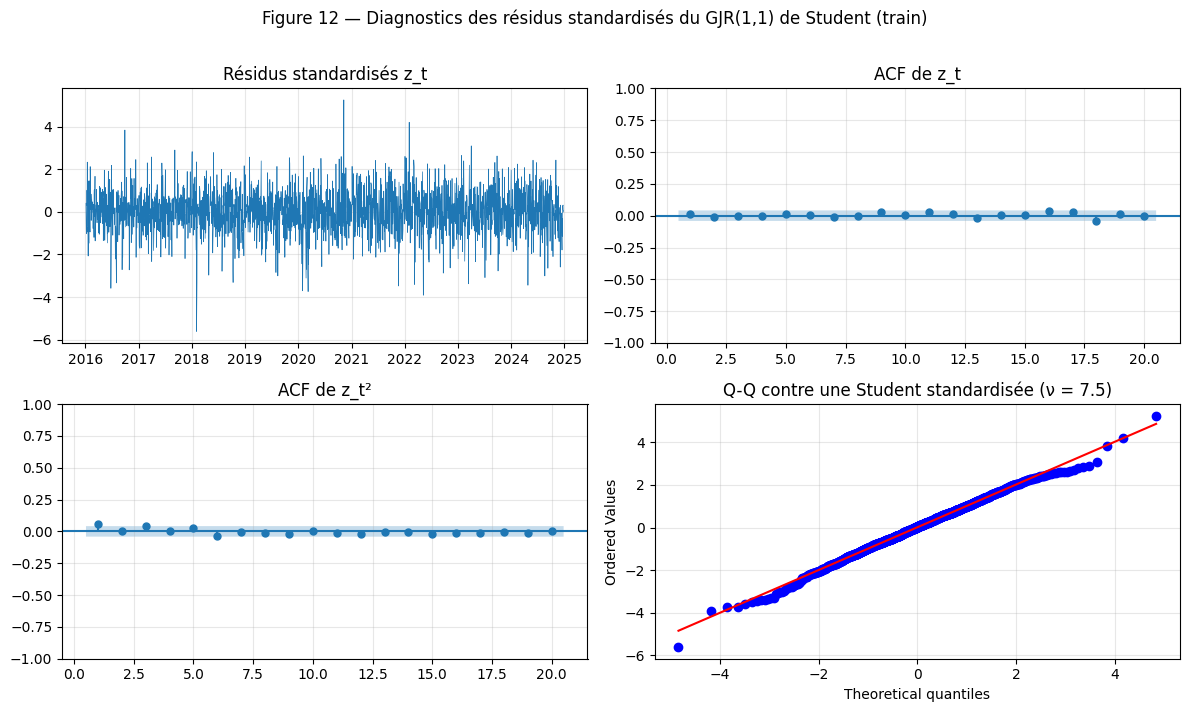

In [60]:
from statsmodels.graphics.tsaplots import plot_acf
from scipy import stats

z = pd.Series(gjr.std_resid.to_numpy(), index=dates_r)
nu = float(gjr.params["nu"])
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
axes[0, 0].plot(z.index, z, lw=0.5, color="tab:blue")
axes[0, 0].set_title("Résidus standardisés z_t")
plot_acf(z, lags=20, zero=False, ax=axes[0, 1])
axes[0, 1].set_title("ACF de z_t")
plot_acf(z ** 2, lags=20, zero=False, ax=axes[1, 0])
axes[1, 0].set_title("ACF de z_t²")
# Q-Q contre la Student standardisée (variance 1) de ν degrés de liberté estimés.
stats.probplot(z, dist=stats.t(nu, scale=np.sqrt((nu - 2) / nu)), plot=axes[1, 1])
axes[1, 1].set_title(f"Q-Q contre une Student standardisée (ν = {nu:.1f})")
for ax in axes.ravel():
    ax.grid(alpha=0.3)
fig.suptitle("Figure 12 — Diagnostics des résidus standardisés du GJR(1,1) de Student (train)", y=1.01)
fig.tight_layout()
save_fig(fig, 12, "garch_diagnostics")
plt.show()

**Interprétation des diagnostics des résidus standardisés (figure 12).**

**1. Plus d'autocorrélation dans la moyenne.** Ljung-Box sur z_t ne rejette pour aucun modèle (p ≈ 0,97 à 10 retards, ≈ 0,75 à 20). L'ACF de z_t est dans la bande partout.

**2. L'essentiel de l'effet ARCH a disparu, mais pas tout.**
- **Résultat global.** L'ARCH-LM(5) passe de **441** sur les rendements à **14,0** sur les z_t du GJR : le modèle a absorbé environ 97 % de la statistique.
- **Un léger effet résiduel.** Il reste significatif au seuil de 5 % pour les modèles de Student d'ordre (1,1) : ARCH-LM(5) p = 0,016 et ARCH-LM(10) p = 0,036 pour le GJR ; Ljung-Box sur z² p = 0,046 à 10 retards, mais 0,33 à 20 retards. Sur la figure, seul le premier retard de l'ACF de z² dépasse légèrement la bande (≈ 0,06).
- **Deux modèles le suppriment** : le GARCH(1,2) de Student (ARCH-LM(5) p = 0,12) et, paradoxalement, le GARCH(1,1) **normal** (p = 0,12).
- **L'explication du paradoxe.** La vraisemblance de Student accorde moins de poids aux chocs extrêmes. Elle laisse donc σ_t réagir un peu moins après eux, et une trace de regroupement subsiste dans z². Le GARCH(1,2) ajoute une seconde composante β plus lente, qui capte ce reste. Mais ses deux β ne sont pas significatifs séparément (p = 0,42 et 0,07) et son BIC est plus mauvais de 6 points.

On juge cet effet résiduel **faible et acceptable** : il est de l'ordre de 3 % de l'effet initial et disparaît à 20 retards. On ne l'élimine pas au prix d'un modèle mal identifié.

**3. La loi de Student convient.**
- **Kolmogorov-Smirnov** ne rejette pas l'adéquation de z_t à la Student estimée (p = 0,46 pour le GJR).
- **Jarque-Bera rejette toujours la normalité.** Mais l'excès de kurtosis des z_t n'est plus que de **1,5**, contre 6,6 pour les rendements bruts : le GARCH explique plus des trois quarts (78 %) de l'excès de kurtosis, et la loi de Student le reste.
- **Le graphe Q-Q** contre la Student standardisée (ν = 7,5) suit la droite sur presque tout le domaine. Seul le point le plus bas s'en écarte (z ≈ −5,6, début février 2018) : une baisse forte survenue alors que la volatilité conditionnelle n'était que de 15 % par an, donc particulièrement « surprenante » pour le modèle.

**Bilan.** Le GJR(1,1) de Student remplit les conditions essentielles : moyenne blanchie, effet ARCH réduit de 97 %, loi des innovations validée. C'est le premier modèle du projet dont les résidus sont **approximativement i.i.d.**

#### 3.3.4 Volatilité conditionnelle estimée et événements

On trace la volatilité conditionnelle annualisée, σ_t × √252, du GJR(1,1) de Student, et on la compare à la volatilité réalisée sur 21 jours du §1.5. Les deux mesures diffèrent par nature :
- la **volatilité conditionnelle** est une **prévision faite la veille**, à partir du passé seulement ;
- la **volatilité réalisée** est une **mesure a posteriori** sur les 21 derniers jours.

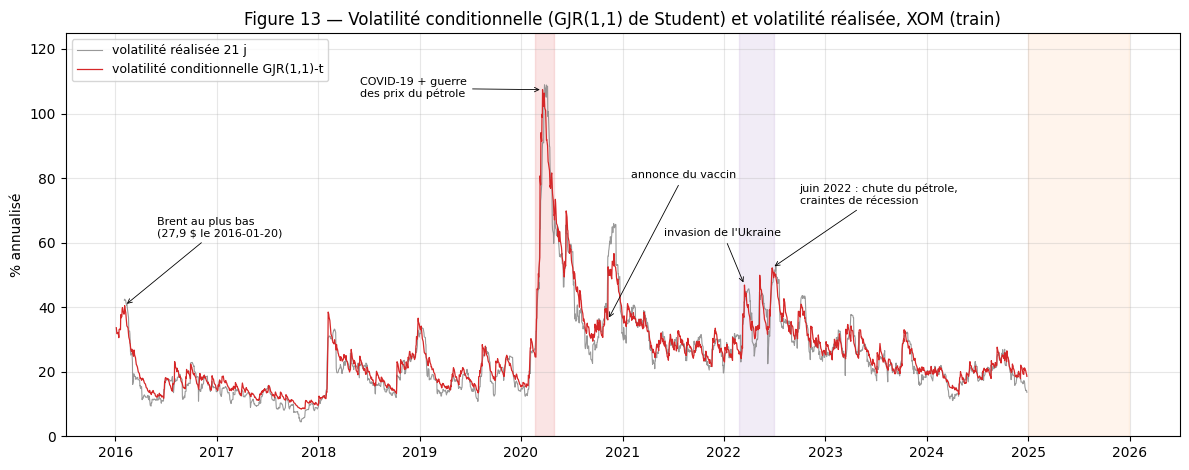

début 2016                     pic de volatilité conditionnelle :  40.5 % le 2016-02-04
mars-avril 2020                pic de volatilité conditionnelle : 107.4 % le 2020-03-19
février-mars 2022 (invasion)   pic de volatilité conditionnelle :  46.9 % le 2022-03-16
2022 entier                    pic de volatilité conditionnelle :  52.2 % le 2022-06-24
Médiane sur le train : 23.0 % ; minimum : 8.4 % le 2017-11-01
Corrélation volatilité conditionnelle / réalisée : 0.972


In [61]:
vol_c = pd.Series(gjr.conditional_volatility.to_numpy() * np.sqrt(252), index=dates_r)
vol_r = TRAIN["XOM_vol21"]
fig, ax = plt.subplots(figsize=(12, 4.8))
ax.plot(vol_r.index, vol_r, lw=0.8, color="grey", alpha=0.8, label="volatilité réalisée 21 j")
ax.plot(vol_c.index, vol_c, lw=0.9, color="tab:red", label="volatilité conditionnelle GJR(1,1)-t")
shade(ax)
# (date du point annoté, texte, position du texte) : positions fixées à la main pour éviter les chevauchements.
events = [("2016-02-04", "Brent au plus bas\n(27,9 $ le 2016-01-20)", ("2016-06-01", 62)),
          ("2020-03-19", "COVID-19 + guerre\ndes prix du pétrole", ("2018-06-01", 105)),
          ("2020-11-09", "annonce du vaccin", ("2021-02-01", 80)),
          ("2022-03-16", "invasion de l'Ukraine", ("2021-06-01", 62)),
          ("2022-06-24", "juin 2022 : chute du pétrole,\ncraintes de récession", ("2022-10-01", 72))]
for d, txt, (tx, ty) in events:
    d = pd.Timestamp(d)
    ax.annotate(txt, xy=(d, vol_c.loc[d]), xytext=(pd.Timestamp(tx), ty), fontsize=8,
                arrowprops=dict(arrowstyle="->", lw=0.6))
ax.set_ylim(0, 125)
ax.set_ylabel("% annualisé")
ax.set_title("Figure 13 — Volatilité conditionnelle (GJR(1,1) de Student) et volatilité réalisée, XOM (train)")
ax.legend(loc="upper left", fontsize=9)
ax.grid(alpha=0.3)
fig.tight_layout()
save_fig(fig, 13, "volatilite_conditionnelle")
plt.show()

peaks = {name: (vol_c.loc[a:b].max(), vol_c.loc[a:b].idxmax().date()) for name, (a, b) in
         {"début 2016": ("2016-01", "2016-03"), "mars-avril 2020": ("2020-03", "2020-04"),
          "février-mars 2022 (invasion)": ("2022-02-24", "2022-03-31"), "2022 entier": ("2022-01", "2022-12")}.items()}
for k, (v, d) in peaks.items():
    print(f"{k:<30} pic de volatilité conditionnelle : {v:5.1f} % le {d}")
print(f"Médiane sur le train : {vol_c.median():.1f} % ; minimum : {vol_c.min():.1f} % le {vol_c.idxmin().date()}")
print(f"Corrélation volatilité conditionnelle / réalisée : {vol_c.corr(vol_r):.3f}")

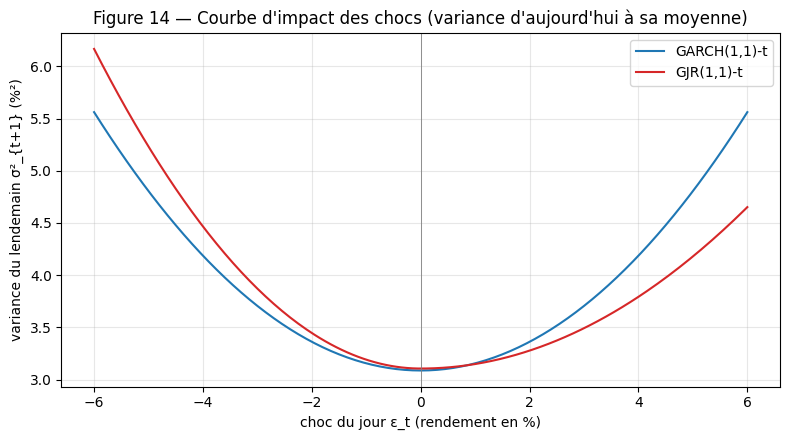

GJR : choc de −3 % → variance du lendemain 3.87 ; choc de +3 % → 3.49 (réaction aux baisses : α + γ = 0.0851 ; aux hausses : α = 0.0430)


In [62]:
# Courbe d'impact des chocs (news impact curve) : variance du lendemain selon le choc du jour.
fig, ax = plt.subplots(figsize=(8, 4.5))
for name, res, color in (("GARCH(1,1)-t", g11, "tab:blue"), ("GJR(1,1)-t", gjr, "tab:red")):
    ni = C.news_impact(res)
    ax.plot(ni.index, ni.values, color=color, label=name)
ax.axvline(0, color="grey", lw=0.6)
ax.set_xlabel("choc du jour ε_t (rendement en %)")
ax.set_ylabel("variance du lendemain σ²_{t+1} (%²)")
ax.set_title("Figure 14 — Courbe d'impact des chocs (variance d'aujourd'hui à sa moyenne)")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
save_fig(fig, 14, "courbe_impact_chocs")
plt.show()
ni = C.news_impact(gjr)
print(f"GJR : choc de −3 % → variance du lendemain {ni.loc[-3.0]:.2f} ; choc de +3 % → {ni.loc[3.0]:.2f} "
      f"(réaction aux baisses : α + γ = {gjr.params['alpha[1]'] + gjr.params['gamma[1]']:.4f} ; "
      f"aux hausses : α = {gjr.params['alpha[1]']:.4f})")

**Interprétation de la volatilité conditionnelle (figure 13) et de la courbe d'impact des chocs (figure 14).**

**Le modèle suit fidèlement la volatilité observée.** La corrélation avec la volatilité réalisée sur 21 jours est de **0,97**. La volatilité conditionnelle a une médiane de 23,0 % par an, avec un minimum de 8,4 % (2017-11-01, l'année la plus calme) et un maximum de **107,4 %** (2020-03-19).

**Lien avec les événements connus :**

| Épisode | Pic de volatilité conditionnelle | Contexte |
| --- | --- | --- |
| Début 2016 | 40,5 % le 2016-02-04 | Le pétrole touche son plus bas de la période : Brent à 27,9 $ le 2016-01-20 dans nos données. |
| Mars–avril 2020 | **107,4 %** le 2020-03-19 | Pandémie de COVID-19 et guerre des prix du pétrole (choc du 2020-03-09, `docs/sources.md`). |
| Novembre 2020 | rebond net | Annonce du vaccin le 2020-11-09. Le pic arrive **le lendemain** : σ_t se calcule avec l'information de la veille, donc la hausse de +11,9 % du 9 novembre ne se répercute que sur σ du 10. |
| Février–mars 2022 | 46,9 % le 2022-03-16 | Invasion de l'Ukraine (24 février 2022). |
| Juin 2022 | 52,2 % le 2022-06-24, pic de 2022 | Chute du pétrole et craintes de récession : le secteur de l'énergie du S&P 500 perd 16,8 % en juin 2022 ([S&P Global](https://www.spglobal.com/market-intelligence/en/news-insights/articles/2022/7/energy-stocks-plummet-in-june-as-recession-fears-drag-oil-prices-71046468)). |

Le pic de 2022 n'est donc **pas** celui de l'invasion, contrairement à ce que supposait le plan (« février–mars 2022 »). Il survient en juin, lors du retournement du marché pétrolier. On note aussi un bond début février 2018, provoqué par deux baisses consécutives de XOM (−5,2 % et −5,9 %) en période très calme.

**Une différence de nature entre les deux courbes.** La volatilité conditionnelle réagit **immédiatement** à un choc puis décroît lentement (β ≈ 0,93). La volatilité réalisée sur 21 jours monte et redescend en « créneau » : elle intègre le choc pendant exactement 21 jours, puis l'oublie d'un coup (fin 2020, par exemple). Le GARCH est une mesure **prospective** (prévue la veille), la volatilité réalisée une mesure **rétrospective**.

**Courbe d'impact des chocs (figure 14).** Elle montre la variance prévue pour demain en fonction du choc d'aujourd'hui.
- **GARCH(1,1) : courbe symétrique.** Une hausse et une baisse de même taille ont le même effet.
- **GJR(1,1) : courbe asymétrique.** Une **baisse** de 3 % porte la variance du lendemain à 3,87 %², contre 3,49 %² pour une **hausse** de 3 %. L'écart grandit avec la taille du choc : 6,2 contre 4,7 %² pour ±6 %.

C'est l'effet de levier : **les baisses accroissent davantage le risque que les hausses**.

**Rappel essentiel.** Ce modèle prévoit l'**amplitude** probable des variations de XOM, pas leur **sens**. La prévision du rendement reste nulle, puisque la moyenne retenue est la marche aléatoire. L'apport du GARCH se mesurera en section 6 sur la **qualité des intervalles de prévision** et sur la prévision de la variance, pas sur l'erreur de prévision du prix.

#### 3.3.5 Décision

| Élément | Choix | Justification |
| --- | --- | --- |
| Effets ARCH | **présents** (ARCH-LM(5) = 441) | ils justifient la modélisation de la variance |
| Loi des innovations | **Student** (ν ≈ 7,5) | +37,5 points de vraisemblance face à la normale ; KS p = 0,46 ; l'asymétrique n'apporte rien |
| Structure | **GJR(1,1)** | meilleur AIC et meilleur BIC ; effet de levier significatif (γ = 0,042, p = 0,004) ; les ordres supérieurs ne gagnent rien |
| Moyenne | **nulle** | μ non significatif (p = 0,27) ; cohérent avec la marche aléatoire du §3.1 |
| Résidus standardisés | **approximativement i.i.d.** | pas d'autocorrélation ; effet ARCH réduit de 97 % (léger reste à 5 %) ; loi de Student validée |

**Modèle retenu : marche aléatoire + GJR(1,1) à innovations de Student**, noté « ARIMA(0,1,0)-GJR-GARCH(1,1)-t ». Le GARCH(1,1) de Student, demandé par le plan, reste la référence de comparaison.

**Ce que ce modèle apporte et ce qu'il n'apporte pas.**
- **Il n'apporte rien à la prévision du prix.** La prévision ponctuelle est identique à celle de la marche aléatoire.
- **Il apporte des intervalles de prévision qui s'élargissent en période agitée et se resserrent en période calme**, au lieu d'une largeur fixe. Il fournit aussi une prévision de la variance elle-même.

**Limites à rapporter.**
1. **La persistance (≈ 0,999) est gonflée par la rupture de régime de 2020** (Lamoureux et Lastrapes, 1990). Les paramètres changent fortement entre 2016–2019 et 2021–2024 : un modèle unique sur 9 ans est une approximation. Une piste d'amélioration serait un GARCH à changement de régime, ou une ré-estimation glissante, testée en section 6.
2. **Un léger effet ARCH résiduel** subsiste au seuil de 5 %.
3. **Le modèle est univarié.** La volatilité de XLE et la corrélation dynamique XOM/XLE (DCC-GARCH) font partie des extensions de la section 7.

**Pour la section 6.** On évaluera :
- la **couverture** des intervalles à 95 % de l'ARIMA-GJR comparée à celle de l'ARIMA à variance constante ;
- la **prévision de la variance** face à r²_{t+1}, avec la perte QLIKE.

### 3.4 Export des résultats clés pour la comparaison avec R

Le cahier exige le socle classique (section 3) **en R et en Python** (§8.1). La version R se trouve dans `notebooks/classical_R.Rmd`. Pour comparer **exactement les mêmes grandeurs**, on exporte ici environ 80 valeurs clés de ce notebook dans `outputs/tables/tab29_reference_python.csv`. Le notebook R lit ce fichier et construit le tableau de comparaison Python/R.

On y ajoute deux calculs qui servent uniquement à la comparaison. En R, `urca::ca.jo` exige au moins 2 retards en niveaux (K = 2), c'est-à-dire **1 retard en différences**, alors que notre choix robuste en Python était 0 retard. On calcule donc aussi Johansen et le VECM avec 1 retard en différences, pour avoir un point de comparaison commun.

In [63]:
from statsmodels.tsa.vector_ar.vecm import coint_johansen

ref = {}
def put(key, value, desc):
    ref[key] = (float(value) if not isinstance(value, str) else value, desc)

# Données et découpage
put("n_jours", len(panel), "jours de bourse XOM/XLE")
put("n_train", len(train), "jours du train")
put("n_test", len(test), "jours du test")
put("debut_test", str(test.index[0].date()), "premier jour du test")

# Statistiques descriptives (train)
for tk in ["XOM", "XLE"]:
    d = desc[f"{tk}_ret"]
    for k, lab in [("moyenne", "moyenne"), ("écart-type", "ecart_type"), ("skewness", "skewness"),
                   ("excès de kurtosis", "exces_kurtosis"), ("Jarque-Bera", "jarque_bera")]:
        put(f"{tk}_{lab}", d[k], f"{k} des rendements {tk} (train)")

# Valeurs aberrantes (toute la période)
for tk in ["XOM", "XLE"]:
    put(f"{tk}_nb_outliers", out[tk]["outlier"].sum(), f"jours extrêmes {tk} (IQR 63 j, k = 3)")

# STL
for p in (5, 252):
    put(f"stl_FS_p{p}", strength.loc[("XOM", p), "force saisonnalité F_S"], f"force de saisonnalité STL, période {p} (XOM)")
    put(f"stl_FT_p{p}", strength.loc[("XOM", p), "force tendance F_T"], f"force de tendance STL, période {p} (XOM)")

# ADF / KPSS / Zivot-Andrews
for serie in ["XOM log-prix", "XOM rendement"]:
    for spec in ["constante", "constante + tendance"]:
        row = stationarity.loc[(serie, spec)]
        k = f"{serie.replace(' ', '_').replace('-', '')}_{'c' if spec == 'constante' else 'ct'}"
        put(f"adf_stat_{k}", row["ADF stat"], f"ADF {serie}, {spec}")
        put(f"adf_lags_{k}", row["ADF retards"], f"retards ADF (AIC) {serie}, {spec}")
        put(f"kpss_stat_{k}", row["KPSS stat"], f"KPSS {serie}, {spec}")
        put(f"kpss_lags_{k}", row["KPSS retards"], f"retards KPSS {serie}, {spec}")
for spec, k in [("rupture de niveau", "c"), ("rupture de niveau et de pente", "ct")]:
    row = za.loc[("XOM log-prix", spec)]
    put(f"za_stat_{k}", row["statistique"], f"Zivot-Andrews XOM log-prix, {spec}")
    put(f"za_lags_{k}", row["retards"], f"retards Zivot-Andrews, {spec}")
    put(f"za_date_{k}", str(row["date de rupture estimée"]), f"date de rupture Zivot-Andrews, {spec}")

# ARIMA
for name in ["ARIMA(0,1,0)", "ARIMA(1,1,0)", "ARIMA(0,1,1)", "ARIMA(1,1,1)", "ARIMA(0,1,0) + dérive"]:
    put(f"aic_{name}", tab_manual.loc[name, "AIC"], f"AIC {name}")
    put(f"llf_{name}", tab_manual.loc[name, "log-vraisemblance"], f"log-vraisemblance {name}")
put("aic_ARIMA(3,1,2)", fit312.aic, "AIC ARIMA(3,1,2)")
put("llf_ARIMA(3,1,2)", fit312.llf, "log-vraisemblance ARIMA(3,1,2)")
put("ar1_ARIMA(1,1,0)", manual["ARIMA(1,1,0)"].params["ar.L1"], "coefficient AR(1)")
put("derive_ARIMA(0,1,0)", manual["ARIMA(0,1,0) + dérive"].params["intercept"], "dérive (rendement moyen)")
for crit, m in auto.items():
    put(f"auto_arima_{crit}", f"ARIMA({m.order[0]},1,{m.order[2]})", f"choix d'auto_arima ({crit.upper()})")
dg = diag.loc["ARIMA(0,1,0)"]
put("rw_ljungbox_10", dg["Ljung-Box Q(10)"], "Ljung-Box Q(10), résidus ARIMA(0,1,0)")
put("rw_jarque_bera", dg["Jarque-Bera"], "Jarque-Bera, résidus ARIMA(0,1,0)")
put("rw_archlm_5", dg["ARCH-LM(5)"], "ARCH-LM(5), résidus ARIMA(0,1,0)")
put("sar5_coef", seasonal_fits["SARIMA(0,1,0)(1,0,0)[5]"].params["ar.S.L5"], "coefficient SAR(1) de période 5")
put("sar5_delta_aic", tab_sarima.loc["SARIMA(0,1,0)(1,0,0)[5]", "ΔAIC vs (0,1,0)"], "ΔAIC du SARIMA s = 5")

# VAR et Granger
for c in ["AIC", "BIC", "HQIC", "FPE"]:
    put(f"var_ordre_{c}", order_sel.loc["échantillon complet", c], f"ordre du VAR choisi par {c}")
for eq in ["XOM_ret", "XLE_ret"]:
    for reg in ["L1.XOM_ret", "L1.XLE_ret"]:
        put(f"var1_{eq}_{reg}", v1_full.params.loc[reg, eq], f"VAR(1), équation {eq}, coefficient {reg}")
put("var1_portmanteau_10", C.hosking_portmanteau(v1_full.resid.to_numpy(), 10, 1)["Q"], "Portmanteau ajusté (h = 10), VAR(1)")
g1 = granger.loc[("échantillon complet", 1)]
put("granger_p1_XLE_XOM_classique", g1.loc["XLE_ret → XOM_ret", "p classique"], "Granger XLE → XOM, 1 retard, F classique")
put("granger_p1_XLE_XOM_HC3", g1.loc["XLE_ret → XOM_ret", "p HC3"], "Granger XLE → XOM, 1 retard, HC3")
put("granger_p1_XOM_XLE_classique", g1.loc["XOM_ret → XLE_ret", "p classique"], "Granger XOM → XLE, 1 retard, F classique")

# Cointégration
put("eg_stat_XOM_sur_XLE", eg.loc[("XOM_logp sur XLE_logp", "constante"), "statistique"], "Engle-Granger, XOM sur XLE, constante")
joh_cmp = C.johansen_table(L_pair, {"k=1": 1, "k=6": 6, "k=8": 8})
for k in ["k=1", "k=6", "k=8"]:
    put(f"johansen_trace_{k}", joh_cmp.loc[(k, "r = 0"), "trace"], f"Johansen trace (r = 0), {k} retard(s) en différences")
    put(f"johansen_lmax_{k}", joh_cmp.loc[(k, "r = 0"), "λmax"], f"Johansen λmax (r = 0), {k}")
vecm1 = C.fit_vecm(L_pair, k_ar_diff=1, rank=1)
s1 = C.vecm_summary(vecm1, ["XOM", "XLE"])["valeur"]
put("vecm_k1_beta_XLE", s1["β (XLE)"], "VECM (k = 1) : β de XLE (β de XOM normalisé à 1)")
put("vecm_k1_const", s1["constante de la relation"], "VECM (k = 1) : constante de la relation")
put("vecm_k1_alpha_XOM", s1["α (XOM)"], "VECM (k = 1) : α de XOM")
put("vecm_k1_alpha_XLE", s1["α (XLE)"], "VECM (k = 1) : α de XLE")
put("vecm_k1_demi_vie", s1["demi-vie de l'écart (jours de bourse)"], "VECM (k = 1) : demi-vie de l'écart")
put("vecm_k0_demi_vie", vecm_tab.loc["demi-vie de l'écart (jours de bourse)", "valeur"], "VECM (k = 0) : demi-vie (modèle retenu en Python)")

# IRF et FEVD (ordre de Cholesky XLE → XOM)
ft = fevd_tab[(fevd_tab["ordre de Cholesky"] == "XLE_ret → XOM_ret") & (fevd_tab["variable prévue"] == "XOM_ret")]
it = irf_tab[(irf_tab["ordre de Cholesky"] == "XLE_ret → XOM_ret") & (irf_tab["choc"] == "XLE_ret") & (irf_tab["réponse de"] == "XOM_ret")]
put("irf_xom_choc_xle_h0", it.loc[it["h"] == 0, "réponse (%)"].iloc[0], "IRF : réponse de XOM à un choc XLE, jour 0 (ordre XLE → XOM)")
put("irf_xom_choc_xle_h1", it.loc[it["h"] == 1, "réponse (%)"].iloc[0], "IRF : réponse de XOM à un choc XLE, jour 1")
put("fevd_xom_part_xle_h10", ft.loc[ft["horizon h"] == 10, "part due au choc XLE_ret"].iloc[0], "FEVD : part du choc XLE dans la variance de prévision de XOM, h = 10")

# GARCH
gn = diag_fits["GARCH(1,1) — normale"]
for name, res in {"garch11_n": gn, "garch11_t": g11, "gjr11_t": gjr}.items():
    put(f"{name}_llf", res.loglikelihood, f"log-vraisemblance {name}")
    for p, v in res.params.items():
        put(f"{name}_{p}", v, f"{name} : {p}")
    put(f"{name}_persistance", C.persistence(res), f"persistance {name}")
gd = garch_diag.loc["GJR(1,1) — Student"]
put("gjr11_t_archlm5_z", gd["ARCH-LM(5)"], "ARCH-LM(5) sur les résidus standardisés du GJR-t")
put("gjr11_t_ks_p", gd["p KS (Student ν)"], "p-value KS, résidus standardisés du GJR-t contre la Student")

reference = pd.DataFrame([(k, v[0], v[1]) for k, v in ref.items()], columns=["clé", "valeur_python", "description"])
save_table(reference, "tab29_reference_python", index=False)
print(f"{len(reference)} valeurs exportées dans outputs/tables/tab29_reference_python.csv")
reference.head(10)

111 valeurs exportées dans outputs/tables/tab29_reference_python.csv


C:\Users\Aziz\AppData\Local\Temp\ipykernel_14716\2880401495.py:68: PerformanceWarning: indexing past lexsort depth may impact performance.
  g1 = granger.loc[("échantillon complet", 1)]


,clé,valeur_python,description
0,n_jours,2514.0000,jours de bourse XOM/XLE
1,n_train,2262.0000,jours du train
2,n_test,252.0000,jours du test
3,debut_test,2024-12-30,premier jour du test
4,XOM_moyenne,0.0319,moyenne des rendements XOM (train)
5,XOM_ecart_type,1.7845,écart-type des rendements XOM (train)
6,XOM_skewness,-0.1630,skewness des rendements XOM (train)
7,XOM_exces_kurtosis,6.6224,excès de kurtosis des rendements XOM (train)
8,XOM_jarque_bera,4141.6970,Jarque-Bera des rendements XOM (train)
9,XLE_moyenne,0.0315,moyenne des rendements XLE (train)


## 4. Modélisation avancée : réseaux récurrents (Python uniquement)

Cette section est implémentée **en Python uniquement** (`src/deep.py`, Keras/TensorFlow), comme le permet le cahier (§8.1).

**Mise en forme des données.**

| Élément | Choix | Raison |
| --- | --- | --- |
| Cible | les **10 log-rendements futurs** de XOM, prévus d'un coup (sortie directe de 10 valeurs) | Un réseau entraîné sur des **prix** extrapole mal hors de la plage vue à l'apprentissage. Les rendements sont stationnaires (§2.6), et le prix se reconstruit ensuite : P_{t+h} = P_t × exp(Σ r̂ / 100). |
| Entrées | fenêtres glissantes de 3 variables : rendement de XOM, rendement de XLE, volatilité réalisée sur 21 jours de XOM | La volatilité porte la seule structure prévisible des données (§3.3). XLE apporte l'information sectorielle. |
| Brent | non utilisé | 2 jours manquants qu'il faudrait imputer (§1.4) et sauts au changement de contrat. Le Brent est réservé aux extensions (§7). |
| Normalisation | moyenne et écart-type calculés **sur la partie d'apprentissage de chaque fold** | aucune information de la période évaluée n'entre dans la normalisation |

**Validation : walk-forward.** On utilise `TimeSeriesSplit` à 5 folds en fenêtre **croissante** sur le train : à chaque fold, le réseau apprend sur le passé et il est évalué sur la période suivante, comme en conditions réelles. Le k-fold classique est **exclu**, car il ferait apprendre sur le futur pour prévoir le passé. Un **écart de 10 jours** sépare apprentissage et évaluation : la cible d'une fenêtre d'apprentissage couvre les 10 jours suivants, qui ne doivent pas chevaucher la période évaluée. La même précaution s'applique entre apprentissage et validation interne (early stopping).

**Références.** Chaque fold est aussi évalué avec deux prévisions naïves, sur exactement les mêmes échantillons :
- **zéro** : la marche aléatoire, modèle retenu en §3.1 ;
- **moyenne** : le rendement moyen de l'apprentissage.

Un réseau n'a d'intérêt que s'il bat la marche aléatoire.

In [64]:
from src import deep as D

dcfg = cfg["deep"]
for w in dcfg["windows"]:
    Xw, Yw, ow = D.make_windows(TRAIN, w)
    full = ~np.isnan(Yw).any(axis=1)
    print(f"Fenêtre {w} : X {Xw.shape}, {full.sum()} échantillons à horizon complet, origines {ow[0].date()} → {ow[full][-1].date()}")

# Périodes des 5 folds (fenêtre de 20 jours) : apprentissage croissant, évaluation sur la période suivante.
Xw, Yw, ow = D.make_windows(TRAIN, 20)
ow = ow[~np.isnan(Yw).any(axis=1)]
pd.DataFrame([{"fold": i, "apprentissage": f"{ow[tr[0]].date()} → {ow[tr[-1]].date()} ({len(tr)})",
               "évaluation": f"{ow[te[0]].date()} → {ow[te[-1]].date()} ({len(te)})"}
              for i, (tr, te) in enumerate(D.walk_forward_splits(len(ow), dcfg["n_splits"]), start=1)]).set_index("fold")

Fenêtre 20 : X (2222, 20, 3), 2212 échantillons à horizon complet, origines 2016-03-02 → 2024-12-12
Fenêtre 60 : X (2182, 60, 3), 2172 échantillons à horizon complet, origines 2016-04-28 → 2024-12-12


,apprentissage,évaluation
fold,,
1,2016-03-02 → 2017-08-07 (362),2017-08-22 → 2019-02-07 (368)
2,2016-03-02 → 2019-01-24 (730),2019-02-08 → 2020-07-24 (368)
3,2016-03-02 → 2020-07-10 (1098),2020-07-27 → 2022-01-07 (368)
4,2016-03-02 → 2021-12-23 (1466),2022-01-10 → 2023-06-28 (368)
5,2016-03-02 → 2023-06-13 (1834),2023-06-29 → 2024-12-12 (368)


### 4.1 Choix des hyperparamètres par walk-forward

**Grille réduite** : 2 fenêtres × 2 tailles × 2 dropouts = 8 configurations par architecture (LSTM et GRU), chacune évaluée sur les 5 folds, soit 80 entraînements. Le choix se fait **uniquement sur les folds du train**, jamais sur le test.

| Hyperparamètre | Valeurs | Justification |
| --- | --- | --- |
| Fenêtre | 20 et 60 jours | Un mois et un trimestre de bourse. La volatilité est persistante (§3.3), et une fenêtre plus longue pourrait mieux la capter. |
| Unités récurrentes | 32 et 64 | Capacité modeste : ~2 000 échantillons et un signal faible font du sur-apprentissage le risque principal. |
| Dropout | 0,2 et 0,4 | Régularisation, pour la même raison. |
| Couches récurrentes | 1 | Une seconde couche multiplie les paramètres sans signal à exploiter (rendements ≈ bruit blanc, §2.3). |
| Optimiseur | Adam, taux d'apprentissage 10⁻³, lots de 64 | Réglages standard. Le taux d'apprentissage n'est pas dans la grille, pour la garder réduite. |
| Arrêt précoce | patience 10, maximum 100 époques, poids de la meilleure époque | La validation est faite sur les derniers 10 % de l'apprentissage, dans l'ordre chronologique. |
| Seed | 42 pendant la recherche | 3 seeds (42, 43, 44) pour le modèle final (§4.2), afin de mesurer la sensibilité à l'initialisation. |

**Critère de choix** : le **gain moyen de RMSE par rapport à la marche aléatoire**, calculé sur exactement les mêmes échantillons. Le RMSE brut ne permet pas de comparer les deux fenêtres : avec 60 jours, les premières origines commencent plus tard, si bien que les jours évalués diffèrent légèrement.

In [65]:
import time

grid = [{"window": w, "units": u, "dropout": d} for w in dcfg["windows"] for u in dcfg["units"] for d in dcfg["dropouts"]]
t0 = time.time()
grid_tab, grid_details = D.grid_search(["LSTM", "GRU"], grid, TRAIN, seed=42, val_ratio=dcfg["validation_ratio"],
                                       patience=dcfg["early_stopping_patience"], n_splits=dcfg["n_splits"])
print(f"Recherche terminée en {(time.time() - t0) / 60:.1f} min ({len(grid) * 2 * dcfg['n_splits']} entraînements)")
save_table(grid_tab, "tab31_deep_grille", index=False)
grid_tab.sort_values("gain moyen vs zéro (%)", ascending=False).round(4)

Recherche terminée en 9.9 min (80 entraînements)


,modèle,fenêtre,unités,dropout,RMSE moyen,écart-type,RMSE zéro moyen,gain moyen vs zéro (%),folds battant le zéro,époques moyennes,durée (s)
2,LSTM,20,64,0.2000,1.8472,0.5656,1.8450,-0.1372,2,13.8000,37.2968
3,LSTM,20,64,0.4000,1.8474,0.5651,1.8450,-0.1516,1,14.0000,24.6071
9,GRU,20,32,0.4000,1.8482,0.5678,1.8450,-0.1531,1,22.6000,31.8699
14,GRU,60,64,0.2000,1.8605,0.5787,1.8570,-0.1883,1,14.0000,38.2444
1,LSTM,20,32,0.4000,1.8477,0.5632,1.8450,-0.1974,1,14.6000,48.2290
0,LSTM,20,32,0.2000,1.8478,0.5634,1.8450,-0.2040,1,14.6000,30.4101
8,GRU,20,32,0.2000,1.8490,0.5674,1.8450,-0.2111,1,18.8000,29.0211
10,GRU,20,64,0.2000,1.8486,0.5644,1.8450,-0.2454,2,12.8000,25.3694
7,LSTM,60,64,0.4000,1.8621,0.5809,1.8570,-0.2556,2,17.4000,39.4588
6,LSTM,60,64,0.2000,1.8618,0.5792,1.8570,-0.2592,2,15.2000,35.8077


In [66]:
# Critère : gain moyen par rapport à la marche aléatoire SUR LES MÊMES ÉCHANTILLONS. Le RMSE brut ne
# convient pas entre fenêtres : une fenêtre de 60 jours commence plus tard et n'évalue pas les mêmes jours.
best = {kind: grid_tab[grid_tab["modèle"] == kind].sort_values("gain moyen vs zéro (%)", ascending=False).iloc[0]
        for kind in ["LSTM", "GRU"]}
best_cfg = {kind: {"window": int(b["fenêtre"]), "units": int(b["unités"]), "dropout": float(b["dropout"])}
            for kind, b in best.items()}
folds_best = pd.concat({kind: grid_details[(kind, c["window"], c["units"], c["dropout"])] for kind, c in best_cfg.items()})
save_table(folds_best, "tab32_deep_folds_meilleures_configs")
print("Configurations retenues :", best_cfg)
folds_best.drop(columns=["durée (s)"]).round(4)

Configurations retenues : {'LSTM': {'window': 20, 'units': 64, 'dropout': 0.2}, 'GRU': {'window': 20, 'units': 32, 'dropout': 0.4}}


apprentissage               évaluation  n apprentissage  n évaluation  époques  RMSE réseau  RMSE zéro (marche aléatoire)  RMSE moyenne  \
     fold                                                                                                                                                      
LSTM 1     2016-03-02 → 2017-08-07  2017-08-22 → 2019-02-07              362           368       11       1.2362                        1.2297        1.2297   
     2     2016-03-02 → 2019-01-24  2019-02-08 → 2020-07-24              730           368       21       2.5476                        2.5392        2.5391   
     3     2016-03-02 → 2020-07-10  2020-07-27 → 2022-01-07             1098           368       12       2.1032                        2.1074        2.1111   
     4     2016-03-02 → 2021-12-23  2022-01-10 → 2023-06-28             1466           368       14       2.0554                        2.0564        2.0563   
     5     2016-03-02 → 2023-06-13  2023-06-29 → 2024-12-12             1834           368       11       1.2934                        1.2925        1.2925   
GRU  1     2016-03-02 → 2017-08-07  2017-08-22 → 2019-02-07              362           368       26       1.2315                        1.2297        1.2297   
     2     2016-03-02 → 2019-01-24  2019-02-08 → 2020-07-24              730           368       25       2.5481                        2.5392        2.5391   
     3     2016-03-02 → 2020-07-10  2020-07-27 → 2022-01-07             1098           368       19       2.1069                        2.1074        2.1111   
     4     2016-03-02 → 2021-12-23  2022-01-10 → 2023-06-28             1466           368       14       2.0607                        2.0564        2.0563   
     5     2016-03-02 → 2023-06-13  2023-06-29 → 2024-12-12             1834           368       29       1.2937                        1.2925        1.2925   

           gain vs zéro (%)  
     fold                    
LSTM 1              -0.5297  
     2              -0.3317  
     3               0.1978  
     4               0.0473  
     5              -0.0695  
GRU  1              -0.1413  
     2              -0.3505  
     3               0.0251  
     4              -0.2078  
     5              -0.0907

**Interprétation de la recherche d'hyperparamètres** (80 entraînements, 5 folds par configuration).

1. **Aucune configuration ne bat la marche aléatoire en moyenne.** Le gain moyen est négatif pour les 16 configurations : de −0,14 % pour la meilleure (LSTM, fenêtre 20, 64 unités, dropout 0,2) à −0,43 % pour la moins bonne (LSTM, fenêtre 60, 32 unités, dropout 0,2). Aucune ne bat le « zéro » sur plus de 2 folds sur 5. Prévoir un rendement nul reste la meilleure option.

2. **Les écarts entre configurations sont du bruit.** Ils tiennent en quelques dixièmes de point de gain, alors que le RMSE varie d'un fold à l'autre de 1,23 % à 2,54 % (écart-type d'environ 0,56). Le choix de la « meilleure » configuration est donc en grande partie arbitraire. On le retient pour sa règle explicite (meilleur gain moyen), pas parce qu'il serait réellement supérieur.

3. **Seule régularité : la fenêtre de 20 jours fait toujours mieux que celle de 60.** Les 8 configurations à fenêtre 20 ont un gain compris entre −0,14 et −0,28 %, celles à fenêtre 60 entre −0,19 et −0,43 %. Une fenêtre plus longue donne simplement plus d'entrées sans signal, donc plus de bruit à ajuster.

4. **L'arrêt précoce intervient tôt.** Il se produit en moyenne entre 13 et 23 époques, souvent quelques époques seulement après la meilleure. Le réseau cesse vite de progresser sur la validation.

5. **Ce sont les régimes de volatilité qui expliquent les erreurs, pas les modèles.** Le fold 2, qui contient le krach de 2020, a un RMSE deux fois plus élevé (≈ 2,54 %) que le fold 1 (≈ 1,23 %), et ce pour **tous** les modèles. Pour la meilleure configuration LSTM, le gain par fold vaut −0,53 ; −0,33 ; +0,20 ; +0,05 ; −0,07 % : le réseau ne fait pas mieux en période de crise qu'en période calme.

**Configurations retenues** pour la suite : **LSTM** (fenêtre 20, 64 unités, dropout 0,2) et **GRU** (fenêtre 20, 32 unités, dropout 0,4).

### 4.2 Modèles finaux : 3 seeds et courbes de perte

Chaque configuration retenue est ré-entraînée sur **tout le train**, avec 3 seeds différentes. L'apprentissage n'utilise que les origines dont les 10 jours cibles sont dans le train : aucun rendement du test n'entre dans une cible. L'arrêt précoce s'appuie sur les derniers 10 % du train.

Les prévisions sont ensuite calculées depuis chaque jour du test, en n'utilisant que les données connues à cette date. Elles seront **évaluées en section 6** avec les autres modèles. Ici, on regarde seulement la stabilité de l'entraînement.

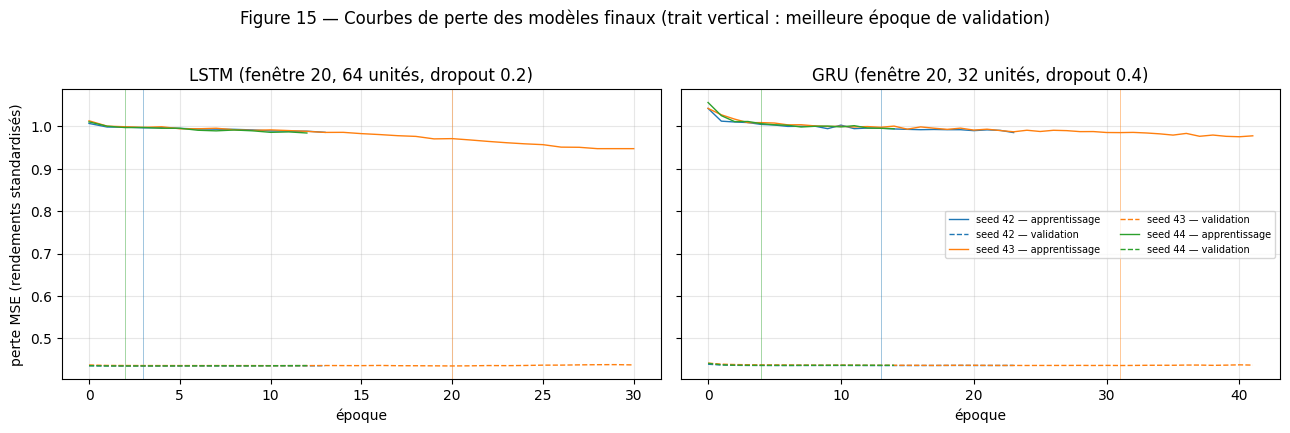

LSTM : écart-type entre seeds des prévisions (moyenne sur les origines et horizons) = 0.0440 % ; 2212 échantillons d'apprentissage
GRU : écart-type entre seeds des prévisions (moyenne sur les origines et horizons) = 0.0350 % ; 2212 échantillons d'apprentissage
Pour comparaison, écart-type des rendements journaliers du train : 1.785 %


époques  meilleure époque  perte de validation min  perte de validation à l'époque 1  écart-type des prévisions h = 1 (%)
modèle seed                                                                                                                           
LSTM   42         14                 4                   0.4343                            0.4348                               0.0516
       43         31                21                   0.4345                            0.4368                               0.1869
       44         13                 3                   0.4347                            0.4353                               0.0587
GRU    42         24                14                   0.4354                            0.4386                               0.0544
       43         42                32                   0.4355                            0.4413                               0.1054
       44         15                 5                   0.4359                            0.4407                               0.0413

In [67]:
train_end = TRAIN.index[-1]
finals = {kind: D.final_models(kind, best_cfg[kind], panel, train_end, dcfg["seeds"], dcfg["validation_ratio"],
                               dcfg["early_stopping_patience"]) for kind in ["LSTM", "GRU"]}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, (kind, res) in zip(axes, finals.items()):
    for s, color in zip(dcfg["seeds"], ["tab:blue", "tab:orange", "tab:green"]):
        h = res["histories"][s]
        ax.plot(h["loss"], color=color, lw=1, label=f"seed {s} — apprentissage")
        ax.plot(h["val_loss"], color=color, lw=1, ls="--", label=f"seed {s} — validation")
        ax.axvline(int(np.argmin(h["val_loss"])), color=color, lw=0.6, alpha=0.5)
    c = best_cfg[kind]
    ax.set_title(f"{kind} (fenêtre {c['window']}, {c['units']} unités, dropout {c['dropout']})")
    ax.set_xlabel("époque")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("perte MSE (rendements standardisés)")
axes[1].legend(fontsize=7, ncol=2)
fig.suptitle("Figure 15 — Courbes de perte des modèles finaux (trait vertical : meilleure époque de validation)", y=1.02)
fig.tight_layout()
save_fig(fig, 15, "courbes_perte")
plt.show()

seed_tab = pd.DataFrame([{"modèle": kind, "seed": s, "époques": res["epochs"][s],
                          "meilleure époque": int(np.argmin(res["histories"][s]["val_loss"])) + 1,
                          "perte de validation min": min(res["histories"][s]["val_loss"]),
                          "perte de validation à l'époque 1": res["histories"][s]["val_loss"][0],
                          "écart-type des prévisions h = 1 (%)": res["forecasts"][s][:, 0].std()}
                         for kind, res in finals.items() for s in dcfg["seeds"]]).set_index(["modèle", "seed"])
for kind, res in finals.items():
    stack = np.stack([res["forecasts"][s] for s in dcfg["seeds"]])
    print(f"{kind} : écart-type entre seeds des prévisions (moyenne sur les origines et horizons) = {stack.std(axis=0).mean():.4f} % ; "
          f"{res['n_fit']} échantillons d'apprentissage")
print(f"Pour comparaison, écart-type des rendements journaliers du train : {TRAIN['XOM_ret'].std():.3f} %")
save_table(seed_tab, "tab33_deep_seeds")
seed_tab.round(4)

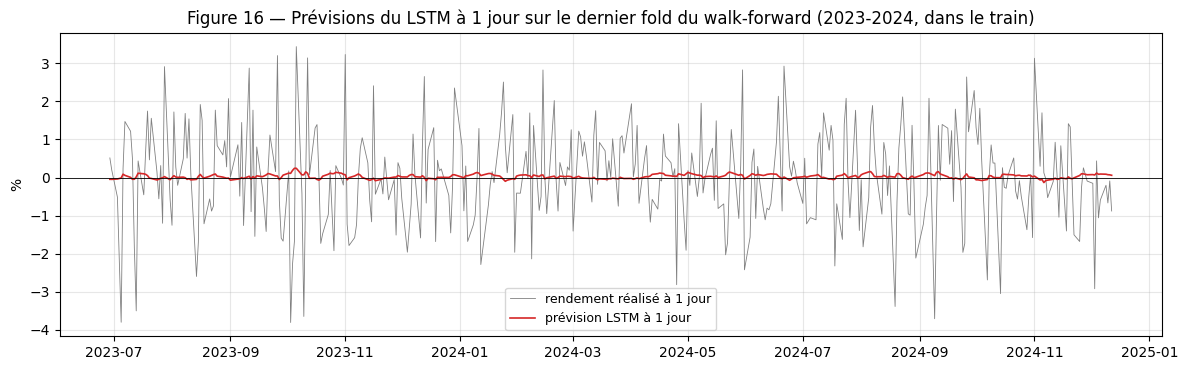

Écart-type des rendements réalisés : 1.297 % ; des prévisions : 0.058 % ; corrélation prévision/réalisé : 0.016


In [68]:
# Que prévoit réellement le réseau ? Prévisions à 1 jour sur le dernier fold du walk-forward (dans le train).
c = best_cfg["LSTM"]
Xw, Yw, ow = D.make_windows(TRAIN, c["window"])
m = ~np.isnan(Yw).any(axis=1)
Xw, Yw, ow = Xw[m], Yw[m], ow[m]
tr, te = D.walk_forward_splits(len(Xw), dcfg["n_splits"])[-1]
model5, sc5, _, _ = D.train("LSTM", c, Xw[tr], Yw[tr], 42, dcfg["validation_ratio"], dcfg["early_stopping_patience"])
pred5 = D.predict(model5, sc5, Xw[te])
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(ow[te], Yw[te][:, 0], lw=0.6, color="grey", label="rendement réalisé à 1 jour")
ax.plot(ow[te], pred5[:, 0], lw=1.2, color="tab:red", label="prévision LSTM à 1 jour")
ax.axhline(0, color="black", lw=0.6)
ax.set_ylabel("%")
ax.set_title("Figure 16 — Prévisions du LSTM à 1 jour sur le dernier fold du walk-forward (2023-2024, dans le train)")
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
fig.tight_layout()
save_fig(fig, 16, "lstm_previsions_fold5")
plt.show()
print(f"Écart-type des rendements réalisés : {Yw[te][:, 0].std():.3f} % ; des prévisions : {pred5[:, 0].std():.3f} % ; "
      f"corrélation prévision/réalisé : {np.corrcoef(pred5[:, 0], Yw[te][:, 0])[0, 1]:.3f}")

**Interprétation des modèles finaux (figure 15, tableau des seeds, figure 16).**

**1. Le réseau n'apprend rien de généralisable.**
- **La perte de validation est plate dès la première époque.** Pour le LSTM de seed 42, elle passe de 0,4348 à l'époque 1 à 0,4343 au minimum, soit 0,1 % de mieux. La meilleure époque arrive très tôt (3ᵉ ou 4ᵉ pour les seeds 42 et 44).
- **La perte d'apprentissage reste proche de 1.** Les rendements étant standardisés, une perte de 1 signifie que le modèle n'explique quasiment aucune part de la variance.

**2. Prolonger l'entraînement produit de la mémorisation.** Avec la seed 43, l'arrêt précoce intervient plus tard (meilleure époque : 21 pour le LSTM, 32 pour le GRU). La perte d'apprentissage descend alors vers 0,95 alors que la validation ne bouge pas : le réseau apprend le bruit du train. L'arrêt précoce, avec restauration des meilleurs poids, empêche que cela dégrade les prévisions.

**3. Pourquoi la validation (≈ 0,43) est plus basse que l'apprentissage (≈ 1).** Ce n'est pas un signe de qualité. La validation correspond aux derniers 10 % du train, c'est-à-dire surtout 2024, une période calme. Ses rendements, ramenés à l'écart-type de tout le train (crises comprises), ont donc une variance plus faible.

**4. Les prévisions sont quasi constantes.** Sur le dernier fold du walk-forward (figure 16) :

| | Écart-type |
| --- | --- |
| Rendements réalisés à 1 jour | 1,297 % |
| Prévisions du LSTM à 1 jour | 0,058 % |

La corrélation entre prévision et réalisation est de **0,016**. Le réseau prévoit en pratique un rendement à peu près nul tous les jours : il a **redécouvert la marche aléatoire**, de façon plus coûteuse et légèrement bruitée.

**5. Sensibilité à la seed.** L'écart-type entre les prévisions des 3 seeds vaut 0,044 % pour le LSTM et 0,035 % pour le GRU. C'est le même ordre de grandeur que l'amplitude des prévisions elles-mêmes (0,04 à 0,19 %) : changer la seed modifie la prévision autant que le signal supposé. Pour la section 6, on utilise donc la **moyenne des 3 seeds**, ce qui réduit ce bruit d'initialisation.

### 4.3 Approche hybride ARIMA + LSTM

**Principe.** Un modèle linéaire capte la dynamique linéaire de la moyenne, puis un réseau apprend ce qui reste dans ses résidus, pour capter d'éventuelles non-linéarités :

  prévision = prévision ARIMA (partie linéaire) + prévision LSTM des résidus ARIMA (partie non linéaire)

**Choix de l'ARIMA.** Avec la marche aléatoire retenue en §3.1, la partie linéaire prévoit un rendement nul et les résidus sont les rendements eux-mêmes : l'hybride se confondrait avec le LSTM seul. On utilise donc l'**ARIMA(3,1,2)**, le choix d'`auto_arima` gardé comme concurrent en §3.1, qui a une partie linéaire non triviale.

**Protocole.**
- À chaque fold, l'ARIMA est **ré-estimé sur la seule période d'apprentissage du fold**. Ses prévisions sur la période évaluée utilisent ces paramètres figés et, à chaque origine, les seules données disponibles jusqu'à cette date.
- Le LSTM, avec la configuration retenue en 4.1, prend en entrée les résidus de l'ARIMA, le rendement de XLE et la volatilité.

In [69]:
hyb_cv = D.hybrid_walk_forward(TRAIN, best_cfg["LSTM"], 42, dcfg["validation_ratio"], dcfg["early_stopping_patience"],
                               n_splits=dcfg["n_splits"])
save_table(hyb_cv, "tab34_hybride_folds")
hyb_final = D.final_models("LSTM", best_cfg["LSTM"], panel, train_end, dcfg["seeds"], dcfg["validation_ratio"],
                           dcfg["early_stopping_patience"], hybrid=True)
print("Époques des modèles hybrides finaux :", hyb_final["epochs"])
hyb_cv.drop(columns=["durée (s)"]).round(4)

Époques des modèles hybrides finaux : {42: 14, 43: 31, 44: 13}


,évaluation,époques,RMSE hybride,"RMSE ARIMA(3,1,2) seul",RMSE zéro (marche aléatoire),gain hybride vs zéro (%)
fold,,,,,,
1,2017-08-22 → 2019-02-07,11,1.2419,1.2346,1.2297,-0.9892
2,2019-02-08 → 2020-07-24,22,2.5413,2.5322,2.5392,-0.0826
3,2020-07-27 → 2022-01-07,11,2.1082,2.1106,2.1074,-0.0365
4,2022-01-10 → 2023-06-28,14,2.0696,2.0707,2.0564,-0.6393
5,2023-06-29 → 2024-12-12,12,1.3028,1.3023,1.2925,-0.7947


**Interprétation de l'hybride ARIMA(3,1,2) + LSTM.**
- **L'hybride ne bat la marche aléatoire sur aucun fold** : son gain varie de −0,04 % à −0,99 %, pour un RMSE moyen de 1,8527 contre 1,8450.
- **Le réseau n'améliore pas non plus l'ARIMA seul.** L'hybride est moins bon que l'ARIMA(3,1,2) sur 3 folds sur 5 (folds 1, 2 et 5) et à peine meilleur sur les deux autres. Les résidus de l'ARIMA n'ont pas de structure non linéaire exploitable : le LSTM qui les modélise ne fait qu'ajouter du bruit.
- **L'ARIMA(3,1,2) seul** ne bat la marche aléatoire que sur le fold 2 (2,5322 contre 2,5392, soit −0,3 % d'erreur), le fold de la crise de 2020. Il fait moins bien sur les 4 autres. Ce résultat isolé ne suffit pas à le réhabiliter, et sa pertinence sera testée formellement en section 6.

**Pourquoi l'hybride échoue ici.** Son principe suppose qu'une partie de la dynamique est linéaire (captée par l'ARIMA) et qu'une autre est non linéaire (captée par le réseau). Or les sections 2 et 3 ont montré que la moyenne des rendements n'a **ni l'une ni l'autre** : sa seule structure prévisible est la **variance** (effets ARCH), que ni l'ARIMA ni le réseau de l'hybride ne ciblent.

### 4.4 Synthèse de la validation croisée et prévisions transmises à la section 6

In [70]:
fb = folds_best
summary = pd.DataFrame({
    "marche aléatoire (zéro)": fb.loc["LSTM", "RMSE zéro (marche aléatoire)"],
    "moyenne d'apprentissage": fb.loc["LSTM", "RMSE moyenne"],
    f"LSTM {tuple(best_cfg['LSTM'].values())}": fb.loc["LSTM", "RMSE réseau"],
    f"GRU {tuple(best_cfg['GRU'].values())}": fb.loc["GRU", "RMSE réseau"],
    "ARIMA(3,1,2)": hyb_cv["RMSE ARIMA(3,1,2) seul"].to_numpy(),
    "hybride ARIMA(3,1,2) + LSTM": hyb_cv["RMSE hybride"].to_numpy(),
})
summary.loc["moyenne"] = summary.mean()
summary.loc["folds battant le zéro"] = (summary.iloc[:5].lt(summary.iloc[:5, 0], axis=0)).sum()
save_table(summary, "tab35_deep_synthese_cv")

# Prévisions des modèles finaux (moyenne des 3 seeds) depuis chaque origine du test, pour la section 6.
rows = []
for name, res in {"LSTM": finals["LSTM"], "GRU": finals["GRU"], "Hybride ARIMA+LSTM": hyb_final}.items():
    ens = np.mean([res["forecasts"][s] for s in dcfg["seeds"]], axis=0)
    for i, o in enumerate(res["origins"]):
        for h in range(D.HORIZON):
            rows.append({"origine": o, "h": h + 1, "modèle": name, "rendement prévu (%)": ens[i, h]})
deep_forecasts = pd.DataFrame(rows)
deep_forecasts.to_csv(ROOT / "data/processed/deep_test_forecasts.csv", index=False, lineterminator="\n")
print(f"{len(deep_forecasts)} prévisions sauvegardées ({deep_forecasts['origine'].nunique()} origines × 10 horizons × 3 modèles)")
summary.round(4)

7560 prévisions sauvegardées (252 origines × 10 horizons × 3 modèles)


,marche aléatoire (zéro),moyenne d'apprentissage,"LSTM (20, 64, 0.2)","GRU (20, 32, 0.4)","ARIMA(3,1,2)","hybride ARIMA(3,1,2) + LSTM"
fold,,,,,,
1,1.2297,1.2297,1.2362,1.2315,1.2346,1.2419
2,2.5392,2.5391,2.5476,2.5481,2.5322,2.5413
3,2.1074,2.1111,2.1032,2.1069,2.1106,2.1082
4,2.0564,2.0563,2.0554,2.0607,2.0707,2.0696
5,1.2925,1.2925,1.2934,1.2937,1.3023,1.3028
moyenne,1.8450,1.8457,1.8472,1.8482,1.8501,1.8527
folds battant le zéro,0.0000,3.0000,2.0000,1.0000,1.0000,0.0000


**Synthèse de la section 4.**

**RMSE moyen sur les 5 folds du walk-forward** (rendements en %, 2017 à 2024) :

| Modèle | RMSE moyen | Folds battant la marche aléatoire |
| --- | --- | --- |
| **Marche aléatoire (zéro)** | **1,8450** | — |
| Moyenne d'apprentissage | 1,8457 | 3 sur 5, à la 4ᵉ décimale près |
| LSTM (20 ; 64 ; 0,2) | 1,8472 | 2 sur 5 |
| GRU (20 ; 32 ; 0,4) | 1,8482 | 1 sur 5 |
| ARIMA(3,1,2) | 1,8501 | 1 sur 5 |
| Hybride ARIMA(3,1,2) + LSTM | 1,8527 | 0 sur 5 |

**Conclusion.** Aucun modèle avancé ne fait mieux que la marche aléatoire. Les écarts sont faibles (moins de 0,5 %) et leur significativité sera testée en section 6, avec le test de Diebold-Mariano sur le test. Ce résultat est **cohérent avec les sections 2 et 3** : la moyenne des rendements journaliers de XOM ne contient pas de structure exploitable, ni linéaire (ARIMA, VAR) ni non linéaire (LSTM, GRU, hybride). Les réseaux ne font que la redécouvrir. Un modèle plus complexe n'est pas un meilleur modèle quand il n'y a rien à apprendre : c'est le message du cahier des charges (« un SARIMA bien diagnostiqué vaut mieux qu'un LSTM mal validé »).

**Limites, rapportées honnêtement.**
- **Grille réduite.** Le taux d'apprentissage, le nombre de couches et la taille des lots n'ont pas été optimisés. Une recherche plus large aurait toutefois peu de chances de créer un signal absent des données.
- **Seulement 3 variables d'entrée.** Le Brent et les variables de sentiment (section 7) n'ont pas été utilisés.
- **Prophet**, mentionné en bonus par le plan, n'a pas été estimé. Il modélise une tendance et des saisonnalités, et les sections 2.4 et 3.1 ont montré qu'il n'y a pas de saisonnalité. Il n'apporterait qu'une extrapolation de tendance.
- **Une piste plus prometteuse** serait d'appliquer les réseaux à la **variance** plutôt qu'à la moyenne, par exemple en ciblant r² ou la volatilité réalisée : c'est la seule composante prévisible mise en évidence (§3.3).

**Transmis à la section 6** : les prévisions des modèles finaux (moyenne des 3 seeds) depuis chacune des 252 origines du test, à 10 horizons, pour le LSTM, le GRU et l'hybride (`data/processed/deep_test_forecasts.csv`).

## 6. Prévision et évaluation sur le test

**Protocole : prévision multi-origines (rolling origin).**
- **Origines.** On prévoit le prix de XOM à h = 1 à 10 jours depuis **chacune des 252 origines** qui vont du dernier jour du train (2024-12-27) à l'avant-dernier jour du test (2025-12-30). Chaque prévision n'utilise que l'information connue à son origine.
- **Pourquoi pas une seule prévision.** Une prévision unique depuis la fin du train ne donnerait que 10 erreurs : trop peu pour un test de Diebold-Mariano. Le protocole multi-origines donne entre 243 et 252 erreurs par horizon.

| Élément | Choix | Raison |
| --- | --- | --- |
| Ré-estimation des modèles classiques | tous les **20 jours**, sur une fenêtre croissante | Limite le temps de calcul (13 estimations au lieu de 252). Entre deux estimations, les paramètres restent fixes, mais l'état du modèle (derniers rendements, variance GARCH, écart à l'équilibre) est mis à jour chaque jour. |
| Réseaux (§4) | entraînés **une fois** sur le train, appliqués aux fenêtres du test | Ré-entraîner 3 seeds tous les 20 jours multiplierait le coût par 13, pour des modèles qui n'apprennent rien (§4). |
| Prévision du prix | P̂_{t+h} = P_t × exp(log-rendement cumulé prévu) | Médiane de la loi prévue ; même convention pour tous les modèles. |
| Métriques | MSE, RMSE, MAE (en $) et MAPE (en %) **sur le prix**, dans **un seul tableau** | La MAPE sur des rendements divise par des valeurs proches de zéro. |
| Comparaison | test de **Diebold-Mariano** contre la marche aléatoire, codé à la main (`src/evaluation.py`) et vérifié en R (`forecast::dm.test`) | Comparer des RMSE bruts ne dit pas si l'écart est significatif. |

**Modèles comparés.**
- **Marche aléatoire (baseline).** P̂_{t+h} = P_t. Son intervalle suppose une variance constante.
- **ARIMA(3,1,2).** Le concurrent proposé par l'AIC au §3.1.
- **VAR(1)** sur les rendements et **VECM** sur les log-prix (§3.2).
- **Marche aléatoire + GJR-GARCH-t.** C'est le modèle retenu au §3.3. Il donne la même prévision ponctuelle que la baseline, mais des intervalles différents.
- **LSTM, GRU et hybride ARIMA + LSTM** (§4). Leur prévision est la moyenne des 3 seeds, et ils n'ont pas d'intervalle.

In [71]:
from src import evaluation as EV

orig = EV.origins(panel, train.index[-1])
print(f"{len(orig)} origines : {panel.index[orig[0]].date()} → {panel.index[orig[-1]].date()}, "
      f"{len(EV.blocks(orig))} ré-estimations des modèles classiques (tous les {EV.REFIT} jours)")

# Prévisions multi-origines : modèles classiques ré-estimés, réseaux lus depuis la section 4.
FC = [EV.rw(panel, orig), EV.arima(panel, orig), EV.var(panel, orig), EV.vecm(panel, orig), EV.rw_garch(panel, orig)]
deep_fc = pd.read_csv(ROOT / "data/processed/deep_test_forecasts.csv", parse_dates=["origine"])
FC += EV.from_return_forecasts(panel, orig, deep_fc)
BASE = FC[0]["name"]
E = EV.errors(panel, orig, FC)

pd.DataFrame([{"modèle": f["name"], "estimations": f["n_fit"] or "1 (train)", "durée des prévisions (s)": f["seconds"],
               "intervalle à 95 %": "oui" if f["lo"] is not None else "non", "remarque": f["note"]} for f in FC]).set_index("modèle").round(1)

252 origines : 2024-12-27 → 2025-12-30, 13 ré-estimations des modèles classiques (tous les 20 jours)


,estimations,durée des prévisions (s),intervalle à 95 %,remarque
modèle,,,,
Marche aléatoire (baseline),13,0.0000,oui,variance constante
"ARIMA(3,1,2)",13,14.4000,oui,
VAR(1),13,0.1000,oui,
VECM,13,0.7000,oui,
Marche aléatoire + GJR-GARCH-t,13,5.1000,oui,intervalles par simulation (2000 trajectoires)
LSTM,1 (train),NaN,non,entraîné une fois sur le train
GRU,1 (train),NaN,non,entraîné une fois sur le train
Hybride ARIMA+LSTM,1 (train),NaN,non,entraîné une fois sur le train


### 6.1 Prévision illustrative depuis la fin du train (h = 10)

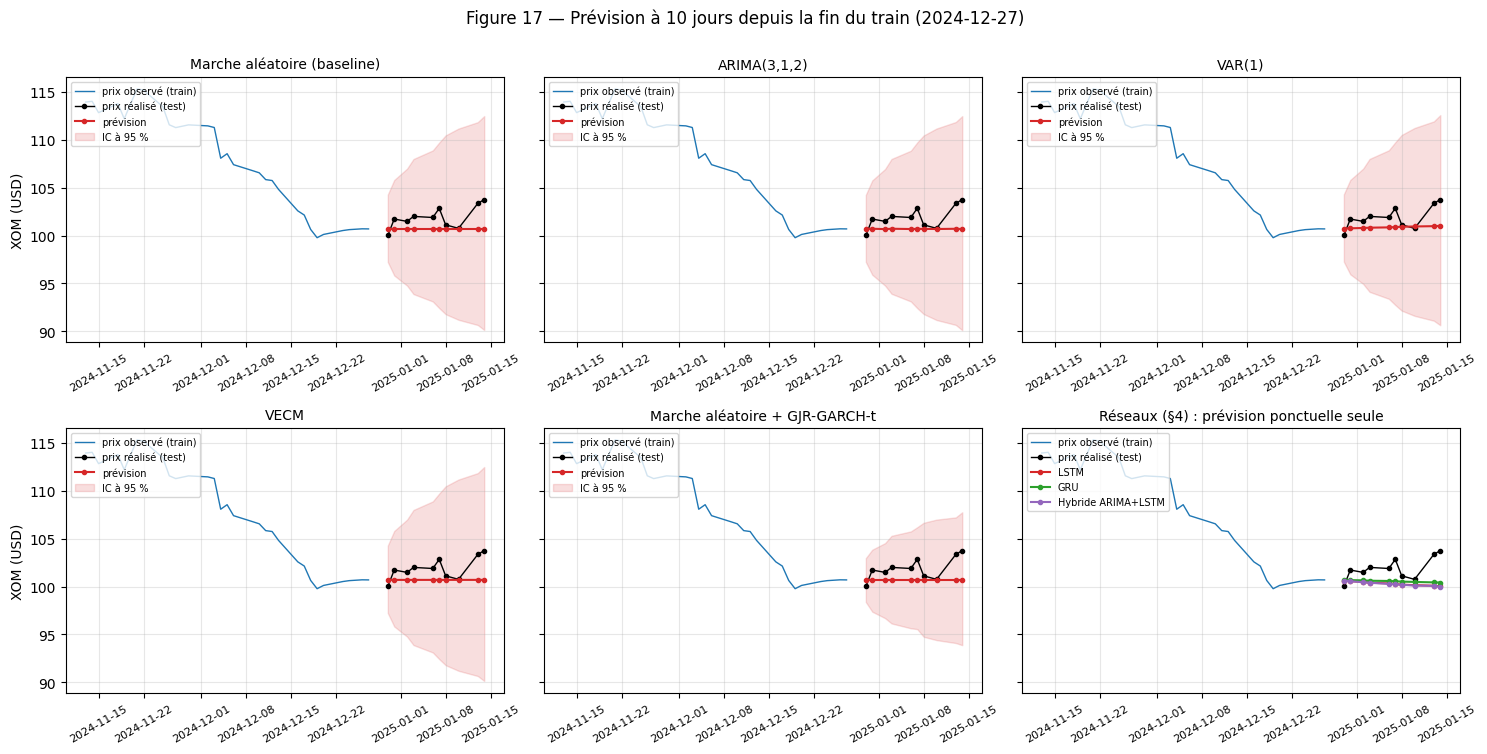

,prévision h = 1 ($),prévision h = 10 ($),IC 95 % h = 10,réalisé h = 10 ($)
Marche aléatoire (baseline),100.6905,100.6905,[90.15 ; 112.47],103.7543
"ARIMA(3,1,2)",100.6799,100.6759,[90.12 ; 112.46],103.7543
VAR(1),100.7235,101.0092,[90.64 ; 112.57],103.7543
VECM,100.6908,100.6937,[90.15 ; 112.47],103.7543
Marche aléatoire + GJR-GARCH-t,100.6905,100.6905,[93.88 ; 107.75],103.7543
LSTM,100.6153,100.0153,—,103.7543
GRU,100.6856,100.4135,—,103.7543
Hybride ARIMA+LSTM,100.5961,99.9695,—,103.7543


In [72]:
P = panel["XOM_price"]
o0 = orig[0]
past = slice(o0 - 30, o0 + 1)
fut = panel.index[o0 + 1:o0 + 11]
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5), sharey=True)
for ax, f in zip(axes.ravel(), FC[:5] + [None]):
    ax.plot(panel.index[past], P.iloc[past], color="tab:blue", lw=1, label="prix observé (train)")
    ax.plot(fut, P.iloc[o0 + 1:o0 + 11], color="black", marker=".", lw=1, label="prix réalisé (test)")
    if f is None:
        for g, col in zip(FC[5:], ["tab:red", "tab:green", "tab:purple"]):
            ax.plot(fut, EV.price_forecast(panel, orig, g)[0], color=col, marker="o", ms=3, label=g["name"])
        ax.set_title("Réseaux (§4) : prévision ponctuelle seule", fontsize=10)
    else:
        ax.plot(fut, EV.price_forecast(panel, orig, f)[0], color="tab:red", marker="o", ms=3, label="prévision")
        ax.fill_between(fut, EV.price_forecast(panel, orig, f, "lo")[0], EV.price_forecast(panel, orig, f, "hi")[0],
                        color="tab:red", alpha=0.15, label="IC à 95 %")
        ax.set_title(f["name"], fontsize=10)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7, loc="upper left")
    ax.tick_params(axis="x", labelrotation=30, labelsize=8)
for ax in axes[:, 0]:
    ax.set_ylabel("XOM (USD)")
fig.suptitle(f"Figure 17 — Prévision à 10 jours depuis la fin du train ({panel.index[o0].date()})", y=1.0)
fig.tight_layout()
save_fig(fig, 17, "prevision_illustrative")
plt.show()

pd.DataFrame({f["name"]: {"prévision h = 1 ($)": EV.price_forecast(panel, orig, f)[0, 0],
                          "prévision h = 10 ($)": EV.price_forecast(panel, orig, f)[0, 9],
                          "IC 95 % h = 10": (f"[{EV.price_forecast(panel, orig, f, 'lo')[0, 9]:.2f} ; "
                                             f"{EV.price_forecast(panel, orig, f, 'hi')[0, 9]:.2f}]" if f["lo"] is not None else "—")}
              for f in FC}).T.assign(**{"réalisé h = 10 ($)": P.iloc[o0 + 10]})

**Interprétation de la figure 17.** Le 2024-12-27, XOM vaut 100,69 $. Dix jours plus tard, elle vaut 103,75 $.

- **Prévisions ponctuelles : presque toutes plates.**
  - La marche aléatoire, la marche aléatoire + GARCH et le VECM prévoient 100,69 $ à tous les horizons.
  - L'ARIMA(3,1,2) prévoit 100,68 $ et le VAR(1) 101,01 $.
  - Les réseaux prévoient une légère baisse, entre 99,97 $ et 100,41 $ à 10 jours.

  Aucun modèle n'anticipe la hausse de 3 %. C'est la traduction directe des sections 2 à 4 : le sens des variations n'est pas prévisible.
- **Intervalles : c'est là que les modèles diffèrent vraiment.** À 10 jours :
  - les modèles à variance constante donnent environ [90,1 ; 112,5] $ ;
  - la marche aléatoire + GJR-GARCH-t donne [93,9 ; 107,8] $, soit un intervalle **38 % plus étroit**.

  Le GARCH « sait » que fin 2024 est une période calme, alors que la variance constante mélange tout le train, crise de 2020 comprise. Le prix réalisé (103,75 $) reste dans les deux intervalles.
- **Une seule origine ne suffit pas pour conclure.** La suite évalue ces prévisions sur les 252 origines.

### 6.2 Tableau récapitulatif unique (prix en dollars)

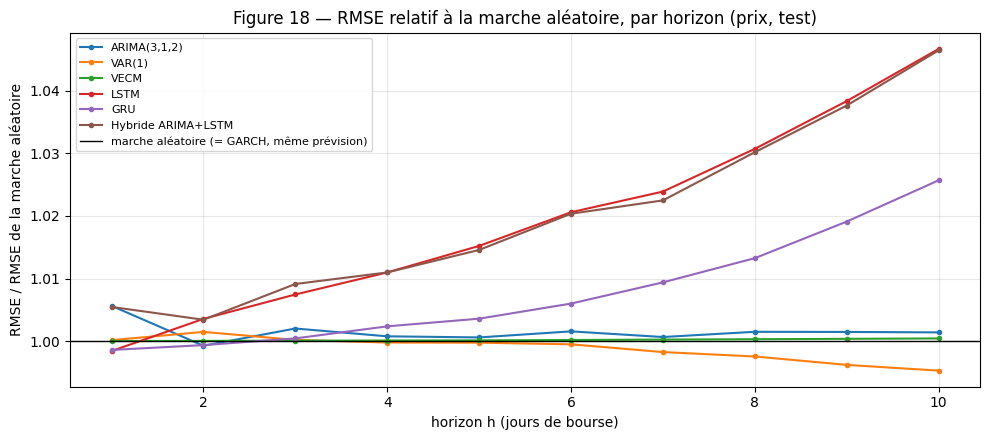

h = 1                          h = 5                         h = 10                       
                                  MSE   RMSE    MAE MAPE (%)     MSE   RMSE    MAE MAPE (%)     MSE   RMSE    MAE MAPE (%)
modèle                                                                                                                    
Marche aléatoire (baseline)    2.4350 1.5600 1.1700   1.1020 13.0850 3.6170 2.7620   2.6020 21.6230 4.6500 3.4870   3.2860
ARIMA(3,1,2)                   2.4630 1.5690 1.1750   1.1060 13.1010 3.6200 2.7640   2.6030 21.6840 4.6570 3.4950   3.2940
VAR(1)                         2.4360 1.5610 1.1660   1.0980 13.0790 3.6160 2.7410   2.5840 21.4200 4.6280 3.4650   3.2710
VECM                           2.4350 1.5600 1.1700   1.1020 13.0890 3.6180 2.7630   2.6020 21.6420 4.6520 3.4890   3.2870
Marche aléatoire + GJR-GARCH-t 2.4350 1.5600 1.1700   1.1020 13.0850 3.6170 2.7620   2.6020 21.6230 4.6500 3.4870   3.2860
LSTM                           2.4270 1.5580 1.1710   1.1020 13.4860 3.6720 2.8100   2.6490 23.6880 4.8670 3.6680   3.4630
GRU                            2.4280 1.5580 1.1700   1.1020 13.1790 3.6300 2.7710   2.6120 22.7480 4.7700 3.5900   3.3850
Hybride ARIMA+LSTM             2.4620 1.5690 1.1750   1.1060 13.4690 3.6700 2.8070   2.6460 23.6780 4.8660 3.6660   3.4610

In [73]:
metrics = EV.metrics_table(panel, orig, FC)
save_table(metrics, "tab36_metriques_prix")

# RMSE relatif à la baseline pour chaque horizon : < 1 = meilleur que la marche aléatoire.
rmse_h = pd.DataFrame({n: [np.sqrt(np.nanmean(e[:, h] ** 2)) for h in range(EV.HORIZON)] for n, e in E.items()},
                      index=EV.HS)
rel = rmse_h.div(rmse_h[BASE], axis=0)
fig, ax = plt.subplots(figsize=(10, 4.5))
for n in rel.columns:
    if n in (BASE, "Marche aléatoire + GJR-GARCH-t"):
        continue
    ax.plot(rel.index, rel[n], marker="o", ms=3, label=n)
ax.axhline(1, color="black", lw=1, label="marche aléatoire (= GARCH, même prévision)")
ax.set_xlabel("horizon h (jours de bourse)")
ax.set_ylabel("RMSE / RMSE de la marche aléatoire")
ax.set_title("Figure 18 — RMSE relatif à la marche aléatoire, par horizon (prix, test)")
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
fig.tight_layout()
save_fig(fig, 18, "rmse_relatif")
plt.show()
metrics.round(3)

**Interprétation du tableau unique (tableau 36) et de la figure 18.**

1. **Aucun modèle ne fait nettement mieux que la marche aléatoire.** À h = 10, son RMSE est de 4,65 $ (MAPE 3,29 %). Les modèles classiques restent tous à moins de 0,5 % de cette valeur.
2. **Le VAR(1) est le seul à faire un peu mieux à moyen terme.**
   - Son RMSE vaut 4,628 $ contre 4,650 $ à h = 10, soit un gain de 0,5 %.
   - Ce gain apparaît à partir de h = 4 et grandit avec l'horizon.
   - Sur le train, en revanche, le Granger robuste n'était pas significatif (§3.2.3), et la section 6.4 montre que ce gain ne l'est pas non plus.
3. **Les réseaux se dégradent avec l'horizon.**
   - À h = 1, le LSTM et le GRU font jeu égal avec la marche aléatoire (1,558 $ contre 1,560 $).
   - À h = 10, ils sont 2,6 % (GRU) à 4,7 % (LSTM) moins bons.
   - Leur légère prévision de baisse (§6.1) s'accumule sur 10 jours, alors que XOM a monté de 17 % sur le test (de 100,69 $ à 117,97 $).
4. **Le VECM ne prévoit pas mieux.** Il est identique à la marche aléatoire à la 3ᵉ décimale près. C'était prévu au §3.2 : avec une demi-vie de 63 jours, la correction d'erreur n'agit qu'à peine en 10 jours.
5. **La marche aléatoire + GARCH a exactement les mêmes erreurs que la baseline**, puisque sa moyenne est nulle. Sa valeur ajoutée est dans les intervalles (§6.3) et la variance (§6.5).
6. **La MAPE est faible, mais elle trompe.** 1,1 % à 1 jour paraît précis, mais un prix reste proche de celui de la veille : la marche aléatoire fait aussi bien. C'est pour cela que l'on compare toujours à cette baseline.

### 6.3 Intervalles de prévision à 95 %

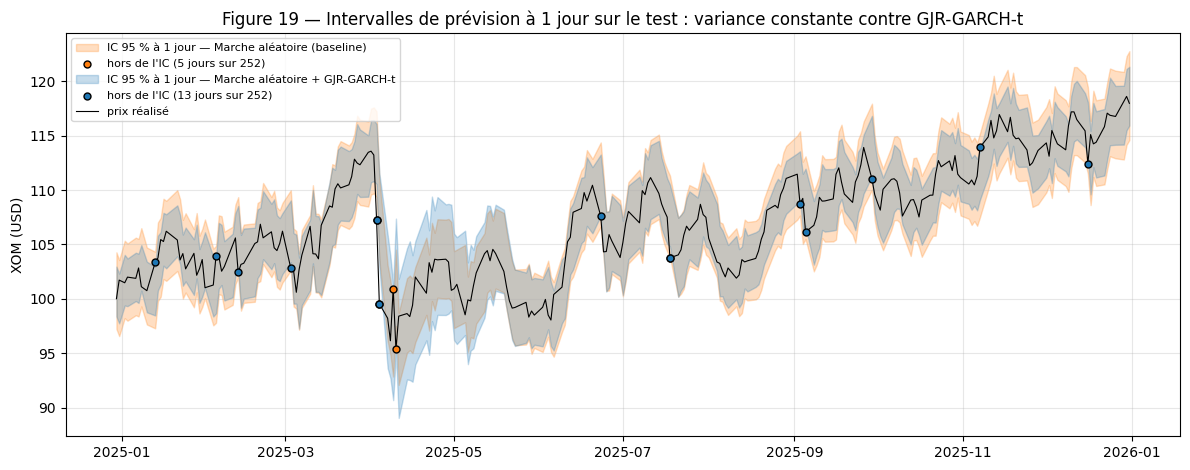

,couverture h = 1 (%),largeur moyenne h = 1 ($),n (h = 1),p binomial h = 1,couverture h = 5 (%),largeur moyenne h = 5 ($),couverture h = 10 (%),largeur moyenne h = 10 ($)
modèle,,,,,,,,
Marche aléatoire (baseline),98.0160,7.4550,252,0.0280,97.9840,16.6600,96.2960,23.5520
"ARIMA(3,1,2)",98.0160,7.4160,252,0.0280,97.9840,16.6220,96.2960,23.5800
VAR(1),98.4130,7.4510,252,0.0090,97.9840,16.3680,96.2960,23.1230
VECM,98.0160,7.4550,252,0.0280,97.9840,16.6630,96.2960,23.5600
Marche aléatoire + GJR-GARCH-t,94.8410,6.2720,252,0.8850,95.5650,14.0410,94.6500,19.9320


In [74]:
intervals = EV.interval_table(panel, orig, FC)
save_table(intervals, "tab37_intervalles")

# Bandes à 1 jour datées à la date cible, pour voir où le prix sort de l'intervalle.
fig, ax = plt.subplots(figsize=(12, 4.8))
tgt = panel.index[orig + 1]
A1 = EV.actual_prices(panel, orig)[:, 0]
for f, col in [(FC[0], "tab:orange"), (FC[4], "tab:blue")]:
    lo, hi = EV.price_forecast(panel, orig, f, "lo")[:, 0], EV.price_forecast(panel, orig, f, "hi")[:, 0]
    ax.fill_between(tgt, lo, hi, color=col, alpha=0.25, label=f"IC 95 % à 1 jour — {f['name']}")
    out = (A1 < lo) | (A1 > hi)
    ax.scatter(tgt[out], A1[out], color=col, s=25, zorder=3, edgecolor="black",
               label=f"hors de l'IC ({out.sum()} jours sur {len(out)})")
ax.plot(tgt, A1, color="black", lw=0.8, label="prix réalisé")
ax.set_ylabel("XOM (USD)")
ax.set_title("Figure 19 — Intervalles de prévision à 1 jour sur le test : variance constante contre GJR-GARCH-t")
ax.grid(alpha=0.3)
ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()
save_fig(fig, 19, "intervalles_test")
plt.show()
intervals.round(3)

**Interprétation des intervalles (tableau 37 et figure 19).** Un bon intervalle à 95 % doit contenir le prix réalisé environ 95 % du temps, avec la largeur la plus petite possible.

| | Couverture à h = 1 | Test binomial (H₀ : couverture = 95 %) | Largeur moyenne à h = 1 | Couverture à h = 10 | Largeur à h = 10 |
| --- | --- | --- | --- | --- | --- |
| Variance constante (marche aléatoire, ARIMA, VAR, VECM) | 98,0 à 98,4 % | p = 0,009 à 0,028 : **H₀ rejetée** | 7,42 à 7,46 $ | 96,3 % | 23,1 à 23,6 $ |
| **GJR-GARCH-t** | **94,8 %** | **p = 0,885 : H₀ non rejetée** | **6,27 $** | **94,65 %** | **19,9 $** |

- **Les intervalles à variance constante sont trop larges.** Ils contiennent le prix réalisé 98 % du temps au lieu de 95 %, et le test binomial rejette la bonne couverture. La raison : leur variance mélange tout le passé, crise de 2020 comprise (volatilité constante d'environ 28 % par an), alors que le test est une période plus calme (§1.6).
- **Le GJR-GARCH-t a une couverture correcte** (94,8 %, p = 0,885) avec des intervalles **16 % plus étroits** à 1 jour et 15 % plus étroits à 10 jours. Il s'adapte au régime de volatilité du moment : ses intervalles s'élargissent en avril 2025, puis se resserrent (figure 19).
- **Une précision.** À h > 1, les intervalles de deux origines voisines se chevauchent, donc leurs dépassements sont liés. Le test binomial n'est valide qu'à h = 1. Les couvertures à 5 et 10 jours sont données à titre indicatif.

**C'est le résultat le plus utile de la section 6.** Aucun modèle ne prévoit mieux le **niveau** du prix, mais le GARCH prévoit mieux son **incertitude**. C'est exactement ce que le §3.3 annonçait : le GARCH prévoit l'amplitude des variations, pas leur sens.

### 6.4 Test de Diebold-Mariano contre la marche aléatoire

**Hypothèses.**
- **H₀ :** les deux modèles ont la même précision, E[e²_modèle − e²_baseline] = 0.
- **H₁ :** leurs précisions diffèrent (test bilatéral).

**Mise en œuvre.**
- La perte est quadratique, sur le prix en dollars.
- La variance de la moyenne des écarts de pertes est calculée avec h − 1 autocovariances, car des prévisions à h jours qui se chevauchent ont des erreurs autocorrélées jusqu'à l'ordre h − 1.
- On applique ensuite la correction de Harvey, Leybourne et Newbold, puis une loi de Student à n − 1 degrés de liberté.
- Une statistique **négative** signifie que le modèle fait mieux que la marche aléatoire.

In [75]:
dm = EV.dm_vs_baseline(E, BASE)
dm_mat = EV.dm_pvalue_matrix(E, BASE)
save_table(dm, "tab38_diebold_mariano")
save_table(dm_mat, "tab38b_dm_pvalues_horizons")
print("p-values de Diebold-Mariano contre la marche aléatoire, h = 1 à 10 (NaN : prévisions identiques) :")
display(dm_mat.round(3))
dm.round(3)

p-values de Diebold-Mariano contre la marche aléatoire, h = 1 à 10 (NaN : prévisions identiques) :


,1,2,3,4,5,6,7,8,9,10
"ARIMA(3,1,2)",0.4110,0.7270,0.1550,0.5820,0.3840,0.0000,0.0890,0.3240,0.0000,0.0000
VAR(1),0.9850,0.8330,0.9730,0.9740,0.9760,0.9540,0.8560,0.8130,0.7220,0.6880
VECM,0.8390,0.7390,0.6540,0.6290,0.6080,0.4930,0.3920,0.3360,0.3270,0.3150
Marche aléatoire + GJR-GARCH-t,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
LSTM,0.7560,0.5210,0.3820,0.2890,0.1780,0.0780,0.0300,0.0140,0.0100,0.0110
GRU,0.7280,0.8850,0.9460,0.7710,0.6860,0.4790,0.1670,0.0010,0.0010,0.0000
Hybride ARIMA+LSTM,0.5310,0.5580,0.2680,0.2890,0.1800,0.0780,0.0290,0.0120,0.0070,0.0080


n      DM  p-value  repli h = 1                        verdict (5 %)
modèle                         h                                                                         
ARIMA(3,1,2)                   1   252  0.8240   0.4110        False      pas de différence significative
                               5   248  0.8730   0.3840        False      pas de différence significative
                               10  243  4.1080   0.0000        False          significativement moins bon
VAR(1)                         1   252  0.0180   0.9850        False      pas de différence significative
                               5   248 -0.0300   0.9760        False      pas de différence significative
                               10  243 -0.4020   0.6880        False      pas de différence significative
VECM                           1   252  0.2040   0.8390        False      pas de différence significative
                               5   248  0.5130   0.6080        False      pas de différence significative
                               10  243  1.0080   0.3150        False      pas de différence significative
Marche aléatoire + GJR-GARCH-t 1   252     NaN      NaN        False  prévisions identiques à la baseline
                               5   248     NaN      NaN        False  prévisions identiques à la baseline
                               10  243     NaN      NaN        False  prévisions identiques à la baseline
LSTM                           1   252 -0.3100   0.7560        False      pas de différence significative
                               5   248  1.3510   0.1780        False      pas de différence significative
                               10  243  2.5590   0.0110        False          significativement moins bon
GRU                            1   252 -0.3490   0.7280        False      pas de différence significative
                               5   248  0.4050   0.6860        False      pas de différence significative
                               10  243  4.4550   0.0000         True          significativement moins bon
Hybride ARIMA+LSTM             1   252  0.6280   0.5310        False      pas de différence significative
                               5   248  1.3460   0.1800        False      pas de différence significative
                               10  243  2.6940   0.0080        False          significativement moins bon

**Interprétation du test de Diebold-Mariano (tableaux 38 et 38b).**

- **Aucun modèle n'est significativement meilleur que la marche aléatoire, à aucun horizon.**
  - Le VAR(1), le meilleur à h = 10, a DM = −0,40 et p = 0,69 : on ne rejette pas H₀. Son gain de 0,5 % est du bruit.
  - Le VECM a des p-values comprises entre 0,32 et 0,84.
- **Plusieurs modèles sont significativement moins bons à long horizon :**
  - le LSTM (p = 0,011), le GRU (p < 0,001) et l'hybride (p = 0,008) à h = 10 ;
  - pour le LSTM et l'hybride, dès h = 7 (p ≈ 0,03) ;
  - l'ARIMA(3,1,2) à h = 6, 9 et 10 (p < 0,001).

  Leurs petites prévisions non nulles, mais fausses, s'accumulent.
- **À court terme, rien ne se distingue.** À h = 1, toutes les p-values dépassent 0,4.
- **Remarque technique.** Pour le GRU à h = 10, la variance HAC estimée est négative, ce qui arrive avec des autocovariances non pondérées. Le test est alors refait avec h = 1 (variance et correction HLN), exactement comme `forecast::dm.test` en R (colonne « repli h = 1 »). La conclusion ne change pas : DM = 4,45, p < 0,001.

**Conclusion (grille d'interprétation).**
- **H₀ :** même précision que la marche aléatoire.
- **Résultat :** H₀ n'est jamais rejetée en faveur d'un modèle. Elle est rejetée **contre** les réseaux et l'ARIMA(3,1,2) à long horizon.
- **Sens concret :** la marche aléatoire reste la meilleure prévision du prix de XOM. Les modèles plus complexes ne font, au mieux, qu'égaler la baseline. C'est l'efficience faible du marché, mesurée sur des données que les modèles n'ont jamais vues.

### 6.5 Évaluation de la variance prévue (GARCH)

La variance ne se compare pas à une « vraie » variance, qui n'est jamais observée, mais au rendement au carré du lendemain, r²_{t+1}. C'est un indicateur bruité mais sans biais de la variance du jour.

**Pertes utilisées.**
- **QLIKE = ln σ̂² + r²/σ̂².** C'est la perte recommandée par Patton (2011) : elle classe correctement les modèles malgré le bruit de r², et elle pénalise davantage une variance **sous-estimée**.
- **MSE = (r² − σ̂²)².**

**Prévisions concurrentes, toutes connues à la date t :**
- la variance constante de la baseline ;
- la variance réalisée sur 21 jours ;
- l'EWMA de RiskMetrics (λ = 0,94).

On applique Diebold-Mariano à h = 1, contre le GJR-GARCH-t.

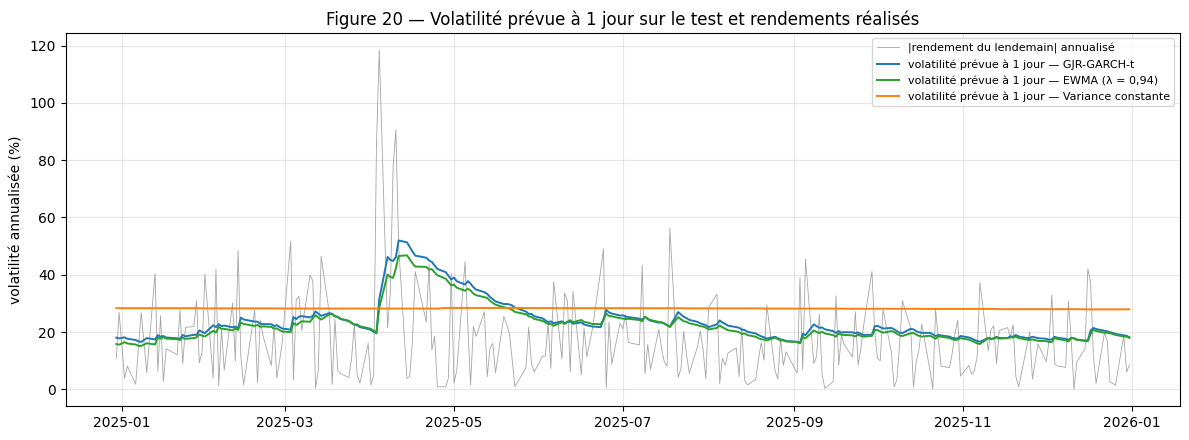

Paramètres du GJR-GARCH-t ré-estimés tous les 20 jours (tableau 40) :


,omega,alpha[1],gamma[1],beta[1],nu
2024-12-27,0.0094,0.0430,0.0421,0.9353,7.4681
2025-01-29,0.0094,0.0421,0.0428,0.9358,7.5742
2025-02-27,0.0095,0.0420,0.0429,0.9359,7.6008
2025-03-27,0.0096,0.0415,0.0443,0.9358,7.6578
2025-04-25,0.0099,0.0419,0.0459,0.9351,7.2377
2025-05-23,0.0109,0.0448,0.0439,0.9326,7.1853
2025-06-24,0.0107,0.0451,0.0426,0.9330,7.2706
2025-07-23,0.0107,0.0444,0.0421,0.9338,7.2538
2025-08-20,0.0110,0.0460,0.0405,0.9326,7.2491
2025-09-18,0.0108,0.0448,0.0401,0.9340,7.2270


,QLIKE moyen,MSE moyen,DM QLIKE,p QLIKE,DM MSE,p MSE
prévision de variance,,,,,,
GJR-GARCH-t,1.7320,24.5374,NaN,NaN,NaN,NaN
Variance constante,1.8437,26.0781,1.7867,0.0752,0.9416,0.3473
Volatilité réalisée 21 jours,1.7636,25.7884,1.0135,0.3118,1.6909,0.0921
"EWMA (λ = 0,94)",1.7378,24.4116,0.3812,0.7034,-0.2317,0.8170


In [76]:
g = FC[4]
var_fc = {"GJR-GARCH-t": g["var1"], "Variance constante": FC[0]["var1"], **EV.variance_benchmarks(panel, orig)}
var_eval = EV.variance_eval(panel, orig, var_fc, "GJR-GARCH-t")
save_table(var_eval, "tab39_variance_qlike")
save_table(g["params"], "tab40_garch_parametres_reestimes")

ann = np.sqrt(cfg["features"]["annualization"])
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(tgt, np.abs(panel["XOM_ret"].to_numpy()[orig + 1]) * ann, color="grey", lw=0.6, alpha=0.7,
        label="|rendement du lendemain| annualisé")
for n, col in [("GJR-GARCH-t", "tab:blue"), ("EWMA (λ = 0,94)", "tab:green"), ("Variance constante", "tab:orange")]:
    ax.plot(tgt, np.sqrt(var_fc[n]) * ann, color=col, lw=1.4, label=f"volatilité prévue à 1 jour — {n}")
ax.set_ylabel("volatilité annualisée (%)")
ax.set_title("Figure 20 — Volatilité prévue à 1 jour sur le test et rendements réalisés")
ax.grid(alpha=0.3)
ax.legend(fontsize=8, loc="upper right")
fig.tight_layout()
save_fig(fig, 20, "volatilite_prevue")
plt.show()
print("Paramètres du GJR-GARCH-t ré-estimés tous les 20 jours (tableau 40) :")
display(g["params"].round(4))
var_eval.round(4)

**Interprétation de la variance prévue (tableau 39 et figure 20).**

| Prévision de variance | QLIKE moyen | DM QLIKE contre GARCH (p-value) |
| --- | --- | --- |
| **GJR-GARCH-t** | **1,732** (la plus faible) | — |
| EWMA (λ = 0,94) | 1,738 | p = 0,70 |
| Volatilité réalisée sur 21 jours | 1,764 | p = 0,31 |
| Variance constante | 1,844 | p = 0,075 |

- **Le GJR-GARCH-t a la meilleure perte QLIKE.** Mais l'écart avec la variance constante n'est significatif qu'à 10 % (p = 0,075), pas à 5 %. Un an de test, avec une seule vraie période agitée, donne peu de puissance au test.
- **L'EWMA fait presque aussi bien** (p = 0,70). C'est un GARCH intégré sans paramètre à estimer. Cela rejoint le §3.3 : la persistance estimée du GARCH (0,999) est proche de l'intégration.
- **La figure 20 montre l'adaptation du GARCH.** Sa volatilité prévue culmine à **52 %** pour le lendemain du 2025-04-10, à la fin de la séquence des droits de douane américains : annonce du 2 avril, chute des 3 et 4 avril, suspension du 9 avril, nouvelle baisse le 10 avril (`docs/sources.md`). Elle redescend ensuite : entre 17 et 21 % en novembre et décembre, avec un minimum de 16,2 % début septembre. La variance constante reste à environ 28 % toute l'année.
- **Les paramètres sont stables** (tableau 40). Sur les 13 ré-estimations, γ varie de 0,039 à 0,046, β de 0,933 à 0,936, et ν de 7,2 à 7,7. Le modèle du §3.3 reste valable sur 2025.

### 6.6 Choix final : performance, interprétabilité et coût

In [77]:
d10 = dm.xs(10, level="h")
cost = {f["name"]: f["seconds"] for f in FC}
grid_s = pd.read_csv(ROOT / "outputs/tables/tab31_deep_grille.csv")["durée (s)"].sum()
interp = {
    "Marche aléatoire (baseline)": "totale : aucun paramètre de moyenne",
    "ARIMA(3,1,2)": "faible : racines AR et MA presque compensées (§3.1)",
    "VAR(1)": "bonne : coefficients, IRF, Granger",
    "VECM": "bonne : équilibre de long terme, α, demi-vie",
    "Marche aléatoire + GJR-GARCH-t": "bonne : levier γ, persistance, loi de Student",
    "LSTM": "très faible (boîte noire)",
    "GRU": "très faible (boîte noire)",
    "Hybride ARIMA+LSTM": "très faible (boîte noire)",
}
choice = pd.DataFrame({
    "RMSE h = 10 ($)": metrics[("h = 10", "RMSE")],
    "écart à la baseline h = 10 (%)": 100 * (metrics[("h = 10", "RMSE")] / metrics.loc[BASE, ("h = 10", "RMSE")] - 1),
    "DM h = 10 contre la baseline": d10["verdict (5 %)"].reindex(metrics.index).fillna("référence"),
    "couverture IC 95 % h = 1 (%)": intervals["couverture h = 1 (%)"].reindex(metrics.index),
    "interprétabilité": pd.Series(interp),
    "coût des prévisions sur le test (s)": pd.Series(cost),
})
for n in ["LSTM", "GRU", "Hybride ARIMA+LSTM"]:
    choice.loc[n, "coût des prévisions sur le test (s)"] = np.nan
choice["coût d'entraînement"] = ["négligeable", "13 estimations", "négligeable", "négligeable", "13 estimations",
                                 *[f"grille §4 : {grid_s / 60:.0f} min (80 entraînements) + 3 seeds"] * 2,
                                 "ARIMA + 3 seeds LSTM"]
save_table(choice, "tab41_choix_final")
choice.round(3)

,RMSE h = 10 ($),écart à la baseline h = 10 (%),DM h = 10 contre la baseline,couverture IC 95 % h = 1 (%),interprétabilité,coût des prévisions sur le test (s),coût d'entraînement
Marche aléatoire (baseline),4.6500,0.0000,référence,98.0160,totale : aucun paramètre de moyenne,0.0000,négligeable
"ARIMA(3,1,2)",4.6570,0.1400,significativement moins bon,98.0160,faible : racines AR et MA presque compensées (...,14.3560,13 estimations
VAR(1),4.6280,-0.4710,pas de différence significative,98.4130,"bonne : coefficients, IRF, Granger",0.0610,négligeable
VECM,4.6520,0.0430,pas de différence significative,98.0160,"bonne : équilibre de long terme, α, demi-vie",0.7310,négligeable
Marche aléatoire + GJR-GARCH-t,4.6500,0.0000,prévisions identiques à la baseline,94.8410,"bonne : levier γ, persistance, loi de Student",5.1160,13 estimations
LSTM,4.8670,4.6660,significativement moins bon,NaN,très faible (boîte noire),NaN,grille §4 : 10 min (80 entraînements) + 3 seeds
GRU,4.7700,2.5680,significativement moins bon,NaN,très faible (boîte noire),NaN,grille §4 : 10 min (80 entraînements) + 3 seeds
Hybride ARIMA+LSTM,4.8660,4.6430,significativement moins bon,NaN,très faible (boîte noire),NaN,ARIMA + 3 seeds LSTM


**Conclusion de la section 6 : quel modèle pour quel usage ?**

| Usage | Modèle recommandé | Justification |
| --- | --- | --- |
| **Prévoir le niveau du prix** (1 à 10 jours) | **Marche aléatoire** | Aucun modèle ne la bat significativement (Diebold-Mariano). Elle est gratuite et parfaitement interprétable. Les réseaux et l'ARIMA(3,1,2) sont significativement moins bons à 10 jours. |
| **Mesurer le risque** (intervalles, VaR, taille de position) | **Marche aléatoire + GJR-GARCH-t** | C'est le seul modèle dont la couverture à 95 % n'est pas rejetée (94,8 %), avec des intervalles 16 % plus étroits. Il a la meilleure perte QLIKE et des paramètres interprétables (effet de levier) et stables. Il coûte environ 5 s pour tout le test. |
| **Comprendre le lien XOM / XLE** | **VAR(1) et VECM** (§3.2) | Utiles pour l'analyse (IRF, équilibre de long terme), pas pour la prévision : le VAR ne gagne que 0,5 % (p = 0,69), le VECM rien. |

**Modèle final retenu : ARIMA(0,1,0) + GJR-GARCH(1,1) avec loi de Student.** C'est le même que celui retenu au §3.3 : l'évaluation hors échantillon confirme le choix fait sur le train.

**Limites.**
- **Un an de test**, globalement calme et haussier (+17 %), est une seule réalisation de l'histoire. Le classement des modèles pourrait changer dans un régime de crise.
- **Les réseaux n'ont pas été ré-entraînés** pendant le test, contrairement aux modèles classiques. Ce désavantage est faible, puisqu'ils n'apprennent rien sur le train (§4).
- **Les coûts de transaction** ne sont pas pris en compte. Ils ne feraient que renforcer la conclusion : aucune stratégie fondée sur ces prévisions ne serait rentable.

### 6.7 Export des erreurs pour la vérification en R

Le notebook R (`classical_R.Rmd`) relit ces erreurs et recalcule le test de Diebold-Mariano avec `forecast::dm.test`, pour vérifier notre implémentation.

In [78]:
rows = []
for n, e in E.items():
    for h in EV.EVAL_H:
        ok = ~np.isnan(e[:, h - 1])
        rows += [{"origine": panel.index[o].date(), "h": h, "modèle": n, "erreur ($)": v} for o, v in zip(orig[ok], e[ok, h - 1])]
err_tab = pd.DataFrame(rows)
save_table(err_tab, "tab42_erreurs_test", index=False)
print(f"{len(err_tab)} erreurs exportées ({err_tab['modèle'].nunique()} modèles × horizons {EV.EVAL_H})")

5944 erreurs exportées (8 modèles × horizons [1, 5, 10])


### 6.8 Prévision depuis la dernière date disponible (entrée du prompt 3)

C'est la prévision que l'on ferait le jour de la décision. On utilise le modèle final, marche aléatoire + GJR-GARCH-t, **ré-estimé sur toutes les données**, train et test, jusqu'au 2025-12-31. Les intervalles viennent de 20 000 trajectoires simulées. Ces valeurs sont celles transmises au LLM dans le prompt 3 (`llm/prompts/03_recommandations.md`).

In [79]:
last_fc, last_garch = EV.forecast_from_last(panel)
print(f"Dernier prix observé ({panel.index[-1].date()}) : {panel['XOM_price'].iloc[-1]:.2f} $")
print("Paramètres du GJR-GARCH-t estimé sur 2016-2025 :", last_garch.params.round(4).to_dict())
last_fc.round(2)

Dernier prix observé (2025-12-31) : 117.97 $
Paramètres du GJR-GARCH-t estimé sur 2016-2025 : {'omega': 0.0108, 'alpha[1]': 0.0437, 'gamma[1]': 0.0394, 'beta[1]': 0.935, 'nu': 7.4788}


,prévision du prix ($),borne basse IC 95% ($),borne haute IC 95% ($),"volatilité prévue du jour h (annualisée, %)"
h,,,,
1,117.9700,115.2900,120.6500,17.8400
2,117.9700,114.2300,121.7700,17.9100
3,117.9700,113.4800,122.5400,17.9800
4,117.9700,112.8000,123.3000,18.0400
5,117.9700,112.1700,123.9600,18.0900
6,117.9700,111.6100,124.5000,18.1500
7,117.9700,111.1000,124.9800,18.2200
8,117.9700,110.6400,125.5200,18.2900
9,117.9700,110.2100,125.9400,18.3500


## 7. Extensions

Cette section contient trois extensions du cahier (§7, bloc D du barème) :
- **7.1** la **corrélation dynamique** entre XOM et son secteur, mesurée par une corrélation glissante sur 60 jours plutôt que par une corrélation unique ;
- **7.2** une **variable exogène externe**, le Brent, introduite dans un VARX ;
- **7.3** une corrélation dynamique **modélisée** par un DCC-GARCH.

On utilise ici tout l'échantillon, de 2016 à 2025 : il s'agit de décrire la relation, pas de prévoir. L'évaluation prédictive du VARX (§7.2.3) suit en revanche le protocole du §6, sur le test uniquement.

### 7.1 Corrélation glissante sur 60 jours

**Définition.** À chaque date t, la corrélation est calculée sur les 60 derniers jours de bourse, de t − 59 à t, soit environ un trimestre. Elle n'utilise que le passé.

**Bande de confiance.** La bande à 95 % vient de la transformation de Fisher. Elle suppose des rendements indépendants et de variance constante : ce n'est qu'un **ordre de grandeur** de l'incertitude.

**Annotations.** Seuls sont annotés des événements dont la date et le contenu sont sourcés dans `docs/sources.md`. Ils sont numérotés sur la figure et listés en dessous.

**Valeurs manquantes.** Les corrélations avec le Brent ont un trou entre fin 2016 et début 2017 : les fenêtres de 60 jours qui contiennent l'un des 2 jours où le Brent manque (§1.4) ne sont pas calculées, faute d'imputation.

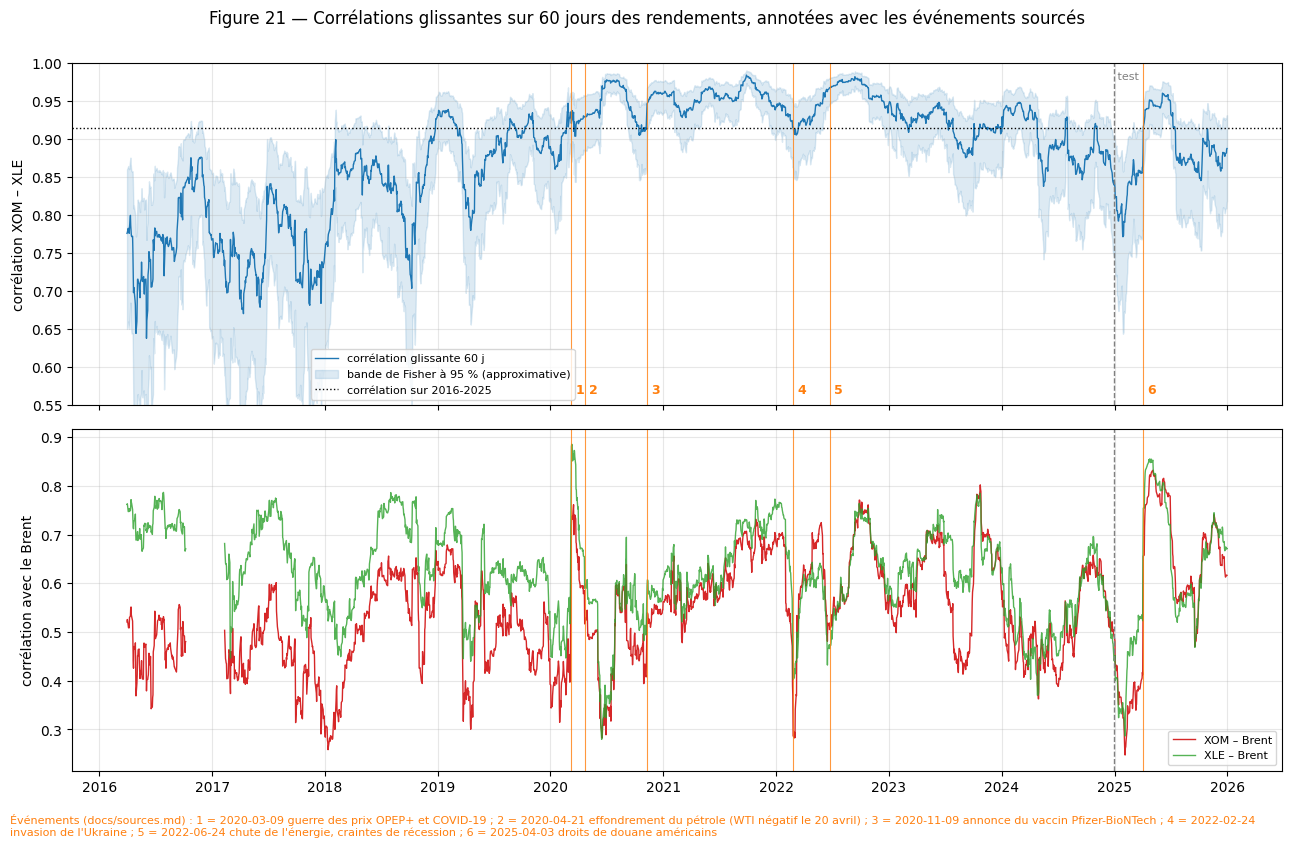

,2016-2019,2020,2021-2024,2025 (test),2016-2025
XOM – XLE,0.8290,0.9400,0.9380,0.9040,0.9140
XOM – Brent,0.4910,0.4870,0.5940,0.6440,0.5300
XLE – Brent,0.6690,0.5560,0.6060,0.6550,0.5990


,événement,corr. XOM – XLE à la date,corr. XOM – XLE 60 jours après,corr. XOM – Brent à la date
date,,,,
2020-03-09,guerre des prix OPEP+ et COVID-19,0.9210,0.9380,0.7190
2020-04-21,effondrement du pétrole (WTI négatif le 20 avril),0.9290,0.9750,0.5170
2020-11-09,annonce du vaccin Pfizer-BioNTech,0.9470,0.9630,0.5260
2022-02-24,invasion de l'Ukraine,0.9170,0.9450,0.3690
2022-06-24,"chute de l'énergie, craintes de récession",0.9680,0.9790,0.5100
2025-04-03,droits de douane américains,0.8820,0.9510,0.5510


moyenne  minimum date du minimum  maximum date du maximum  jours
paire       période                                                                      
XOM – XLE   2016-2019     0.8180   0.6380      2016-06-02   0.9390      2019-02-04    946
            2020          0.9370   0.8610      2020-01-16   0.9780      2020-07-01    253
            2021-2024     0.9310   0.8380      2024-05-16   0.9840      2021-09-27   1005
            2025 (test)   0.8840   0.7720      2025-01-28   0.9610      2025-06-05    250
            2016-2025     0.8830   0.6380      2016-06-02   0.9840      2021-09-27   2454
XOM – Brent 2016-2019     0.4910   0.2580      2018-01-11   0.6790      2019-02-01    861
            2020          0.4860   0.2820      2020-06-16   0.7610      2020-03-16    253
            2021-2024     0.5880   0.2830      2022-03-01   0.8020      2023-10-24   1005
            2025 (test)   0.5990   0.2470      2025-02-04   0.8320      2025-05-05    250
            2016-2025     0.5430   0.2470      2025-02-04   0.8320      2025-05-05   2369
XLE – Brent 2016-2019     0.6490   0.4400      2019-04-18   0.7870      2016-07-27    861
            2020          0.5510   0.2800      2020-06-15   0.8850      2020-03-10    253
            2021-2024     0.6170   0.3700      2024-04-26   0.7850      2023-10-24   1005
            2025 (test)   0.6170   0.2860      2025-02-04   0.8550      2025-04-25    250
            2016-2025     0.6220   0.2800      2020-06-15   0.8850      2020-03-10   2369

In [80]:
from src import extensions as X

rc = {"XOM – XLE": X.rolling_corr(panel), "XOM – Brent": X.rolling_corr(panel, b=X.BRENT),
      "XLE – Brent": X.rolling_corr(panel, "XLE_ret", X.BRENT)}
periods = {"2016-2019": ("2016", "2019"), "2020": ("2020", "2020"), "2021-2024": ("2021", "2024"),
           "2025 (test)": ("2025", "2025"), "2016-2025": ("2016", "2025")}
corr_sum = X.corr_summary(rc, periods)
corr_stat = X.static_corr(panel, {"XOM – XLE": ("XOM_ret", "XLE_ret"), "XOM – Brent": ("XOM_ret", X.BRENT),
                                  "XLE – Brent": ("XLE_ret", X.BRENT)}, periods)
save_table(corr_sum, "tab44_correlation_glissante")
save_table(corr_stat, "tab44b_correlation_statique")

lo, hi = X.fisher_band(rc["XOM – XLE"], 60)
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
ax = axes[0]
ax.plot(rc["XOM – XLE"].index, rc["XOM – XLE"], color="tab:blue", lw=1, label="corrélation glissante 60 j")
ax.fill_between(lo.index, lo, hi, color="tab:blue", alpha=0.15, label="bande de Fisher à 95 % (approximative)")
ax.axhline(corr_stat.loc["XOM – XLE", "2016-2025"], color="black", ls=":", lw=1, label="corrélation sur 2016-2025")
ax.set_ylabel("corrélation XOM – XLE")
ax.set_ylim(0.55, 1.0)
ax = axes[1]
ax.plot(rc["XOM – Brent"].index, rc["XOM – Brent"], color="tab:red", lw=1, label="XOM – Brent")
ax.plot(rc["XLE – Brent"].index, rc["XLE – Brent"], color="tab:green", lw=1, alpha=0.8, label="XLE – Brent")
ax.set_ylabel("corrélation avec le Brent")
for ax in axes:
    ax.axvline(test.index[0], color="grey", ls="--", lw=1)
    for k, (d, lab) in enumerate(X.EVENTS.items()):
        ax.axvline(pd.Timestamp(d), color="tab:orange", lw=0.8, alpha=0.8)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc="lower right")
# Légende du haut placée avant 2020, où le bas du graphique est vide, pour ne pas masquer l'événement 6.
axes[0].legend(fontsize=8, loc="lower right", bbox_to_anchor=(0.42, 0.0))
# Événements numérotés sur la figure, légende complète en dessous : des étiquettes longues se chevaucheraient.
for k, d in enumerate(X.EVENTS, start=1):
    axes[0].annotate(str(k), (pd.Timestamp(d), 0.565), fontsize=9, color="tab:orange", fontweight="bold",
                     xytext=(3, 0), textcoords="offset points")
axes[0].text(test.index[0], 0.99, " test", fontsize=8, color="grey", va="top")
fig.text(0.01, -0.03, "Événements (docs/sources.md) : " + " ; ".join(f"{k} = {d} {lab}" for k, (d, lab) in enumerate(X.EVENTS.items(), start=1)),
         fontsize=8, color="tab:orange", wrap=True)
axes[1].xaxis.set_major_locator(mdates.YearLocator())
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.suptitle("Figure 21 — Corrélations glissantes sur 60 jours des rendements, annotées avec les événements sourcés", y=1.0)
fig.tight_layout()
save_fig(fig, 21, "correlation_glissante")
plt.show()

events_tab = pd.DataFrame([{"date": d, "événement": lab,
                            "corr. XOM – XLE à la date": rc["XOM – XLE"].iloc[panel.index.searchsorted(pd.Timestamp(d))],
                            "corr. XOM – XLE 60 jours après": rc["XOM – XLE"].iloc[min(panel.index.searchsorted(pd.Timestamp(d)) + 59, len(panel) - 1)],
                            "corr. XOM – Brent à la date": rc["XOM – Brent"].iloc[panel.index.searchsorted(pd.Timestamp(d))]}
                           for d, lab in X.EVENTS.items()]).set_index("date")
display(corr_stat.round(3))
display(events_tab.round(3))
corr_sum.round(3)

**Interprétation de la corrélation glissante (figure 21, tableaux 44 et 44b).**

**1. XOM et XLE : très liés, mais pas avec une intensité constante.**

| Période | Corrélation XOM – XLE (moyenne des fenêtres de 60 jours) |
| --- | --- |
| 2016-2019 | 0,82 (minimum 0,64 le 2016-06-02) |
| 2020 | 0,94 |
| 2021-2024 | 0,93 (maximum 0,98 le 2021-09-27) |
| 2025 (test) | 0,88 |

- **Le lien s'est durablement renforcé à partir de 2020.** Il passe de 0,82 à 0,93–0,94, et l'écart (environ 0,11) dépasse nettement la demi-largeur de la bande de Fisher, d'environ 0,05 pour une corrélation de 0,9.
- **Avant 2020, XOM avait davantage de mouvements propres.** Une corrélation de 0,82 laisse environ 1 − 0,82² ≈ 33 % de variance propre à XOM, contre environ 13 % à 0,93.
- **La corrélation unique du §3.2 masque ces variations.** La valeur de 0,915 (corrélation des chocs) correspond à la moyenne de régimes différents.

**2. Les chocs communs font monter la corrélation.** Après chacun des 6 événements annotés, la corrélation XOM – XLE est plus haute 60 jours plus tard qu'à la date de l'événement :
- **avril 2025 (droits de douane) :** de 0,88 à 0,95 ;
- **mars 2020 :** de 0,92 à 0,94 ;
- **avril 2020 :** de 0,93 à 0,975.

C'est un fait stylisé bien connu : en période de crise, un même choc domine tous les titres d'un secteur, et la diversification à l'intérieur du secteur disparaît justement quand on en a besoin. Cela rejoint l'IRF du §3.2.6 : l'essentiel du lien est contemporain.

**3. Le Brent est un lien beaucoup plus lâche.**
- **Corrélation de XOM avec le Brent :** 0,53 en moyenne sur 2016-2025 (corrélation statique), contre 0,91 avec XLE. Les fenêtres de 60 jours varient de 0,25 à 0,83.
- **Le Brent n'explique donc qu'environ 28 % de la variance quotidienne de XOM** (0,53²). XOM est d'abord une **action** : elle réagit aussi au marché boursier, aux résultats de l'entreprise, aux marges de raffinage et à sa politique de dividendes.
- **Le lien avec le Brent s'est renforcé en 2021-2025** (0,59 à 0,60 en moyenne, contre 0,49 avant).
- **Un creux de 0,28 apparaît le 2022-03-01**, alors que le Brent montait fortement après l'invasion de l'Ukraine. Attention à ne pas inventer de cause : cette valeur porte sur les 60 jours qui **finissent** le 1ᵉʳ mars, c'est-à-dire de décembre 2021 à février 2022. L'annonce par ExxonMobil de sa sortie de Sakhalin-1 est intervenue **le soir du 1ᵉʳ mars** (S&P Global, `docs/sources.md`). Elle ne peut donc pas expliquer ce creux, et on le laisse sans explication.

**Conséquence pour la modélisation.** Le lien XOM – XLE n'est pas constant. Le §7.3 le modélise avec une corrélation **conditionnelle** (DCC-GARCH), au lieu de seulement la constater.

### 7.2 VARX : le Brent comme variable exogène

**Modèle.** On estime un VAR(1) des rendements de XOM et de XLE, augmenté du rendement du Brent :

y_t = c + A y_{t−1} + B · Brent_{t−k} + u_t.

On compare deux versions, car elles répondent à des questions différentes :
- **k = 0, Brent du même jour.** Le pétrole **explique**-t-il les mouvements du jour ? Cette version ne peut pas servir à prévoir, puisque le Brent du jour n'est pas connu la veille.
- **k = 1, Brent de la veille.** Le pétrole d'hier aide-t-il à **prévoir** XOM ? C'est la seule version utilisable en prévision.

**Estimation.**
- Par équation, par MCO, sur le train. C'est identique à `statsmodels.VAR(..., exog=...)`, vérifié coefficient par coefficient.
- Erreurs-types robustes HC3, comme pour le Granger du §3.2.
- Robustesse : on refait l'estimation hors 2020, car le Brent y connaît des chocs de −24 % et +21 % en rendement simple.
- Les 5 jours où le Brent manque (§1.4) sont retirés, sans imputation.

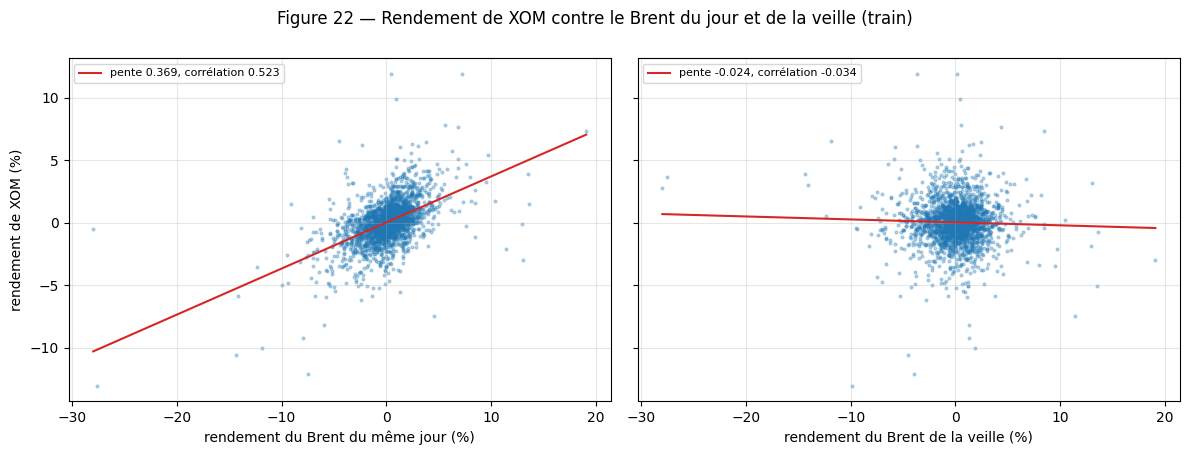

,,échantillon,coefficient,erreur-type HC3,t,p-value HC3,R² VARX,R² VAR(1) seul,gain de R² (points),n
équation,variable exogène,,,,,,,,,
XOM_ret,Brent (t),train complet,0.3706,0.0285,13.0209,0.0000,0.2786,0.0036,27.4944,2256
XLE_ret,Brent (t),train complet,0.4547,0.0378,12.0355,0.0000,0.3606,0.0036,35.6984,2256
XOM_ret,Brent (t−1),train complet,-0.0054,0.0315,-0.1707,0.8644,0.0037,0.0037,0.0037,2256
XLE_ret,Brent (t−1),train complet,0.0136,0.0370,0.3686,0.7124,0.0039,0.0037,0.0207,2256
XOM_ret,Brent (t),train hors 2020,0.3735,0.0161,23.1458,0.0000,0.2977,0.0007,29.7033,2003
XLE_ret,Brent (t),train hors 2020,0.4408,0.0155,28.5149,0.0000,0.3954,0.0001,39.5339,2003
XOM_ret,Brent (t−1),train hors 2020,-0.0269,0.0229,-1.1752,0.2399,0.0016,0.0007,0.0933,2003
XLE_ret,Brent (t−1),train hors 2020,-0.0397,0.0235,-1.6898,0.0911,0.0020,0.0001,0.1941,2003


In [81]:
tr_end = train.index[-1]
samples = {"train complet": lambda idx: idx <= tr_end, "train hors 2020": lambda idx: (idx <= tr_end) & (idx.year != 2020)}
varx_tab = X.varx_analysis(panel, samples)
save_table(varx_tab, "tab45_varx_brent")

# Ce que voit chaque version : XOM contre le Brent du jour, puis contre le Brent de la veille.
d0, d1 = X.varx_design(panel, 0).loc[:tr_end], X.varx_design(panel, 1).loc[:tr_end]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, d, col, lab in [(axes[0], d0, "Brent (t)", "Brent du même jour"), (axes[1], d1, "Brent (t−1)", "Brent de la veille")]:
    ax.scatter(d[col], d["XOM_ret"], s=4, alpha=0.3)
    b = np.polyfit(d[col], d["XOM_ret"], 1)
    xs = np.linspace(d[col].min(), d[col].max(), 2)
    ax.plot(xs, np.polyval(b, xs), color="tab:red", label=f"pente {b[0]:.3f}, corrélation {d[[col, 'XOM_ret']].corr().iloc[0, 1]:.3f}")
    ax.set_xlabel(f"rendement du {lab} (%)")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
axes[0].set_ylabel("rendement de XOM (%)")
fig.suptitle("Figure 22 — Rendement de XOM contre le Brent du jour et de la veille (train)", y=1.0)
fig.tight_layout()
save_fig(fig, 22, "xom_brent")
plt.show()
varx_tab.round(4)

**Interprétation du VARX (tableau 45, figure 22).** Pour chaque version : H₀ : B = 0, le Brent n'apporte rien, test de Wald robuste HC3.

| Version | Coefficient du Brent dans l'équation de XOM | p-value HC3 | Gain de R² par rapport au VAR(1) | Hors 2020 |
| --- | --- | --- | --- | --- |
| **Brent du même jour** | 0,371 | < 0,001 | **+27,5 points** (de 0,4 % à 27,9 %) | 0,374 ; p < 0,001 ; +29,7 points |
| **Brent de la veille** | −0,005 | 0,86 | +0,004 point | −0,027 ; p = 0,24 |

- **Le Brent explique XOM le jour même.** Quand le Brent monte de 1 %, XOM monte en moyenne de 0,37 % le même jour.
  - On rejette H₀ très nettement, et le résultat est identique hors 2020 : il ne tient pas aux crises.
  - Le Brent fait passer le R² de l'équation de XOM de 0,4 % à 27,9 %.
  - Pour XLE, le coefficient est un peu plus fort (0,45 ; R² de 36 %) : l'ETF est plus exposé au pétrole que XOM seule.
- **Le Brent de la veille ne prévoit rien.** Le coefficient est nul (−0,005, p = 0,86), le R² ne bouge pas, et le résultat est le même hors 2020 (p = 0,24).
  - On ne rejette pas H₀ : le pétrole d'hier n'aide pas à prévoir XOM aujourd'hui.
  - C'est la même conclusion que pour XLE au §3.2 (Granger robuste) : l'information est intégrée **dans la journée**.
- **Lien avec le §7.1.** La pente de 0,37 est cohérente avec une corrélation de 0,53 : 0,53 × (écart-type de XOM / écart-type du Brent) ≈ 0,53 × 1,78 / 2,5 ≈ 0,37.

**Ce que cela implique.** Le Brent est une **variable explicative**, pas une **variable prédictive**. Pour l'utiliser en prévision, il faudrait prévoir le Brent lui-même, ce qui est aussi difficile que de prévoir XOM.

#### 7.2.3 Le VARX prévoit-il mieux sur le test ?

On applique le protocole du §6 :
- 252 origines, ré-estimation tous les 20 jours, perte quadratique sur le prix ;
- à 1 jour, le Brent de la veille est connu ; au-delà, son rendement futur est pris nul (marche aléatoire du Brent) ;
- comparaison par Diebold-Mariano contre la marche aléatoire, puis contre le VAR(1) sans Brent.

In [82]:
fc_varx = EV.varx(panel, orig)
F7 = [FC[0], [f for f in FC if f["name"] == "VAR(1)"][0], fc_varx]
E7 = EV.errors(panel, orig, F7)
m7 = EV.metrics_table(panel, orig, F7)
dm7 = pd.concat({"contre la marche aléatoire": EV.dm_vs_baseline(E7, F7[0]["name"]),
                 "contre le VAR(1)": EV.dm_vs_baseline({k: E7[k] for k in (F7[1]["name"], F7[2]["name"])}, F7[1]["name"])})
save_table(m7, "tab46_varx_metriques")
save_table(dm7, "tab46b_varx_diebold_mariano")
print("Coefficient du Brent de la veille à chaque ré-estimation :")
display(fc_varx["coefs"].round(4).T)
display(m7.round(4))
dm7.round(3)

Coefficient du Brent de la veille à chaque ré-estimation :


,2024-12-27,2025-01-29,2025-02-27,2025-03-27,2025-04-25,2025-05-23,2025-06-24,2025-07-23,2025-08-20,2025-09-18,2025-10-16,2025-11-13,2025-12-12
Brent → XOM,-0.0054,-0.0038,-0.0045,-0.0042,-0.0030,-0.0023,-0.0001,-0.0002,0.0001,0.0004,0.0006,-0.0002,-0.0004
Brent → XLE,0.0136,0.0146,0.0144,0.0147,0.0154,0.0159,0.0167,0.0170,0.0165,0.0166,0.0170,0.0162,0.0160


h = 1                          h = 5                         h = 10                       
                                MSE   RMSE    MAE MAPE (%)     MSE   RMSE    MAE MAPE (%)     MSE   RMSE    MAE MAPE (%)
modèle                                                                                                                  
Marche aléatoire (baseline)  2.4350 1.5604 1.1701   1.1017 13.0854 3.6174 2.7623   2.6015 21.6234 4.6501 3.4873   3.2861
VAR(1)                       2.4358 1.5607 1.1659   1.0982 13.0790 3.6165 2.7413   2.5845 21.4203 4.6282 3.4651   3.2710
VARX(1) + Brent de la veille 2.4374 1.5612 1.1663   1.0986 13.0832 3.6171 2.7414   2.5847 21.4167 4.6278 3.4645   3.2705

n      DM  p-value  repli h = 1                    verdict (5 %)
                           modèle                       h                                                                     
contre la marche aléatoire VAR(1)                       1   252  0.0180   0.9850        False  pas de différence significative
                                                        5   248 -0.0300   0.9760        False  pas de différence significative
                                                        10  243 -0.4020   0.6880        False  pas de différence significative
                           VARX(1) + Brent de la veille 1   252  0.0570   0.9550        False  pas de différence significative
                                                        5   248 -0.0100   0.9920        False  pas de différence significative
                                                        10  243 -0.4060   0.6850        False  pas de différence significative
contre le VAR(1)           VARX(1) + Brent de la veille 1   252  1.6370   0.1030        False  pas de différence significative
                                                        5   248  1.5070   0.1330        False  pas de différence significative
                                                        10  243 -0.6740   0.5010        False  pas de différence significative

**Interprétation (tableaux 46 et 46b).**
- **Le VARX ne fait pas mieux que le VAR(1) sans Brent.** À 10 jours, les RMSE sont de 4,628 $ pour les deux. À 1 jour, le VARX fait même un peu moins bien (1,5612 $ contre 1,5607 $).
- **Aucun écart n'est significatif.** Contre la marche aléatoire : p = 0,69 à h = 10. Contre le VAR(1) : p de 0,10 à 0,50 selon l'horizon.
- **Le coefficient du Brent de la veille reste proche de zéro** dans les 13 ré-estimations : de −0,005 à +0,001 pour XOM.

**Conclusion des §7.1 et §7.2.**
- **Le lien entre XOM, son secteur et le pétrole est fort, mais contemporain et variable dans le temps.** La corrélation XOM – XLE est passée d'environ 0,82 à 0,93 à partir de 2020, et elle monte encore lors des crises. Le Brent explique environ 28 % des mouvements du jour de XOM.
- **Aucune de ces relations ne se transforme en prévision.** Le Brent de la veille, comme XLE de la veille (§3.2), n'apporte rien.

Ce résultat est cohérent avec tout le projet : la seule structure prévisible des rendements de XOM est leur **variance** (§3.3, §6.3).

### 7.3 DCC-GARCH : une corrélation dynamique modélisée

La corrélation glissante (§7.1) **constate** que le lien varie. Le DCC-GARCH d'Engle (2002) le **modélise**.

**Étape 1.** Un GJR(1,1)-t de moyenne nulle par actif, la spécification retenue au §3.3. Elle donne les résidus standardisés z_t = r_t / σ_t.

**Étape 2.** La corrélation suit une récurrence de type GARCH :

Q_t = (1 − a − b) Q̄ + a z_{t−1} z_{t−1}' + b Q_{t−1}, avec ρ_t = Q_12,t / √(Q_11,t Q_22,t).

- **a** mesure la réaction de la corrélation au choc commun de la veille ;
- **a + b** mesure sa persistance ;
- a = b = 0 redonne une corrélation constante (modèle CCC).

**Mise en œuvre.**
- Paramètres estimés **sur le train**, puis filtrés sur 2016-2025 : la partie 2025 est hors échantillon.
- Estimation codée à la main (`src/extensions.py`), car `arch` ne propose pas de DCC. Elle est vérifiée en R avec `rmgarch` (section 6 de `classical_R.Rmd`).

**Test d'Engle et Sheppard (2001).**
- **H₀ :** la corrélation est constante.
- **Pourquoi ce test.** On ne peut pas utiliser un simple test du rapport de vraisemblance DCC contre CCC : sous H₀, a = 0 et b n'est plus identifié, donc la statistique ne suit pas une loi du χ² standard.

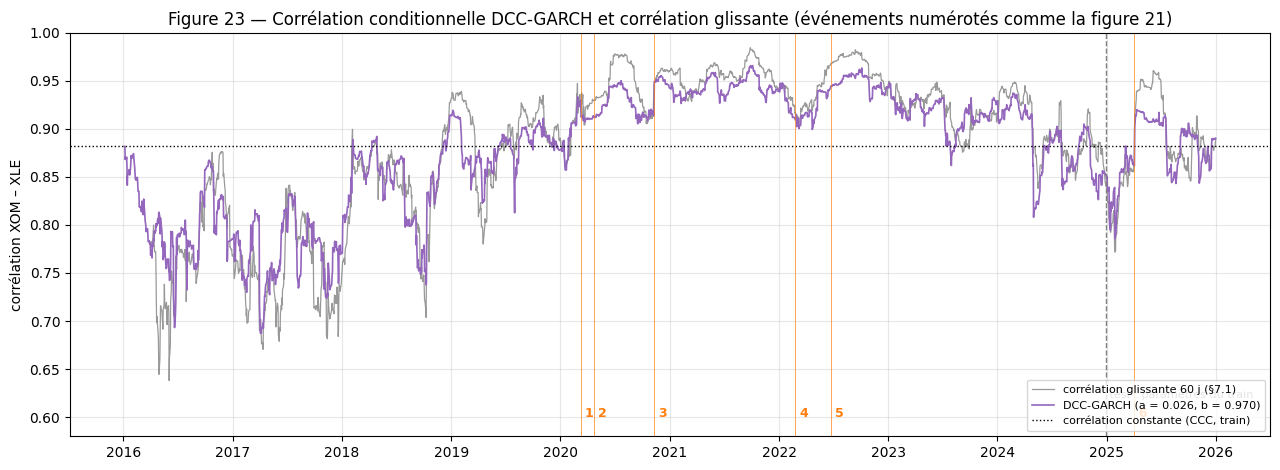

Corrélation entre la série DCC et la corrélation glissante : 0.946


,XOM_ret,XLE_ret
omega,0.0094,0.0180
alpha[1],0.0430,0.0293
gamma[1],0.0421,0.0570
beta[1],0.9353,0.9364
nu,7.4681,8.1382


,statistique,ddl,p-value
train complet,34.3077,6.0000,0.0000
train hors 2020,32.1310,6.0000,0.0000


,moyenne,minimum,date du minimum,maximum,date du maximum
2016-2019,0.8248,0.6872,2017-04-06,0.9194,2019-01-07
2020,0.9224,0.8571,2020-01-21,0.9553,2020-12-03
2021-2024,0.9198,0.8081,2024-05-01,0.9660,2021-10-04
"2025 (test, hors échantillon)",0.8778,0.7858,2025-01-28,0.9201,2025-04-11


,valeur,erreur-type (étape 2 seule)
a,0.0257,0.0065
b,0.9696,0.0078
persistance a + b,0.9952,NaN
demi-vie d'un choc de corrélation (jours),145.3109,NaN
log-vraisemblance DCC (partie corrélation),1824.7496,NaN
log-vraisemblance CCC (a = b = 0),1699.5089,NaN


In [83]:
Zs, dcc_uni = X.dcc_standardized(panel, train.index[-1])
Z_tr = Zs.loc[:train.index[-1]]
dcc = X.dcc_fit(Z_tr.to_numpy())
rho_dcc = X.dcc_correlation(Zs, dcc)
es = {"train complet": X.engle_sheppard(Z_tr.to_numpy(), 5),
      "train hors 2020": X.engle_sheppard(Z_tr[Z_tr.index.year != 2020].to_numpy(), 5)}

dcc_tab = pd.DataFrame({
    "valeur": [dcc["a"], dcc["b"], dcc["a"] + dcc["b"], np.log(0.5) / np.log(dcc["a"] + dcc["b"]),
               dcc["loglik_dcc"], dcc["loglik_ccc"]],
    "erreur-type (étape 2 seule)": [dcc["se_a"], dcc["se_b"], np.nan, np.nan, np.nan, np.nan],
}, index=["a", "b", "persistance a + b", "demi-vie d'un choc de corrélation (jours)",
          "log-vraisemblance DCC (partie corrélation)", "log-vraisemblance CCC (a = b = 0)"])
save_table(dcc_tab, "tab47_dcc")
save_table(pd.DataFrame(es).T, "tab47b_engle_sheppard")
# Résidus standardisés du train exportés : le Rmd y applique sa propre étape 2 (vérification croisée).
save_table(Z_tr.reset_index(drop=True), "tab47c_dcc_residus_train", index=False)
save_table(pd.DataFrame({k: v.params for k, v in dcc_uni.items()}), "tab47d_dcc_garch_univaries")

per = {"2016-2019": ("2016", "2019"), "2020": ("2020", "2020"), "2021-2024": ("2021", "2024"), "2025 (test, hors échantillon)": ("2025", "2025")}
dcc_per = pd.DataFrame({p: {"moyenne": rho_dcc.loc[s:e].mean(), "minimum": rho_dcc.loc[s:e].min(),
                            "date du minimum": rho_dcc.loc[s:e].idxmin().date(), "maximum": rho_dcc.loc[s:e].max(),
                            "date du maximum": rho_dcc.loc[s:e].idxmax().date()} for p, (s, e) in per.items()}).T
save_table(dcc_per, "tab47e_dcc_periodes")

fig, ax = plt.subplots(figsize=(13, 4.8))
ax.plot(rc["XOM – XLE"].index, rc["XOM – XLE"], color="grey", lw=0.9, alpha=0.8, label="corrélation glissante 60 j (§7.1)")
ax.plot(rho_dcc.index, rho_dcc, color="tab:purple", lw=1.2, label=f"DCC-GARCH (a = {dcc['a']:.3f}, b = {dcc['b']:.3f})")
ax.axhline(Z_tr.corr().iloc[0, 1], color="black", ls=":", lw=1, label="corrélation constante (CCC, train)")
ax.axvline(test.index[0], color="grey", ls="--", lw=1)
ax.text(test.index[0], 0.62, " test : paramètres du train", fontsize=8, color="grey")
for k, d in enumerate(X.EVENTS, start=1):
    ax.axvline(pd.Timestamp(d), color="tab:orange", lw=0.7, alpha=0.7)
    ax.annotate(str(k), (pd.Timestamp(d), 0.6), fontsize=9, color="tab:orange", fontweight="bold", xytext=(3, 0), textcoords="offset points")
ax.set_ylim(0.58, 1.0)
ax.set_ylabel("corrélation XOM – XLE")
ax.set_title("Figure 23 — Corrélation conditionnelle DCC-GARCH et corrélation glissante (événements numérotés comme la figure 21)")
ax.grid(alpha=0.3)
ax.legend(fontsize=8, loc="lower right")
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.tight_layout()
save_fig(fig, 23, "dcc_garch")
plt.show()

print("Corrélation entre la série DCC et la corrélation glissante :",
      round(pd.concat([rho_dcc, rc["XOM – XLE"]], axis=1).dropna().corr().iloc[0, 1], 3))
display(pd.DataFrame({k: v.params for k, v in dcc_uni.items()}).round(4))
display(pd.DataFrame(es).T.round(4))
display(dcc_per.round(3))
dcc_tab.round(4)

**Interprétation du DCC-GARCH (tableaux 47 à 47e, figure 23).**

**Étape 1.** Le GJR-t de XOM redonne exactement le §3.3. Celui de XLE est proche : γ = 0,057, ν = 8,1. L'ETF a lui aussi un effet de levier et des queues épaisses.

**Étape 2 : la corrélation est dynamique et très persistante.**

| Paramètre | Valeur | Lecture |
| --- | --- | --- |
| a | 0,026 (erreur-type 0,006) | La corrélation réagit au choc commun de la veille. a est significativement non nul. |
| b | 0,970 (erreur-type 0,008) | La corrélation garde l'essentiel de sa valeur de la veille. |
| a + b | 0,995 | Un choc de corrélation perd la moitié de son effet en **145 jours** de bourse environ. |

- **Le test d'Engle et Sheppard rejette la corrélation constante.**
  - Train : χ²(6) = 34,3, p < 0,0001 ; hors 2020 : χ²(6) = 32,1, p < 0,0001.
  - On rejette H₀ : le lien XOM – XLE varie bien dans le temps, et ce n'est pas un artefact de 2020.
  - La quasi-vraisemblance progresse aussi de 125 points par rapport au modèle CCC, mais ce gain n'est pas un test valide (voir plus haut).
- **La corrélation DCC confirme le §7.1** (corrélation de 0,946 avec la corrélation glissante) :

  | Période | Corrélation DCC moyenne |
  | --- | --- |
  | 2016-2019 | 0,83 |
  | 2020 | 0,92 |
  | 2021-2024 | 0,92 |
  | 2025, hors échantillon | 0,88 (maximum 0,92 le 2025-04-11, juste après la séquence des droits de douane) |

  Elle est plus lisse que la corrélation glissante, car elle pondère tout le passé au lieu de couper à 60 jours. Elle réagit aussi dès le lendemain d'un choc commun, au lieu d'attendre qu'il entre dans la fenêtre.
- **Vérification en R (`rmgarch`, section 6 du Rmd).**
  - `rmgarch` donne a = 0,027 et b = 0,968, avec la même persistance (0,995).
  - L'écart vient uniquement de l'étape 1 : la variance initiale du GARCH diffère, comme au §3d.
  - Appliquée aux mêmes résidus standardisés, notre étape 2 redonne `rmgarch` à 10⁻⁴ près.

**À quoi sert ce résultat ?** Un investisseur qui couvre XOM avec XLE utilise un ratio de couverture β_t = ρ_t σ_XOM,t / σ_XLE,t. Avec une corrélation constante, ce ratio serait faux dans les deux sens :
- trop fort avant 2020 (0,83 en réalité, contre une corrélation constante de 0,88 sur les résidus standardisés du train) ;
- trop faible en 2020-2024 et pendant les crises (0,92 en moyenne, jusqu'à 0,966).

Le DCC donne ce ratio jour par jour, uniquement à partir du passé.